# Лексика власти у Фомы Аквинского: сетевой анализ модели *Opera Maiora*

## Основной расчёт: десять обозначений власти и их ближайшие соседи

**Исследовательская задача.** Описать структуру семантического окружения десяти латинских обозначений власти в корпусе Фомы Аквинского: *dominium, potestas, praelatio, iurisdictio, auctoritas, imperium, principatus, regimen, gubernatio, regnum*.

**Формирование словаря.** Для каждой целевой леммы извлекаются 15 ближайших соседей по косинусному сходству в опубликованной модели *Opera Maiora*. Объединение десяти целевых лемм и всех найденных соседей образует словарь основной сети. Соседи не становятся дополнительными точками для дальнейшего расширения словаря.

**Построение и анализ.** Для всех пар лемм словаря вычисляется косинусное сходство; ребро проводится, если оно не ниже максимального порога из проверяемой сетки 0,30–0,80 (шаг 0,01), при котором граф остаётся связным. Алгоритм Лейдена запускается 50 раз. Для таблиц и рисунков выбирается медоид — реально полученное разбиение, наиболее близкое к средней матрице совместной принадлежности узлов. Дополнительно строятся десять локальных сетей 6–4, матрица сходства целевых лемм и проверки устойчивости при N = 10, 15, 20.

**Воспроизводимость.** В ноутбуке зафиксирован список целевых лемм, параметры расчёта, начальные значения генераторов случайных чисел и SHA-256 файла модели. Результаты записываются в каталоги `figures/` и `tables/` репозитория. Графы сообществ хранятся в `figures/communities/`, все десять локальных сетей — в `figures/local_networks/`, без копий в корне `figures/`. Файл модели хранится в `models/`. Ячейки выполняются последовательно.

**Экспериментальное дополнение.** Раздел 15 содержит диагностику низких частот и практически одинаковых векторов, альтернативный union k-NN-граф, дендрограмму десяти терминов и отдельную проверку сети после исключения низкочастотных нецелевых лемм. Основной расчёт (разделы 1–14) не изменяется. UMAP/HDBSCAN в этом варианте не используются.


## 1. Подготовка среды

In [1]:
import importlib.util, subprocess, sys

REQUIRED = {                 # имя модуля : имя пакета для установки
    "gensim": "gensim",
    "igraph": "igraph",
    "leidenalg": "leidenalg",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",  # сравнение медоидных разбиений по ARI
    "adjustText": "adjustText",    # аккуратное размещение подписей на основной сети
}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]

if missing:
    print("Устанавливаются библиотеки:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Все необходимые библиотеки уже установлены.")

Все необходимые библиотеки уже установлены.


## 2. Параметры, модель и целевые леммы

Список десяти лемм задан в `TARGET_TERMS`. Для основной сети используется `TOP_N = 15`; для проверки устойчивости — `TOP_N_VALUES = (10, 15, 20)`. Параметр `SEED = 42` определяет воспроизводимое расположение узлов на рисунках и разбиения локальных сетей. Для основной сети выполняются 50 запусков Лейдена с начальными значениями 0–49 и выбирается медоидное разбиение. Формирование словаря зависит только от десяти целевых лемм и их соседей.

In [2]:
import hashlib, os, urllib.request

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import seaborn as sns
from adjustText import adjust_text
import igraph as ig
import leidenalg
from gensim.models import KeyedVectors
from gensim.models.fasttext import load_facebook_model
from IPython.display import display, Markdown

# --- Параметры исследования ---------------------------------------------------
SEED = 42                     # раскладка вершин и локальные сети; не выбор основного сообщества
TOP_N = 15                    # число ближайших соседей каждой целевой леммы в основной сети
TOP_N_VALUES = (10, 15, 20)   # изменение числа соседей при проверке устойчивости
N_LEIDEN_RUNS = 50            # 50 запусков Лейдена на каждом варианте сети
THRESHOLD_GRID = np.round(np.arange(0.30, 0.801, 0.01), 2)   # проверяемые пороги
LOCAL_FIRST, LOCAL_SECOND = 6, 4                             # схема локальных сетей 6–4

# --- Каталоги модели и результатов ------------------------------------
# При запуске из notebooks/ результаты сохраняются в корне репозитория.
# При запуске из Google Colab — в текущем рабочем каталоге.
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
MODEL_DIR = os.path.join(ROOT, "models")
FIG_DIR = os.path.join(ROOT, "figures")
TBL_DIR = os.path.join(ROOT, "tables")
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(TBL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

# --- Десять целевых лемм (орфография словаря: u вместо v) ---------
TARGET_TERMS = ["dominium", "potestas", "praelatio", "iurisdictio", "auctoritas",
               "imperium", "principatus", "regimen", "gubernatio", "regnum"]

# Все 45 уникальных пар целевых лемм используются в проверках устойчивости.
from itertools import combinations
KEY_PAIRS = list(combinations(TARGET_TERMS, 2))

MODEL = {"file": os.path.join(MODEL_DIR, "opera-maiora-lemmas_skip_100.bin"),
         "url": "https://embeddings.lila-erc.eu/samples/download/OperaMaiora/opera-maiora-lemmas_skip_100.bin",
         "sha256": "4f973ddb57a9a382b13345c72269c628f10bae1b4b279f26dca9168697b44f5c"}   # контрольная сумма проверена по сохранённому результату

# --- Рисунки -------------------------------------------------------------------
FIG_DPI = 300
MAIN_FONT = {"power": 16, "other": 9}   # основная сеть: подписи разводятся автоматически
COMMUNITY_FONT = {"target": 14, "other": 11}            # отдельные сообщества
LOCAL_FONT = {0: 24, 1: 17, 2: 14}                      # локальные сети: целевая лемма, 1-й и 2-й уровень
N_LABELLED = 0                                          # 0 — подписи только целевых лемм

sns.set_style("white")
plt.rcParams.update({
    "figure.dpi": 120, "font.family": "DejaVu Sans", "font.size": 12,
    "axes.titlesize": 15, "axes.labelsize": 13, "xtick.labelsize": 11,
    "ytick.labelsize": 11, "legend.fontsize": 11,
    "figure.facecolor": "white", "savefig.facecolor": "white",
})
np.random.seed(SEED)


def load_lila_model(info):
    # Загружает двоичную модель fastText проекта LiLa и возвращает векторы её словаря
    # (с частотами лемм) и параметры обучения. Работаем только со словарём модели:
    # для слов вне словаря fastText строит векторы из частей слова, такие векторы не используются.
    if not os.path.exists(info["file"]):
        print(f"Загружается {os.path.basename(info['file'])} (около 770 МБ)…")
        urllib.request.urlretrieve(info["url"], info["file"])
    digest = hashlib.sha256()
    with open(info["file"], "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            digest.update(chunk)
    if info.get("sha256") and digest.hexdigest() != info["sha256"]:
        raise ValueError("Контрольная сумма не совпадает: это другая версия модели.")
    print(f"{os.path.basename(info['file'])}: SHA-256 {digest.hexdigest()}")

    model = load_facebook_model(info["file"])
    keys = model.wv.index_to_key
    kv = KeyedVectors(vector_size=model.wv.vector_size)
    kv.add_vectors(keys, model.wv.vectors[:len(keys)])
    for k in keys:
        kv.set_vecattr(k, "count", model.wv.get_vecattr(k, "count"))
    params = {"Архитектура": "skip-gram" if model.sg else "CBOW",
              "Размерность векторов": model.wv.vector_size, "Контекстное окно": model.window,
              "Минимальная частота": model.min_count, "Эпох обучения": model.epochs,
              "Отрицательных примеров": model.negative,
              "Длина n-грамм символов": f"{model.wv.min_n}–{model.wv.max_n}",
              "Лемм в словаре": len(keys),
              "Словоупотреблений в корпусе": f"{model.corpus_total_words:,}".replace(",", " ")}
    del model
    return kv, params


wv, MODEL_PARAMS = load_lila_model(MODEL)
absent = [t for t in TARGET_TERMS if t not in wv.key_to_index]
if absent:
    raise ValueError("В словаре модели нет лемм: " + ", ".join(absent))
freq = lambda w: wv.get_vecattr(w, "count") if w in wv.key_to_index else "–"
print(f"Модель загружена: {len(wv)} лемм; целевых лемм: {len(TARGET_TERMS)}")

display(pd.DataFrame(MODEL_PARAMS.items(), columns=["Параметр модели", "Значение"]).set_index("Параметр модели"))
display(Markdown("**Десять целевых лемм**"))
display(pd.DataFrame([
    {"Лемма": t, "Частота": freq(t), "Роль": "целевая лемма"}
    for t in TARGET_TERMS
]).set_index("Лемма"))

opera-maiora-lemmas_skip_100.bin: SHA-256 4f973ddb57a9a382b13345c72269c628f10bae1b4b279f26dca9168697b44f5c
Модель загружена: 6724 лемм; целевых лемм: 10


,Значение
Параметр модели,
Архитектура,skip-gram
Размерность векторов,100
Контекстное окно,10
Минимальная частота,5
Эпох обучения,5
Отрицательных примеров,25
Длина n-грамм символов,3–6
Лемм в словаре,6724
Словоупотреблений в корпусе,4 346 955


**Десять целевых лемм**

,Частота,Роль
Лемма,,
dominium,287,целевая лемма
potestas,2527,целевая лемма
praelatio,249,целевая лемма
iurisdictio,97,целевая лемма
auctoritas,1363,целевая лемма
imperium,449,целевая лемма
principatus,160,целевая лемма
regimen,189,целевая лемма
gubernatio,248,целевая лемма


## 3. Вспомогательные функции

В ячейке собраны функции построения сетей, выделения сообществ и рисунков. Её достаточно выполнить.

In [3]:
# ---------------------------------------------------------------------------
# Сохранение рисунков
# ---------------------------------------------------------------------------
def save_figure(fig, name, folder=FIG_DIR):
    # Показывает рисунок в ноутбуке и сохраняет его в PNG.
    os.makedirs(folder, exist_ok=True)
    fig.savefig(os.path.join(folder, name + ".png"), dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


# ---------------------------------------------------------------------------
# Сеть и сообщества
# ---------------------------------------------------------------------------
def build_network(lemmas, similarity, threshold):
    # Соединяет ребром каждую пару лемм, косинусное сходство которых не ниже порога.
    rows, cols = np.triu_indices(len(lemmas), k=1)
    weights = similarity[rows, cols]
    keep = weights >= threshold
    graph = nx.Graph()
    graph.add_nodes_from(lemmas)
    for i, j, w in zip(rows[keep], cols[keep], weights[keep]):
        graph.add_edge(lemmas[i], lemmas[j], weight=float(w))
    return graph


def leiden(graph, seed=SEED):
    # Сообщества алгоритма Лейдена (модулярность, веса рёбер = косинусное сходство).
    # Возвращает словарь «лемма → номер сообщества» и модулярность Q.
    lemmas = list(graph.nodes)
    index = {w: i for i, w in enumerate(lemmas)}
    g = ig.Graph(n=len(lemmas), edges=[(index[u], index[v]) for u, v in graph.edges])
    weights = [graph[u][v]["weight"] for u, v in graph.edges]
    part = leidenalg.find_partition(g, leidenalg.ModularityVertexPartition,
                                    weights=weights, seed=int(seed))
    membership = {lemmas[i]: c for i, c in enumerate(part.membership)}
    return number_communities(membership), g.modularity(part.membership, weights=weights)


def number_communities(membership):
    # Сообщества нумеруются в порядке целевых лемм (сообщество dominium – 1 и т. д.),
    # поэтому номера и цвета не меняются от запуска к запуску.
    new = {}
    for t in TARGET_TERMS:
        if t in membership:  # в локальной сети могут отсутствовать другие целевые леммы
            new.setdefault(membership[t], len(new) + 1)
    for c in sorted(set(membership.values())):
        new.setdefault(c, len(new) + 1)
    return {w: new[c] for w, c in membership.items()}


# ---------------------------------------------------------------------------
# Локальные сети по схеме 6–4
# ---------------------------------------------------------------------------
def local_network_6_4(seed_lemma, first=LOCAL_FIRST, second=LOCAL_SECOND):
    # Целевая лемма → её 6 ближайших соседей (первый уровень)
    # → по 4 ближайших соседа каждого из них (второй уровень).
    graph = nx.Graph()
    graph.add_node(seed_lemma, level=0)
    for word1, sim1 in wv.most_similar(seed_lemma, topn=first):
        graph.add_node(word1, level=1)
        graph.add_edge(seed_lemma, word1, weight=float(sim1), relation="first")
        candidates = [(w, s) for w, s in wv.most_similar(word1, topn=second + 10)
                      if w != seed_lemma][:second]
        for word2, sim2 in candidates:
            if word2 not in graph:
                graph.add_node(word2, level=2)
            if graph.has_edge(word1, word2):
                continue          # связь первого уровня уже есть
            graph.add_edge(word1, word2, weight=float(sim2), relation="second")
    return graph


# ---------------------------------------------------------------------------
# Раскладка рисунков
# ---------------------------------------------------------------------------
def orient(positions, anchor):
    # Отражает раскладку так, чтобы указанная лемма оказалась слева внизу:
    # это делает рисунки сопоставимыми между запусками.
    xs = np.array([p[0] for p in positions.values()])
    ys = np.array([p[1] for p in positions.values()])
    x_mid, y_mid = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
    fx = 1 if positions[anchor][0] <= x_mid else -1
    fy = 1 if positions[anchor][1] <= y_mid else -1
    return {n: ((p[0] - x_mid) * fx + x_mid, (p[1] - y_mid) * fy + y_mid)
            for n, p in positions.items()}


def white_outline(text, width):
    text.set_path_effects([pe.withStroke(linewidth=width, foreground="white")])


# ---------------------------------------------------------------------------
# Рисунок основной сети
# ---------------------------------------------------------------------------
def draw_main_network(graph, membership, colors, positions, labelled, threshold, modularity):
    # Подписи и узлы размещаются независимо: adjustText отодвигает текст,
    # не меняя координат вершин, графа и разбиения на сообщества.
    fig, ax = plt.subplots(figsize=(20, 15))
    span = max(1.0 - threshold, 1e-6)
    for u, v, data in graph.edges(data=True):
        f = (data["weight"] - threshold) / span
        ax.plot([positions[u][0], positions[v][0]], [positions[u][1], positions[v][1]],
                color="#555555", alpha=0.15 + 0.28 * f,
                linewidth=0.45 + 1.20 * f, zorder=1)

    def kind(n):
        return "power" if n in TARGET_TERMS else "other"

    size = {"power": 2050, "other": 280}
    edge = {"power": ("black", 2.2), "other": ("#555555", 0.5)}
    for node in graph.nodes:
        k = kind(node)
        ax.scatter(*positions[node], s=size[k], c=[colors[membership[node]]],
                   alpha=0.91, zorder=3, edgecolors=edge[k][0], linewidths=edge[k][1])

    # Сначала все целевые леммы. Прочие добавляются только если N_LABELLED > 0.
    label_nodes = [n for n in TARGET_TERMS if n in graph]
    label_nodes += sorted(n for n in labelled if n in graph and n not in TARGET_TERMS)
    labels = []
    for node in label_nodes:
        k = kind(node)
        t = ax.text(*positions[node], node.upper() if k == "power" else node,
                    fontsize=MAIN_FONT[k], fontweight="bold" if k == "power" else "normal",
                    ha="center", va="center", zorder=6, color="#171717")
        white_outline(t, {"power": 4.0, "other": 2.5}[k])
        labels.append(t)

    legend = [Line2D([0], [0], marker="o", color="w", label=label, markerfacecolor="white",
                     markeredgecolor="black", markeredgewidth=width, markersize=ms)
              for label, width, ms in [("Целевая лемма", 2.2, 18),
                                       ("Найденный ближайший сосед", 0.5, 9)]]
    for c in sorted(colors):
        targets = [t for t in TARGET_TERMS if membership[t] == c]
        label = f"Сообщество {c}" + (f" ({', '.join(targets)})" if targets else "")
        legend.append(mpatches.Patch(facecolor=colors[c], edgecolor="#333333", label=label))
    ax.legend(handles=legend, loc="upper left", bbox_to_anchor=(1.0, 1.0), framealpha=0.96,
              title="Сообщества (алгоритм Лейдена)", title_fontsize=13,
              borderpad=1, labelspacing=0.9, fontsize=10.5)
    ax.set_title("Сеть дистрибутивного сходства\n"
                 f"{graph.number_of_nodes()} лемм · θ = {threshold:.2f} · "
                 f"{graph.number_of_edges()} рёбер · Q = {modularity:.3f}", fontsize=16, pad=17)
    ax.margins(x=0.17, y=0.17)  # свободное место для смещаемых подписей
    ax.axis("off")

    # Автоматическое устранение наложений. Линии-выноски появляются там,
    # где надпись пришлось отодвинуть от подписываемой вершины.
    if labels:
        adjust_text(
            labels, ax=ax,
            x=[positions[n][0] for n in graph],
            y=[positions[n][1] for n in graph],
            target_x=[positions[n][0] for n in label_nodes],
            target_y=[positions[n][1] for n in label_nodes],
            force_text=(0.6, 0.9), force_static=(0.12, 0.18),
            force_pull=(0.012, 0.012), expand=(1.12, 1.20),
            ensure_inside_axes=True, iter_lim=350,
            min_arrow_len=12,
            arrowprops={"arrowstyle": "-", "color": "#777777", "lw": 0.75},
        )
    return fig


# ---------------------------------------------------------------------------
# Рисунок одного сообщества
# ---------------------------------------------------------------------------
def draw_community(graph, membership, colors, community, threshold):
    nodes = [n for n in graph.nodes if membership[n] == community]
    sub = graph.subgraph(nodes).copy()
    targets = [t for t in TARGET_TERMS if t in sub]
    anchor = targets[0] if targets else max(sub.degree, key=lambda item: item[1])[0]
    k = 1.6 if sub.number_of_nodes() <= 25 else 1.2
    pos = orient(nx.spring_layout(sub, k=k, iterations=500, weight="weight", seed=SEED), anchor)
    fig, ax = plt.subplots(figsize=(14, 11))
    weights = [d["weight"] for _, _, d in sub.edges(data=True)]
    w_min = min(weights) if weights else threshold
    span = max((max(weights) - w_min) if weights else 0.0, 1e-6)
    for u, v, d in sub.edges(data=True):
        f = (d["weight"] - w_min) / span
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#666666",
                alpha=0.35 + 0.50 * f, linewidth=0.8 + 2.5 * f, zorder=1)
    degree = dict(sub.degree)
    for node in sub.nodes:
        is_target = node in TARGET_TERMS
        ax.scatter(*pos[node], s=1900 if is_target else 260 + 22 * degree[node],
                   c=[colors[community]], alpha=0.92, zorder=2,
                   edgecolors="black" if is_target else "#555555",
                   linewidths=2.0 if is_target else 0.6)
        t = ax.text(*pos[node], node.upper() if is_target else node,
                    fontsize=COMMUNITY_FONT["target"] if is_target else COMMUNITY_FONT["other"],
                    fontweight="bold" if is_target else "normal",
                    ha="center", va="center", zorder=3)
        white_outline(t, 3 if is_target else 2)
    ax.set_title(f"Сообщество {community}: {', '.join(targets) or 'нет целевых лемм'}\n"
                 f"{sub.number_of_nodes()} узлов · {sub.number_of_edges()} внутренних рёбер",
                 fontsize=15, pad=16)
    ax.axis("off")
    return fig, anchor


# ---------------------------------------------------------------------------
# Рисунок локальной сети 6–4
# ---------------------------------------------------------------------------
def draw_local_network(seed_lemma, graph):
    # Цвет узла — сообщество внутри локальной сети, выделенное Лейденом.
    # Двухуровневая схема 6–4 задаёт рёбра заранее, поэтому эти сообщества
    # служат только для наглядного чтения локального окружения леммы.
    group_of, _ = leiden(graph, seed=SEED)
    group_ids = sorted(set(group_of.values()))
    palette = sns.color_palette("Set2", len(group_ids))
    colors = {c: palette[i] for i, c in enumerate(group_ids)}
    pos = orient(nx.spring_layout(graph, k=1.35, iterations=600, weight="weight", seed=SEED),
                 seed_lemma)
    fig, ax = plt.subplots(figsize=(15, 11))
    weights = [d["weight"] for _, _, d in graph.edges(data=True)]
    w_min, span = min(weights), max(max(weights) - min(weights), 1e-6)
    for u, v, d in graph.edges(data=True):
        f = (d["weight"] - w_min) / span
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#555555",
                alpha=0.35 + 0.55 * f,
                linewidth=(1.6 if d["relation"] == "first" else 0.8) + 2.2 * f, zorder=1)
    for node in graph.nodes:
        level = graph.nodes[node]["level"]
        ax.scatter(*pos[node], s={0: 4200, 1: 2400, 2: 1000}[level],
                   c=[colors[group_of[node]]], edgecolors="black",
                   linewidths=2.5 if level == 0 else 1.2, alpha=0.94, zorder=2)
        t = ax.text(*pos[node], node.upper() if level == 0 else node,
                    fontsize=LOCAL_FONT[level],
                    fontweight="bold" if level <= 1 else "normal",
                    ha="center", va="center", zorder=3)
        white_outline(t, 3 if level <= 1 else 2)
    ax.set_title(f"Локальная сеть {seed_lemma.upper()} по схеме 6–4\n"
                 f"{graph.number_of_nodes()} узлов · {graph.number_of_edges()} рёбер · без порога θ",
                 fontsize=16, pad=18)
    ax.axis("off")
    return fig


# ---------------------------------------------------------------------------
# Проверки устойчивости и выбор медоида основного разбиения
# ---------------------------------------------------------------------------
def network_lemmas(top_n):
    # Целевые леммы и их top_n ближайших соседей — узлы сети.
    lemmas = set(TARGET_TERMS)
    for term in TARGET_TERMS:
        lemmas.update(w for w, _ in wv.most_similar(term, topn=top_n))
    return sorted(lemmas)


def similarity_matrix(lemmas):
    v = np.array([wv[w] for w in lemmas], dtype=np.float64)
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    return v @ v.T


def connectivity_threshold(lemmas, similarity):
    # Наибольший порог, при котором сеть остаётся связной (критерий ноутбука 1).
    connected = [t for t in THRESHOLD_GRID
                 if nx.is_connected(build_network(lemmas, similarity, float(t)))]
    return float(max(connected))


def co_membership(runs):
    # Число запусков, в которых две целевые леммы входят в одно сообщество.
    # В runs хранятся сами разбиения: они повторно используются для выбора медоида.
    counts = pd.DataFrame(0, index=TARGET_TERMS, columns=TARGET_TERMS)
    for membership, _ in runs:
        labels = np.array([membership[t] for t in TARGET_TERMS])
        counts += (labels[:, None] == labels[None, :]).astype(int)
    return counts


def partition_medoid(graph, runs):
    """Выбор реально полученного разбиения, наиболее близкого к остальным.

    Расстояние между разбиениями = доля *всех* пар узлов, у которых не
    совпадает ответ «в одном сообществе или в разных». Номера и названия
    самих сообществ на расстояние не влияют.

    Среднее расстояние до всех запусков эквивалентно расстоянию до
    матрицы средних частот совместной принадлежности всех пар узлов.
    При равном результате выбирается Q, ближайшее к медиане Q,
    затем меньший индекс (seed). Новых «усреднённых» сообществ не создаём.
    """
    nodes = list(graph.nodes())
    i, j = np.triu_indices(len(nodes), k=1)
    signatures = np.array([
        np.array([m[node] for node in nodes])[i] ==
        np.array([m[node] for node in nodes])[j]
        for m, _ in runs
    ], dtype=bool)
    consensus = signatures.mean(axis=0)
    distances = np.abs(signatures - consensus).mean(axis=1)
    q_values = np.array([q for _, q in runs], dtype=float)
    q_median = float(np.median(q_values))
    selected = min(range(len(runs)),
                   key=lambda k: (round(float(distances[k]), 12),
                                  abs(float(q_values[k]) - q_median), k))
    return selected, distances




def save_table(df, name):
    """Сохраняет таблицу в UTF-8 CSV; каталог tables/ не делится на типы результатов."""
    os.makedirs(TBL_DIR, exist_ok=True)
    path = os.path.join(TBL_DIR, name + ".csv")
    df.to_csv(path, encoding="utf-8-sig")
    print("Сохранена таблица:", path)

print("Функции готовы: сети, рисунки, проверки устойчивости и медоид.")

Функции готовы: сети, рисунки, проверки устойчивости и медоид.


## 4. Фоновое распределение косинусного сходства

Чтобы понимать, какое значение сходства можно считать высоким, сходство рассчитывается для **всех** пар лемм словаря модели. Среднее, стандартное отклонение и перцентили приводятся в разделе «Материалы и методы»; по среднему и стандартному отклонению в разделе 11 сходство пар выражается в стандартных отклонениях от фона (z).

**Роль для статьи:** шкала для оценки сходства. Без фона нельзя сказать, высоко ли сходство 0,6; по среднему и стандартному отклонению в разделе 11 сходство пар выражается в z, а в разделе 6 указывается положение порога.

In [4]:
vectors = wv.get_normed_vectors()
parts = []
for start in range(0, len(wv), 1000):            # считаем блоками, чтобы хватило памяти
    block = vectors[start:start + 1000] @ vectors.T
    for i in range(block.shape[0]):
        parts.append(block[i, start + i + 1:])     # только пары «лемма – следующие леммы»
all_similarities = np.concatenate(parts)
del parts

mean_sim, std_sim = float(all_similarities.mean()), float(all_similarities.std())
p95, p99 = np.percentile(all_similarities, [95, 99])

display(pd.DataFrame([
    ("Число уникальных пар", f"{len(all_similarities):,}".replace(",", " ")),
    ("Среднее", f"{mean_sim:.4f}"),
    ("Стандартное отклонение", f"{std_sim:.4f}"),
    ("95-й перцентиль", f"{p95:.4f}"),
    ("99-й перцентиль", f"{p99:.4f}"),
], columns=["Показатель", "Значение"]).set_index("Показатель"))

,Значение
Показатель,
Число уникальных пар,22 602 726
Среднее,0.2792
Стандартное отклонение,0.1085
95-й перцентиль,0.4642
99-й перцентиль,0.5464


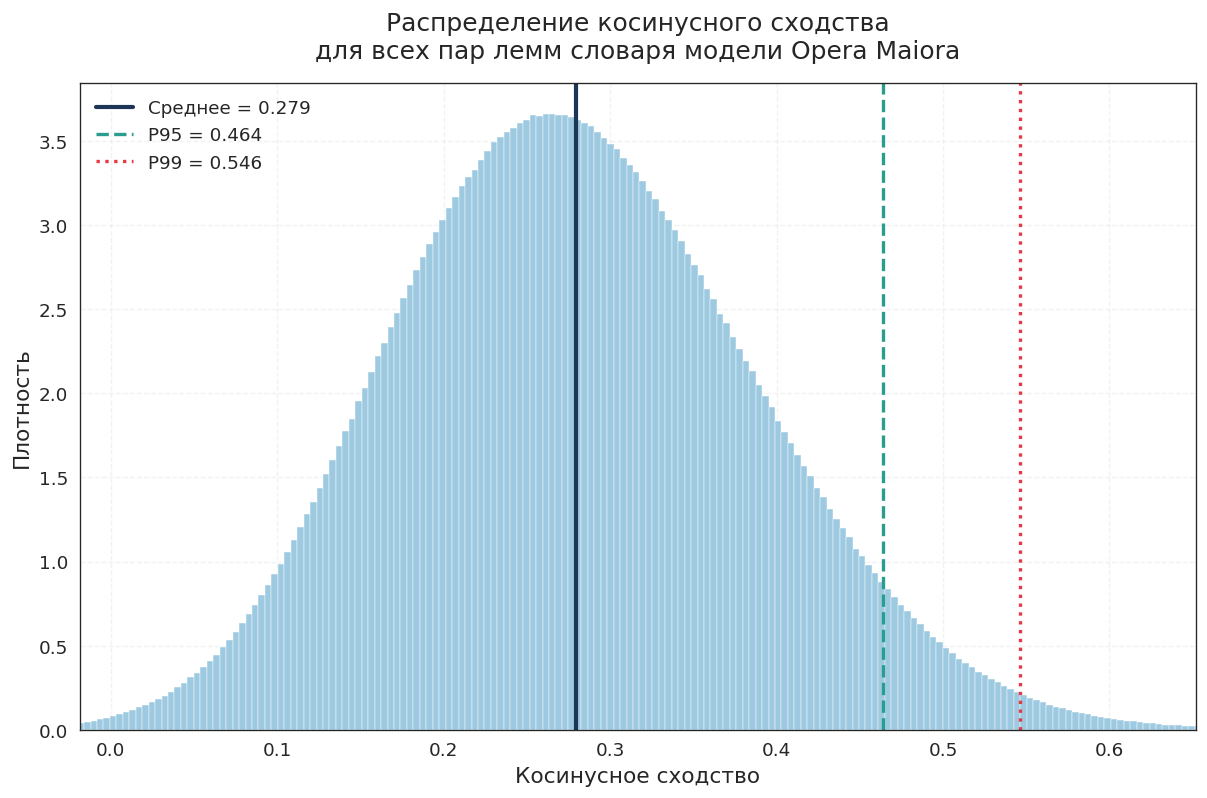

In [5]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.hist(all_similarities, bins=300, density=True, color="#9ecae1", edgecolor="white", linewidth=0.25)
ax.axvline(mean_sim, color="#1d3557", linewidth=2.5, label=f"Среднее = {mean_sim:.3f}")
ax.axvline(p95, color="#2a9d8f", linewidth=2, linestyle="--", label=f"P95 = {p95:.3f}")
ax.axvline(p99, color="#e63946", linewidth=2, linestyle=":", label=f"P99 = {p99:.3f}")
ax.set_xlabel("Косинусное сходство")
ax.set_ylabel("Плотность")
ax.set_title("Распределение косинусного сходства\nдля всех пар лемм словаря модели Opera Maiora", pad=15)
ax.grid(True, linestyle="--", alpha=0.25)
ax.legend(frameon=False)
ax.set_xlim(*np.percentile(all_similarities, [0.1, 99.9]))
save_figure(fig, "cosine_distribution")

## 5. Ближайшие соседи и формирование словаря сети

Для каждой из десяти целевых лемм отбираются пятнадцать ближайших соседей по косинусному сходству. Отбор не предполагает тематической или морфологической фильтрации. Объединение этих списков с целевыми леммами образует словарь сети. Для найденных соседей дополнительный поиск не выполняется. Таблица происхождения узлов показывает, в списке соседей какой целевой леммы обнаружено каждое слово.

In [6]:
neighbours = {term: wv.most_similar(term, topn=TOP_N) for term in TARGET_TERMS}

display(Markdown("**Пятнадцать ближайших соседей десяти целевых лемм**"))
display(pd.DataFrame([
    {"Лемма": term, "Частота": freq(term),
     "Ближайшие соседи (косинусное сходство)": ", ".join(f"{w} {s:.3f}" for w, s in neighbours[term])}
    for term in TARGET_TERMS
]).set_index("Лемма").style.set_properties(**{"text-align": "left", "white-space": "normal"}))

# Словарь основной сети: десять целевых лемм и по 15 соседей каждой
lemmas = sorted(set(TARGET_TERMS) | {w for term in TARGET_TERMS for w, _ in neighbours[term]})
unit = np.array([wv[w] for w in lemmas], dtype=np.float64)
unit /= np.linalg.norm(unit, axis=1, keepdims=True)
similarity = unit @ unit.T
print(f"Словарь основной сети: {len(lemmas)} лемм; целевых = {len(TARGET_TERMS)}, "
      f"соседей вне набора целевых лемм = {len(set(lemmas) - set(TARGET_TERMS))}")
assert set(TARGET_TERMS).issubset(lemmas)
assert len(lemmas) <= len(TARGET_TERMS) * (TOP_N + 1)

# Проверяемое происхождение каждого узла: какие из десяти списков Top-15 включили его.
# Эта таблица документирует происхождение узлов и не изменяет их состав.
node_sources = pd.DataFrame([
    {"Лемма": word,
     "Целевая лемма": "да" if word in TARGET_TERMS else "нет",
     "В скольких списках Top-15": sum(word in {w for w, _ in neighbours[t]} for t in TARGET_TERMS),
     "Найдена среди соседей целевых лемм": ", ".join(t for t in TARGET_TERMS
         if word in {w for w, _ in neighbours[t]}) or "–"}
    for word in lemmas
]).set_index("Лемма")
save_table(node_sources, "network_node_sources")

neighbour_table = pd.DataFrame([
    {"Целевая лемма": term, "Ранг": i, "Сосед": word,
     "Косинусное сходство": float(score)}
    for term in TARGET_TERMS
    for i, (word, score) in enumerate(neighbours[term], 1)
])
save_table(neighbour_table, "top15_neighbors")


**Пятнадцать ближайших соседей десяти целевых лемм**

,Частота,Ближайшие соседи (косинусное сходство)
Лемма,,
dominium,287,"seruitus 0.684, seruus 0.682, dominor 0.658, coerceo 0.633, potestas 0.632, seruitium 0.615, dominatio 0.611, conseruus 0.599, despoticus 0.595, usurpo 0.593, iurisconsultus 0.593, mercatio 0.584, tyrannicus 0.572, patrimonium 0.570, latrocinium 0.568"
potestas,2527,"iurisdictio 0.665, eximo 0.645, minister 0.643, dominium 0.632, ecclesia 0.628, possum 0.624, episcopatus 0.622, arbiter 0.620, resigno 0.620, sacerdotalis 0.620, ordinatio 0.617, ordinarius 0.617, regalis 0.616, inuincibilis 0.615, iudiciarius 0.614"
praelatio,249,"celatio 0.734, subiectio 0.712, praefero 0.671, uelatio 0.657, plebeius 0.657, ordinatio 0.655, praeficio 0.655, praepono 0.654, ordinarius 0.648, tyrannicus 0.644, officium 0.638, primatus 0.634, procuratio 0.632, is 0.631, episcopatus 0.628"
iurisdictio,97,"degrado 0.761, excommunicatio 0.726, clauis 0.720, forum 0.711, episcopus 0.699, laicus 0.698, absolutio 0.696, parochialis 0.679, subdiaconatus 0.672, indulgentia 0.669, ordinarius 0.669, excommunico 0.667, potestas 0.665, diaconatus 0.662, uicarius 0.660"
auctoritas,1363,"subauctoritas 0.870, auctoritatiuus 0.772, induco 0.695, assertiuus 0.671, solutio 0.668, apostolicus 0.662, declaratio 0.659, tractator 0.654, obiectio 0.653, expositio 0.653, probatio 0.652, ceterum 0.649, aio 0.645, improbatio 0.642, auctor 0.640"
imperium,449,"impero 0.794, imperatiuus 0.727, obedio 0.724, despoticus 0.718, exequor 0.695, nutus 0.646, imperitus 0.639, motiuus 0.631, subiaceo 0.630, regalis 0.616, elicitiuus 0.607, persuasibilis 0.594, uis 0.583, potestas 0.580, ordinatio 0.579"
principatus,160,"dominatio 0.788, principor 0.784, princeps 0.758, despoticus 0.747, prouincia 0.739, archangelus 0.729, dominatiuus 0.720, regalis 0.708, optimas 0.701, aristocratia 0.678, michael 0.665, regnatiuus 0.653, regimen 0.646, tyrannicus 0.631, praesideo 0.629"
regimen,189,"praeficio 0.738, gubernatiuus 0.713, gubernatio 0.705, aristocratia 0.703, optimas 0.696, regitiuus 0.686, ciuitas 0.683, rector 0.668, tyrannicus 0.668, regius 0.665, subdo 0.665, ordinator 0.664, regalis 0.664, ordinatio 0.661, regnatiuus 0.660"
gubernatio,248,"guberno 0.882, gubernatiuus 0.867, gubernator 0.863, gubernatorius 0.781, ordinator 0.762, prouisor 0.733, regimen 0.705, prouidentia 0.705, ordinatio 0.701, coordinatio 0.698, praeficio 0.695, prouisio 0.689, praesideo 0.677, prouidus 0.673, aristocratia 0.671"


Словарь основной сети: 122 лемм; целевых = 10, соседей вне набора целевых лемм = 112
Сохранена таблица: ..\tables\network_node_sources.csv
Сохранена таблица: ..\tables\top15_neighbors.csv


## 6. Выбор порога основной сети

**Критерий связности.** Из значений косинусного сходства на сетке от 0,30 до 0,80 с шагом 0,01 выбирается максимальное, при котором все узлы входят в одну связную компоненту. Порог определяется до кластеризации: для его выбора используются количество рёбер и размер наибольшей компоненты, но не модулярность отдельного запуска Лейдена.

Выбранный порог θ = 0.59; при θ = 0.60 компонент: 2
θ в стандартных отклонениях от фона: 2.87; 99-й перцентиль фона: 0.5464
При θ = 0.59: рёбер 715, плотность 0.097


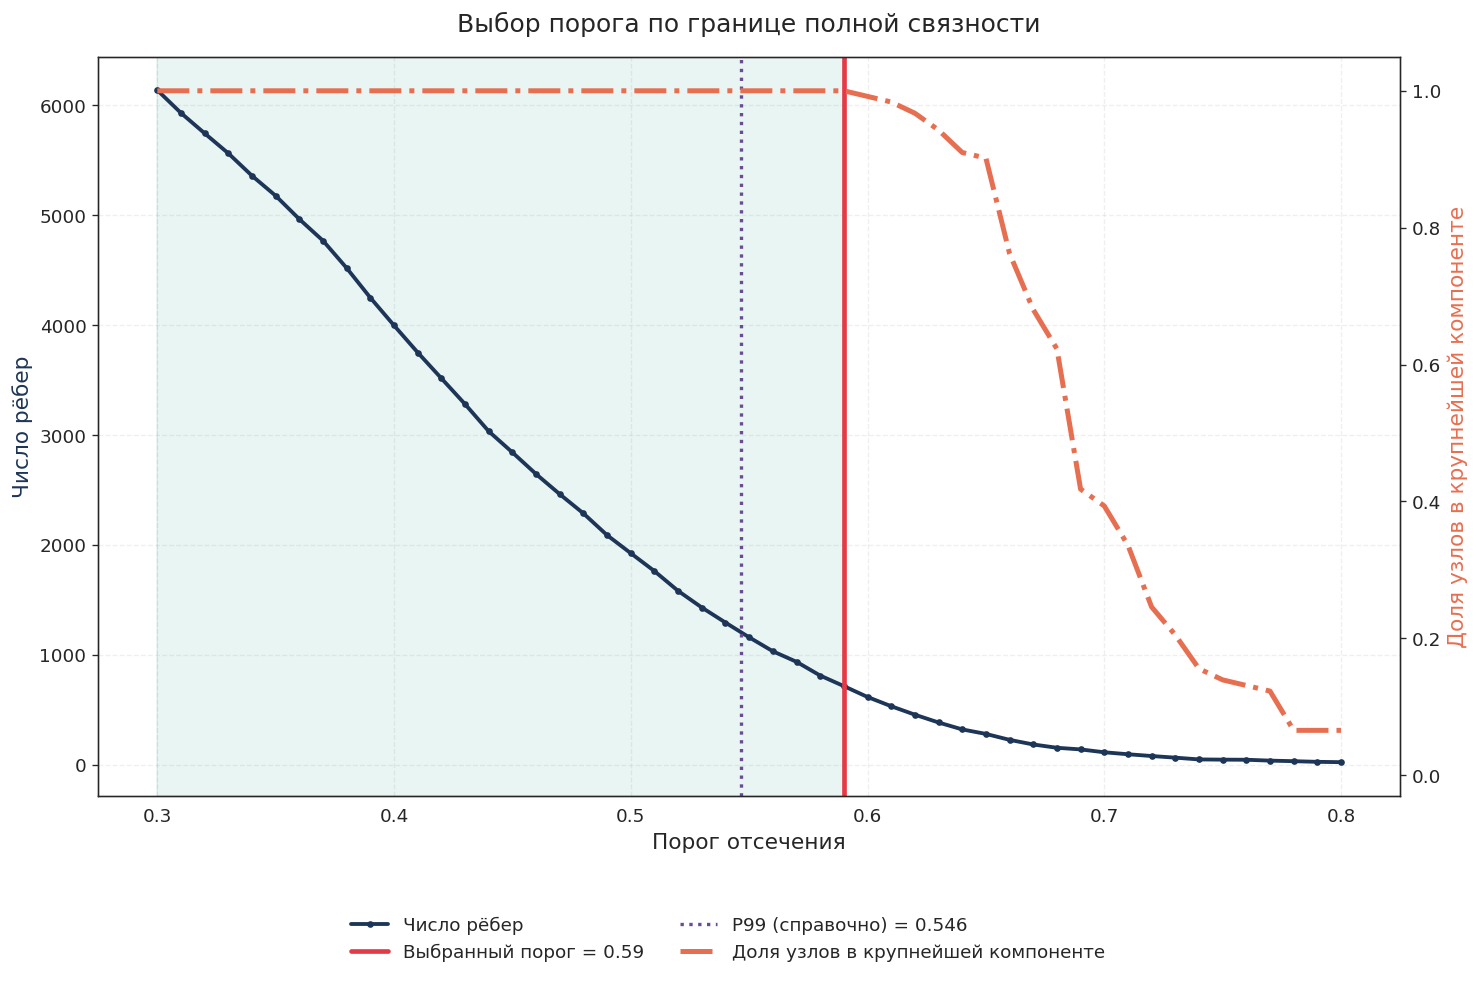

Сохранена таблица: ..\tables\threshold_scan.csv


In [7]:
scan = []
for threshold in THRESHOLD_GRID:
    g = build_network(lemmas, similarity, float(threshold))
    largest = max(len(c) for c in nx.connected_components(g))
    scan.append({"Порог": float(threshold), "Рёбер": g.number_of_edges(),
                 "Плотность": nx.density(g),
                 "Компонент": nx.number_connected_components(g),
                 "Доля лемм в крупнейшей компоненте": largest / len(lemmas)})
scan = pd.DataFrame(scan)

THRESHOLD = float(scan.loc[scan["Компонент"] == 1, "Порог"].max())
row = lambda t: scan.loc[np.isclose(scan["Порог"], t)].iloc[0]
chosen, after = row(THRESHOLD), row(round(THRESHOLD + 0.01, 2))
print(f"Выбранный порог θ = {THRESHOLD:.2f}; при θ = {THRESHOLD + 0.01:.2f} компонент: {int(after['Компонент'])}")
print(f"θ в стандартных отклонениях от фона: {(THRESHOLD - mean_sim) / std_sim:.2f}; "
      f"99-й перцентиль фона: {p99:.4f}")
print(f"При θ = {THRESHOLD:.2f}: рёбер {int(chosen['Рёбер'])}, плотность {chosen['Плотность']:.3f}")

fig, ax1 = plt.subplots(figsize=(14, 8))
ax2 = ax1.twinx()
ax1.axvspan(THRESHOLD_GRID[0], THRESHOLD, color="#2a9d8f", alpha=0.10)
ax1.plot(scan["Порог"], scan["Рёбер"], color="#1d3557", marker="o",
         markersize=3, linewidth=2.3, label="Число рёбер")
ax2.plot(scan["Порог"], scan["Доля лемм в крупнейшей компоненте"],
         color="#e76f51", linestyle="-.", linewidth=3,
         label="Доля узлов в крупнейшей компоненте")
ax1.axvline(THRESHOLD, color="#e63946", linewidth=2.8,
            label=f"Выбранный порог = {THRESHOLD:.2f}")
ax1.axvline(p99, color="#6a4c93", linestyle=":", linewidth=2.0,
            label=f"P99 (справочно) = {p99:.3f}")
ax1.set_xlabel("Порог отсечения")
ax1.set_ylabel("Число рёбер", color="#1d3557")
ax2.set_ylabel("Доля узлов в крупнейшей компоненте", color="#e76f51")
ax2.set_ylim(-0.03, 1.05)
ax1.grid(True, linestyle="--", alpha=0.3)
ax1.set_title("Выбор порога по границе полной связности", pad=15)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=2,
           frameon=False, bbox_to_anchor=(0.5, -0.08))
save_figure(fig, "threshold_selection")
save_table(scan.set_index("Порог"), "threshold_scan")

## 7. Основная сеть: алгоритм Лейдена, медоид и сообщества

На построенной сети выполняются 50 запусков Лейдена с оптимизацией модулярности. Медоид выбирается из этих разбиений по минимальному среднему расхождению с матрицей совместной принадлежности всех пар узлов за 50 запусков (при равенстве — по близости модулярности к медиане). Для таблиц и рисунков используется одно выбранное разбиение, а не усреднённая искусственная классификация.

Нумерация сообществ задаётся порядком целевых лемм в `TARGET_TERMS`. Она служит для оформления таблиц и не имеет самостоятельного содержательного значения.

In [8]:
G = build_network(lemmas, similarity, THRESHOLD)
base_runs = [leiden(G, seed=s) for s in range(N_LEIDEN_RUNS)]
medoid_seed, medoid_distances = partition_medoid(G, base_runs)
membership, Q = base_runs[medoid_seed]
communities = sorted(set(membership.values()))

print(f"Основная сеть: {G.number_of_nodes()} узлов, {G.number_of_edges()} рёбер, θ = {THRESHOLD:.2f}")
print(f"Медоид из {N_LEIDEN_RUNS} запусков: seed={medoid_seed}, "
      f"сообществ={len(communities)}, Q={Q:.3f}, "
      f"средняя доля расхождений={medoid_distances[medoid_seed]:.4f}")

community_table = pd.DataFrame([
    {"Сообщество": c,
     "Целевые леммы": ", ".join(t for t in TARGET_TERMS if membership[t] == c),
     "Число лемм": sum(1 for n in G if membership[n] == c),
     "Все леммы сообщества": ", ".join(sorted(n for n in G if membership[n] == c))}
    for c in communities
]).set_index("Сообщество")
display(Markdown("**Сообщества основной сети по медоиду (полный состав)**"))
display(community_table.style.set_properties(**{"text-align": "left", "white-space": "normal"}))
save_table(community_table, "communities_medoid")

target_community_table = pd.DataFrame([
    {"Лемма": t, "Тип": "целевая лемма власти",
     "Частота": freq(t), "Сообщество": membership[t]}
    for t in TARGET_TERMS
]).set_index("Лемма")
save_table(target_community_table, "target_communities_medoid")

Основная сеть: 122 узлов, 715 рёбер, θ = 0.59
Медоид из 50 запусков: seed=0, сообществ=7, Q=0.495, средняя доля расхождений=0.0133


**Сообщества основной сети по медоиду (полный состав)**

,Целевые леммы,Число лемм,Все леммы сообщества
Сообщество,,,
1,dominium,13,"coerceo, conseruus, dominium, dominor, iurisconsultus, latrocinium, mercatio, plebeius, seruitium, seruitus, seruus, subiectio, usurpo"
2,"potestas, praelatio, iurisdictio",34,"absolutio, arbiter, celatio, clauis, degrado, diaconatus, ecclesia, episcopatus, episcopus, excommunicatio, excommunico, eximo, forum, indulgentia, inuincibilis, is, iudiciarius, iurisdictio, laicus, minister, officium, ordinarius, parochialis, patrimonium, possum, potestas, praefero, praelatio, procuratio, resigno, sacerdotalis, subdiaconatus, uelatio, uicarius"
3,auctoritas,16,"aio, apostolicus, assertiuus, auctor, auctoritas, auctoritatiuus, ceterum, declaratio, expositio, improbatio, induco, obiectio, probatio, solutio, subauctoritas, tractator"
4,imperium,11,"elicitiuus, exequor, imperatiuus, imperitus, imperium, impero, motiuus, nutus, obedio, persuasibilis, uis"
5,"principatus, regimen",23,"archangelus, aristocratia, ciuitas, despoticus, dominatio, dominatiuus, michael, optimas, persa, praepono, primatus, princeps, principatus, principor, prouincia, rector, regalis, regimen, regitiuus, regius, regnatiuus, rex, tyrannicus"
6,gubernatio,16,"coordinatio, gubernatio, gubernatiuus, gubernator, gubernatorius, guberno, ordinatio, ordinator, praeficio, praesideo, prouidentia, prouidus, prouisio, prouisor, subdo, subiaceo"
7,regnum,9,"aperio, iechonias, ierusalem, introeo, introitus, intromitto, possideo, regno, regnum"


Сохранена таблица: ..\tables\communities_medoid.csv
Сохранена таблица: ..\tables\target_communities_medoid.csv


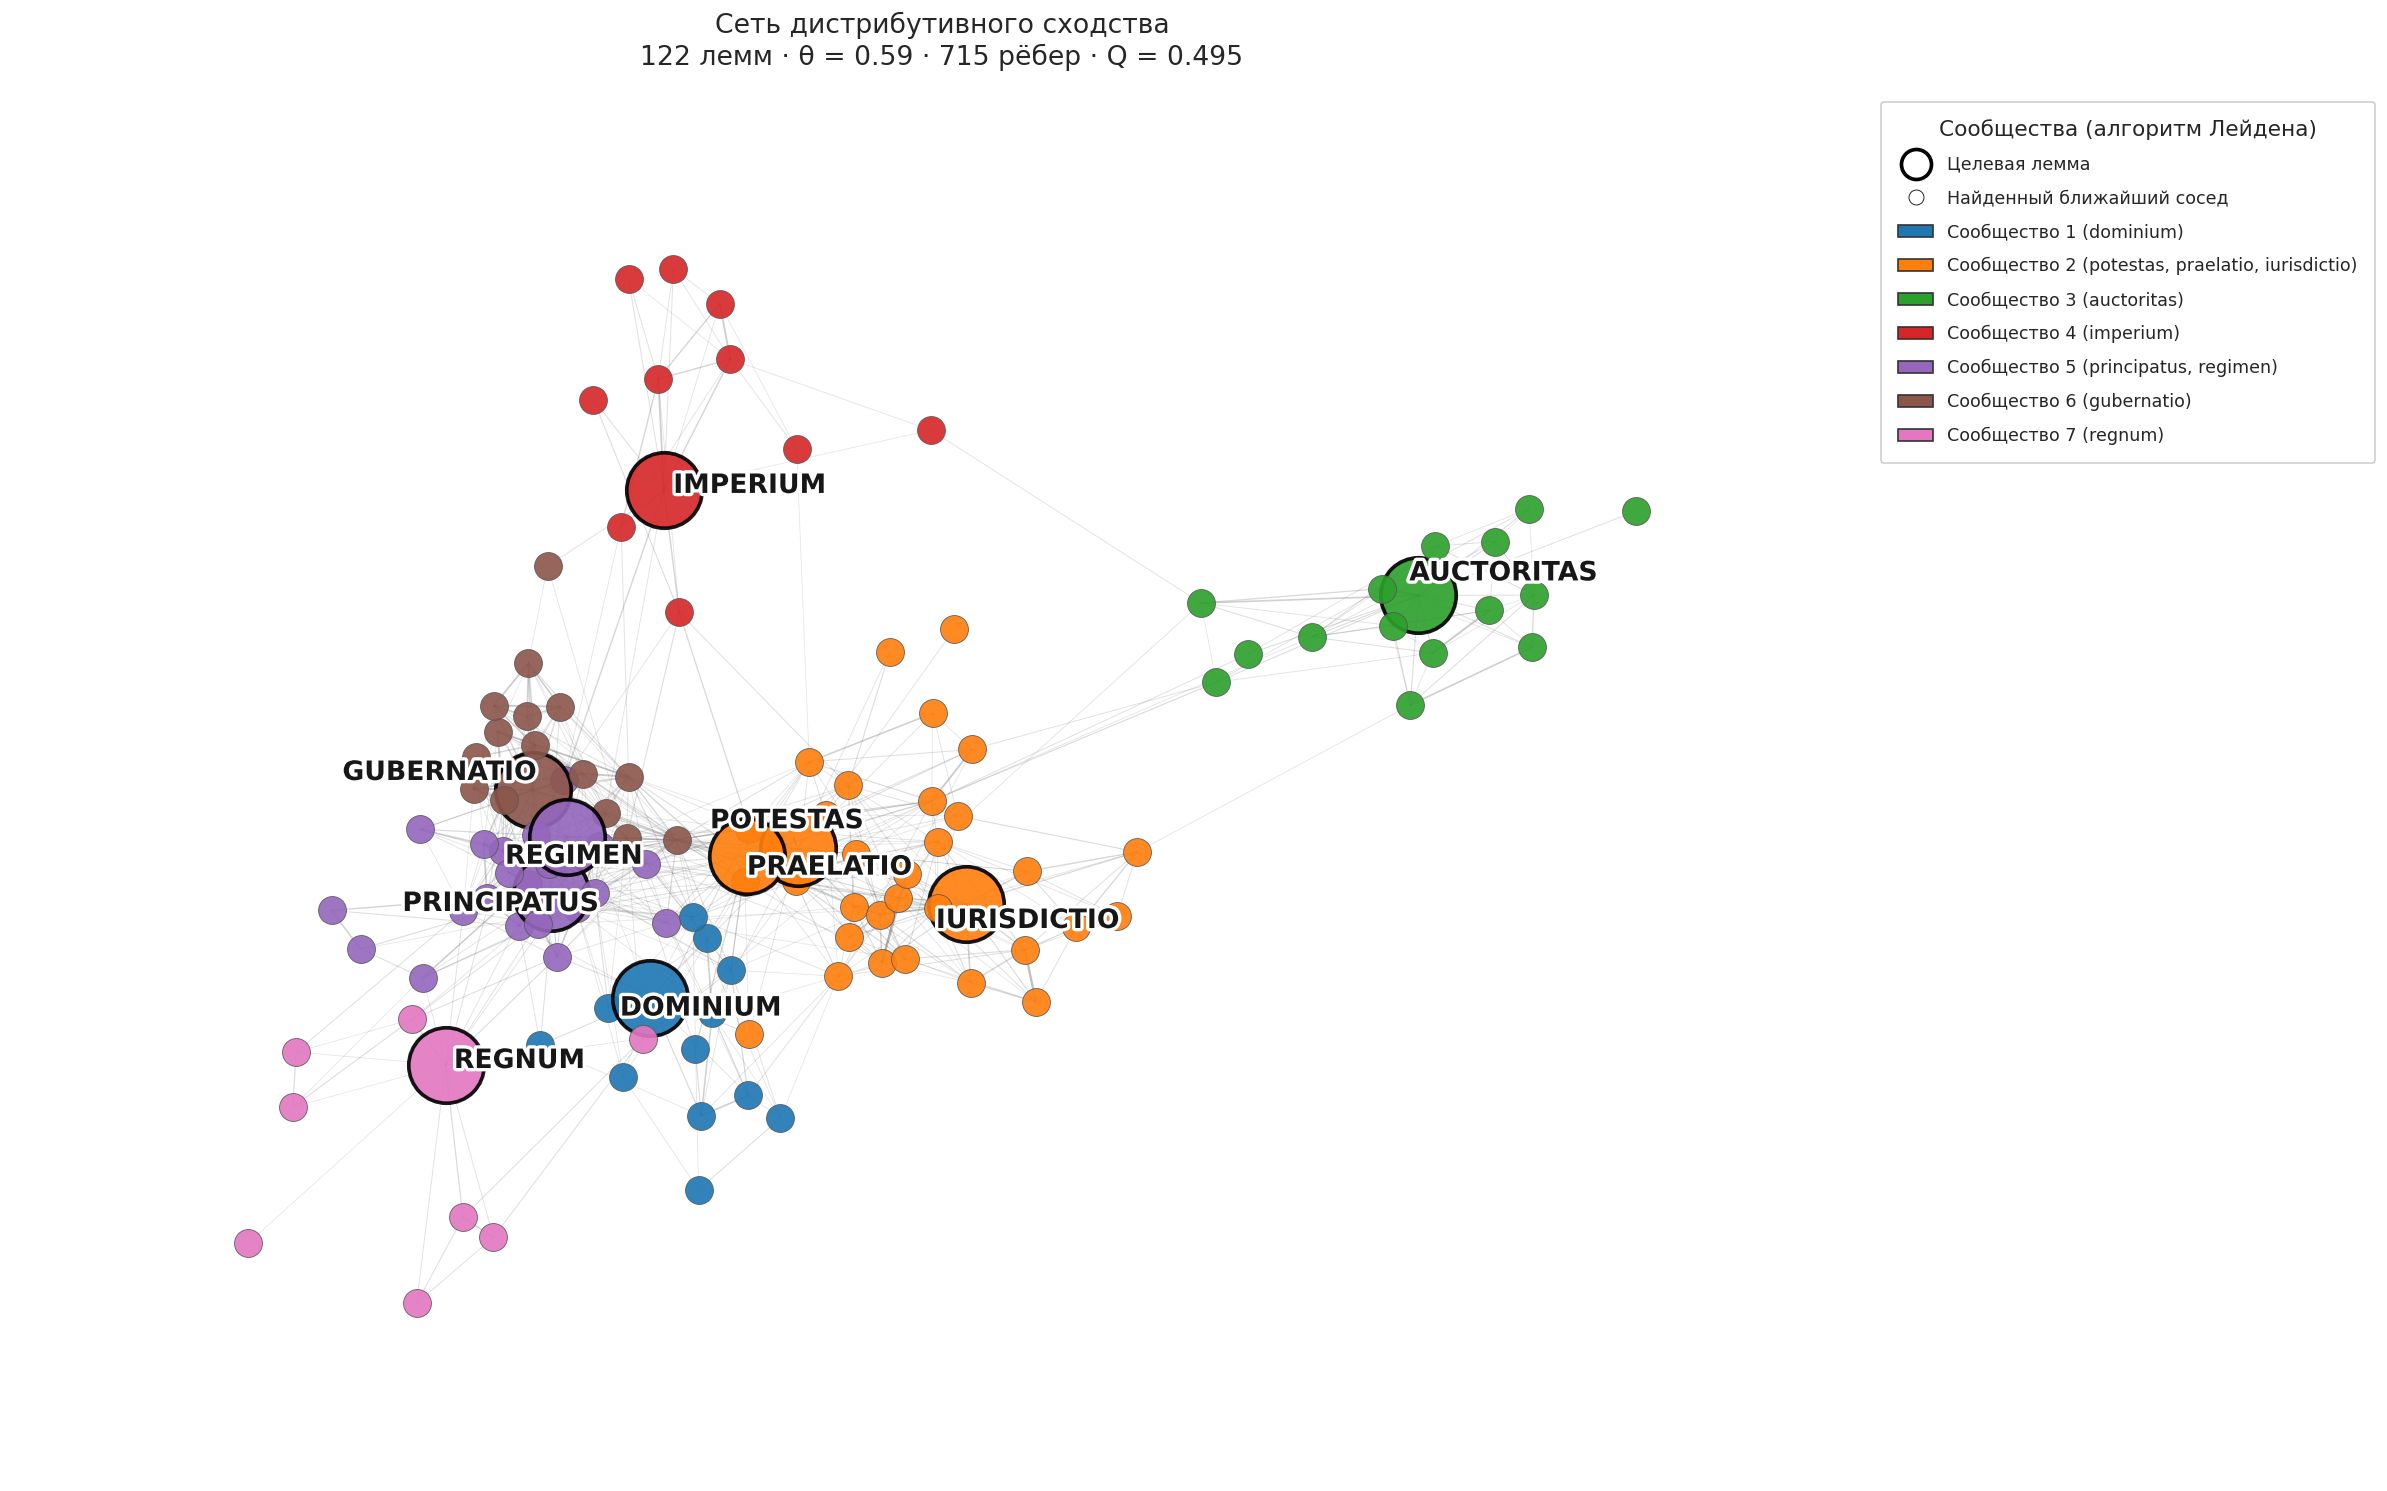

In [9]:
palette = sns.color_palette("tab10" if len(communities) <= 10 else "tab20", len(communities))
community_colors = {c: palette[i] for i, c in enumerate(communities)}

# По умолчанию на общем рисунке только 10 целевых лемм.
# При N_LABELLED > 0 добавляются самые частотные прочие леммы.
labelled = set(sorted((n for n in G if n not in TARGET_TERMS), key=lambda n: -freq(n))[:N_LABELLED])
positions = orient(nx.spring_layout(G, k=1.2, iterations=500, weight="weight", seed=SEED),
                   TARGET_TERMS[0])

fig = draw_main_network(G, membership, community_colors, positions, labelled, THRESHOLD, Q)
save_figure(fig, "figure_1_network")

## 8. Отдельные рисунки сообществ медоидного разбиения

Графы всех семи сообществ сохраняются только в `figures/communities/`, по одному PNG на сообщество. В статье использованы сообщества *potestas – praelatio – iurisdictio* (Рисунок 3, `community_medoid_2_potestas.png`) и *regimen – principatus* (Рисунок 5, `community_medoid_5_principatus.png`). Эти изображения построены из основной пороговой сети, в отличие от локальных сетей 6–4.


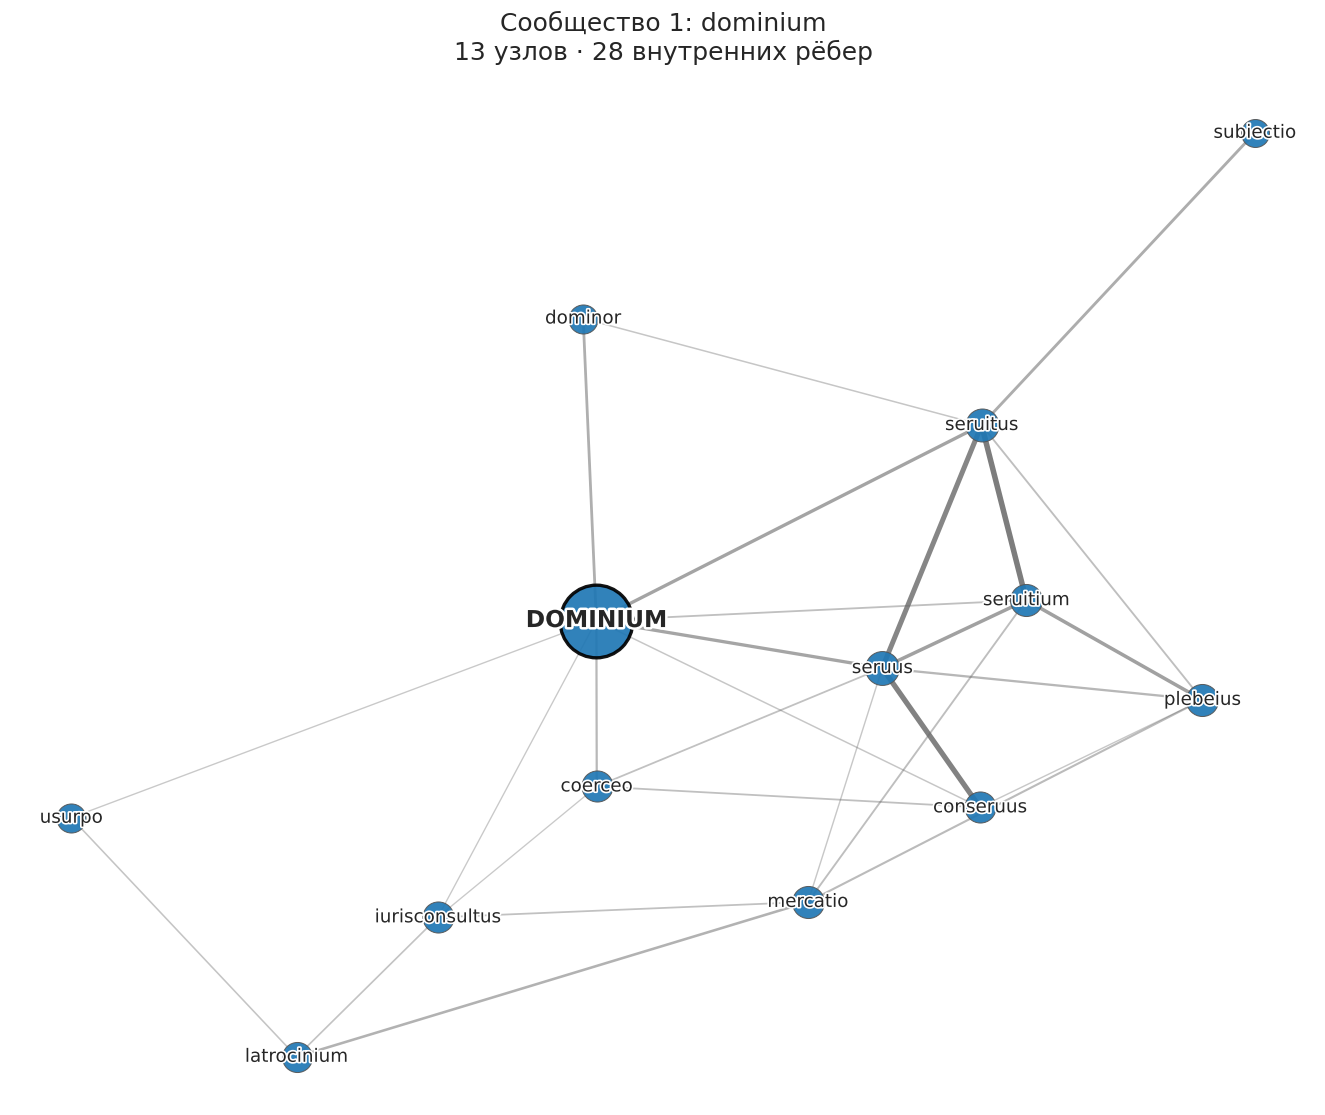

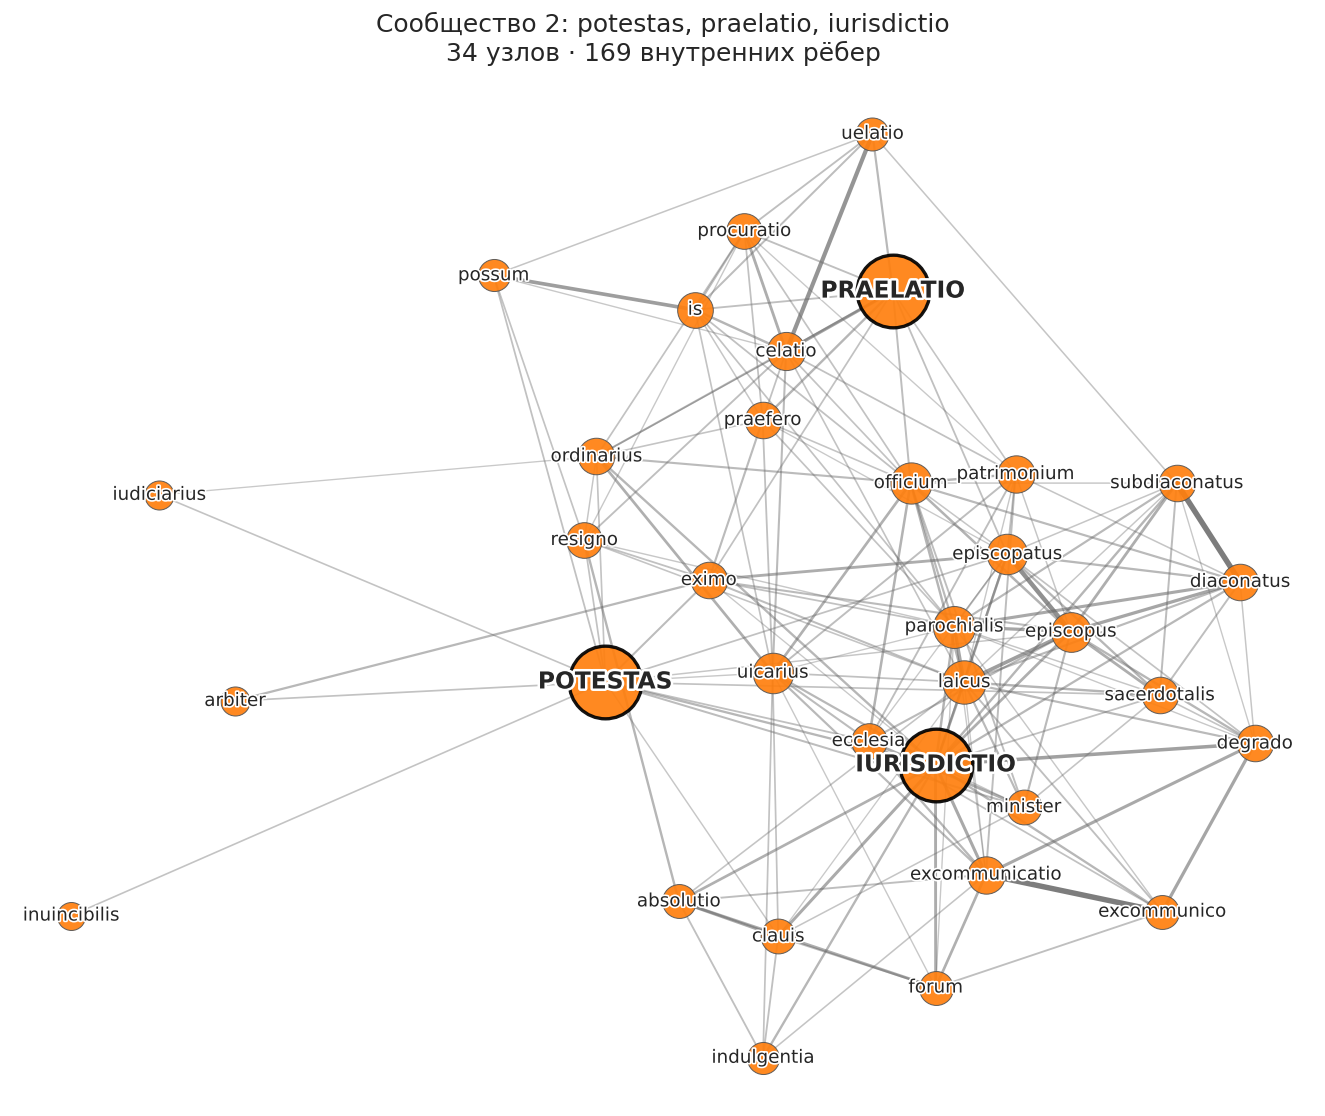

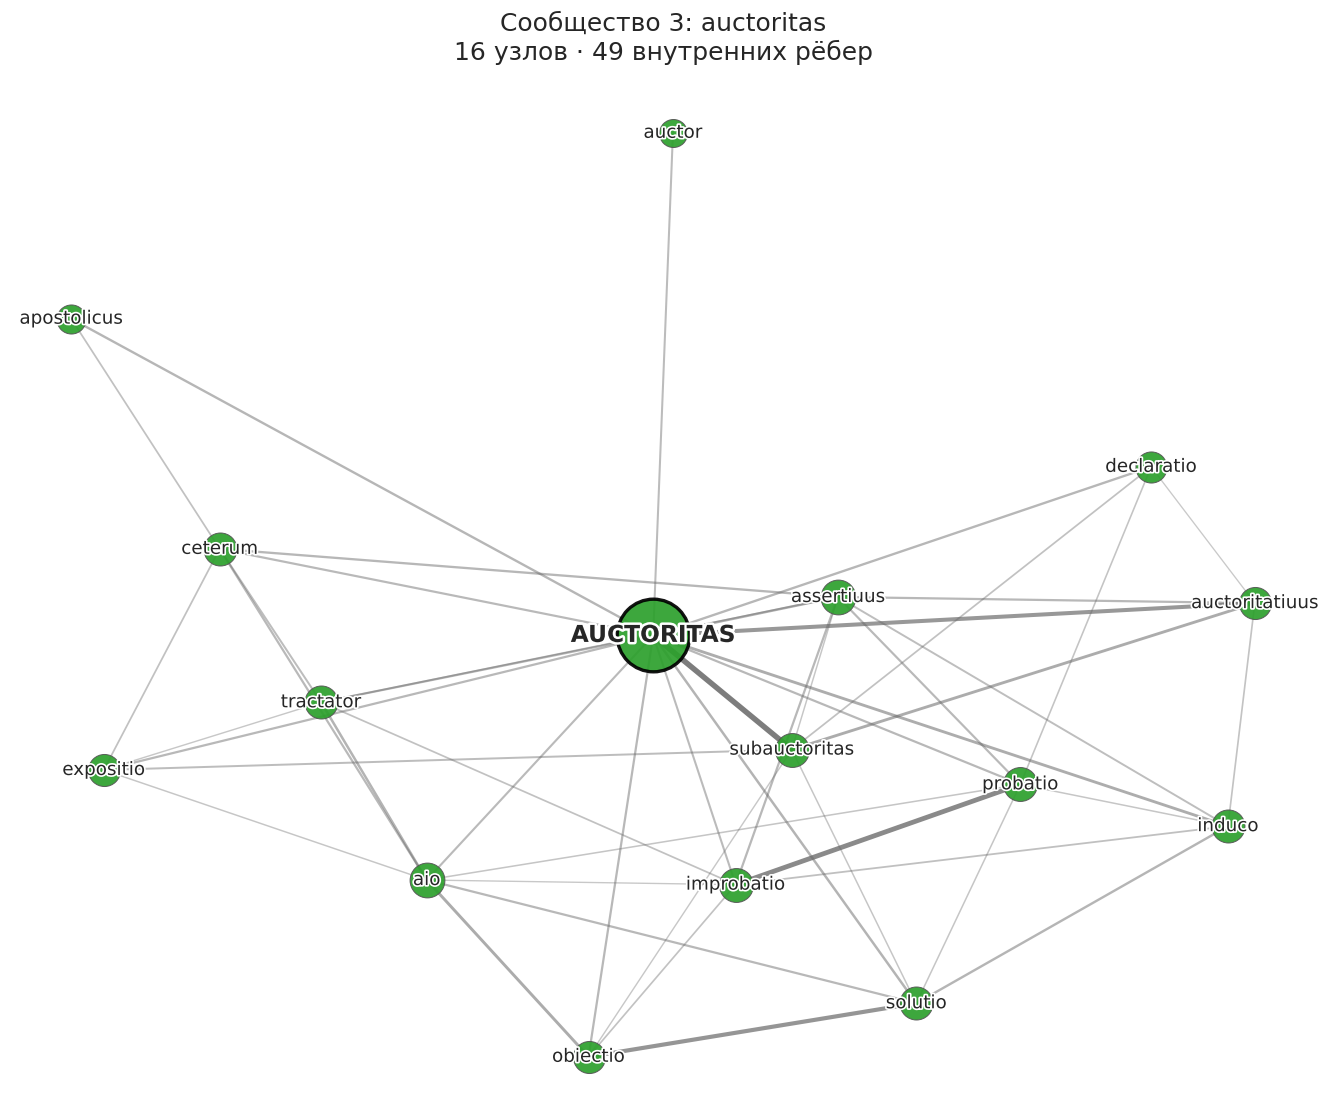

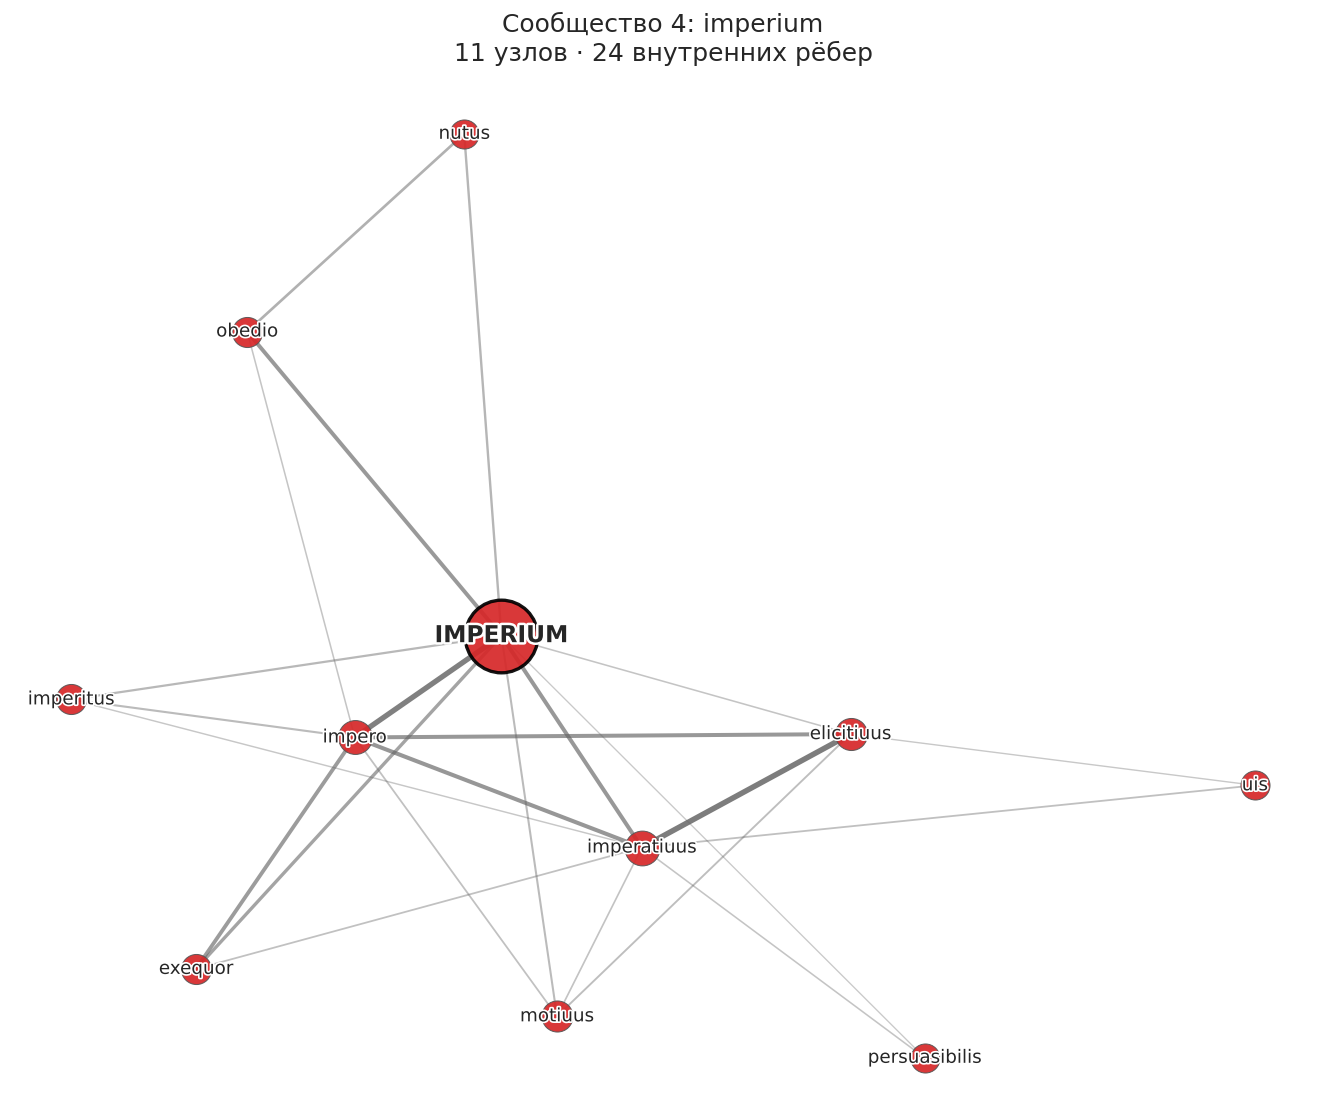

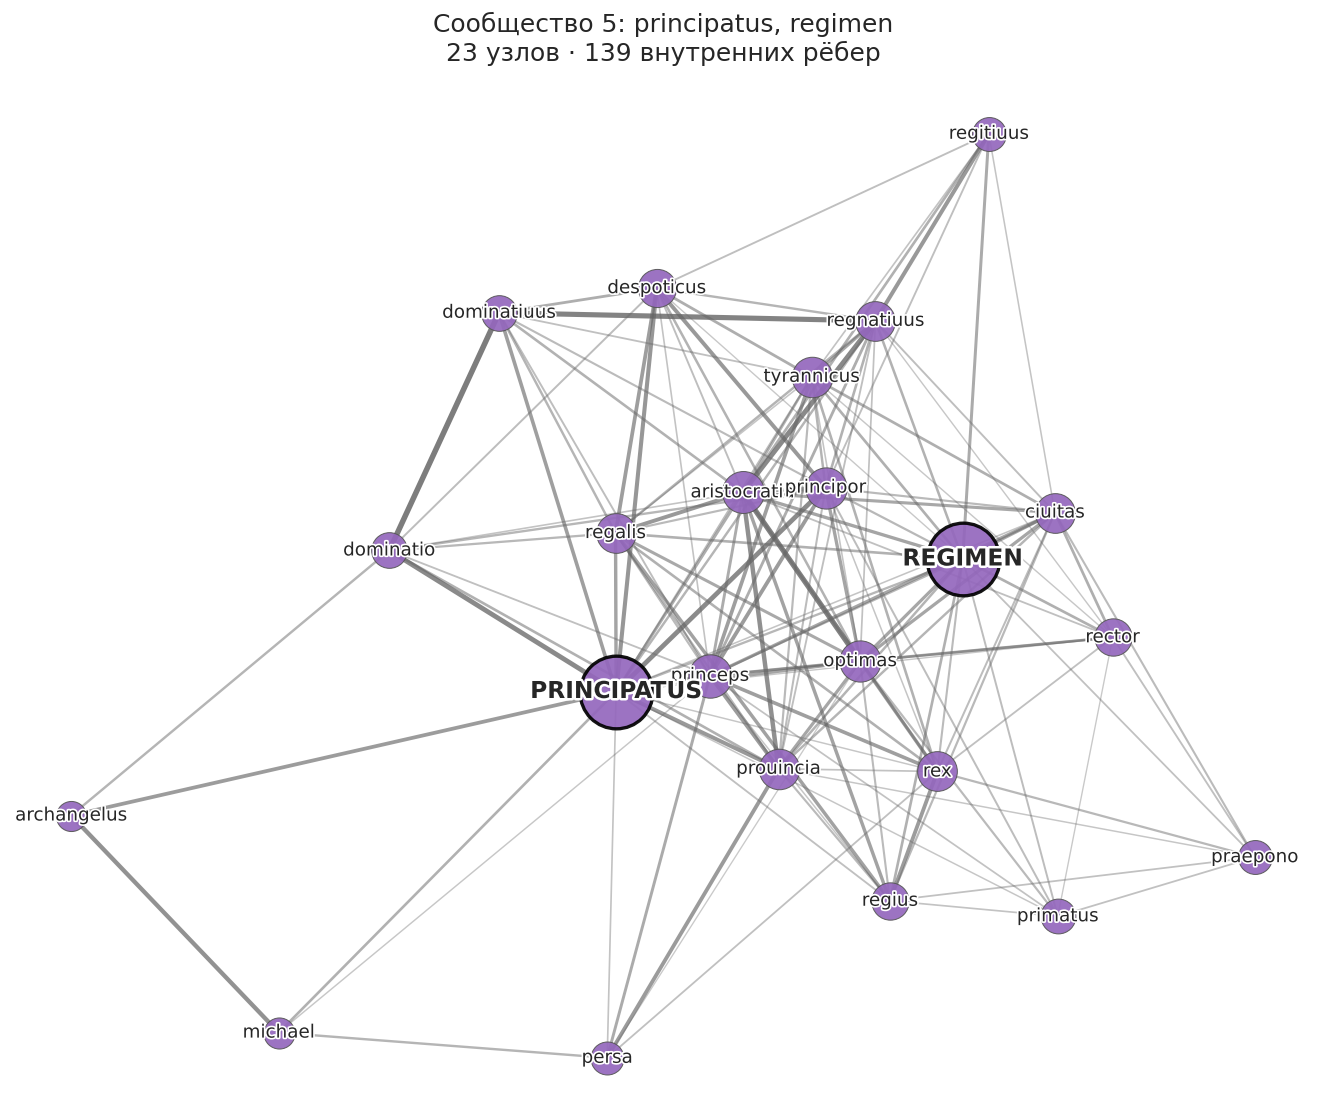

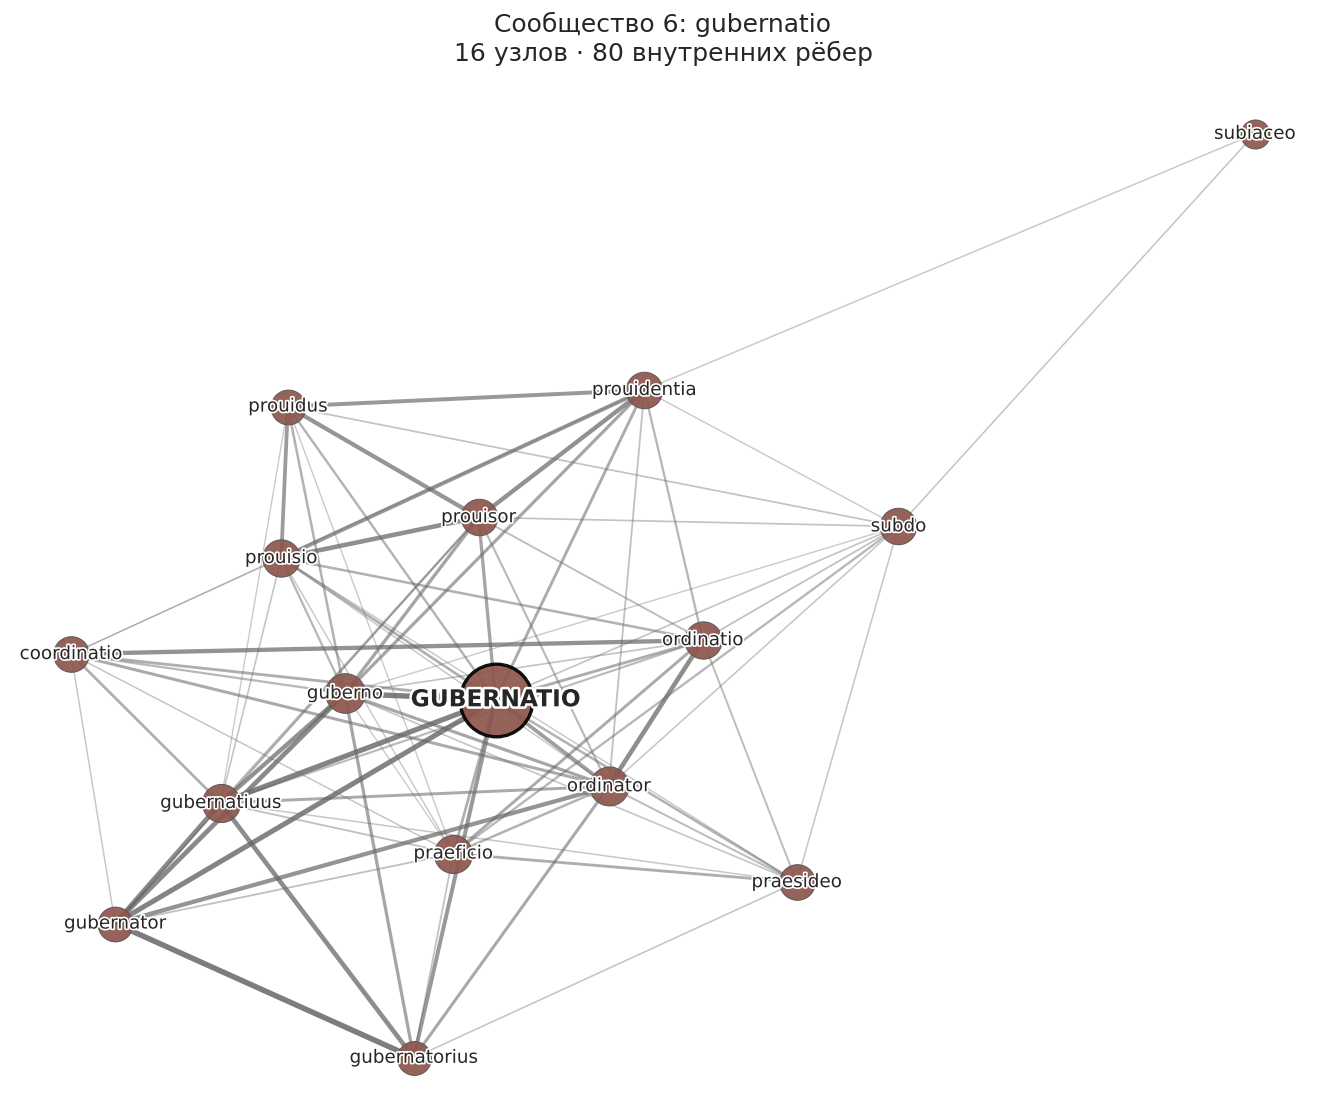

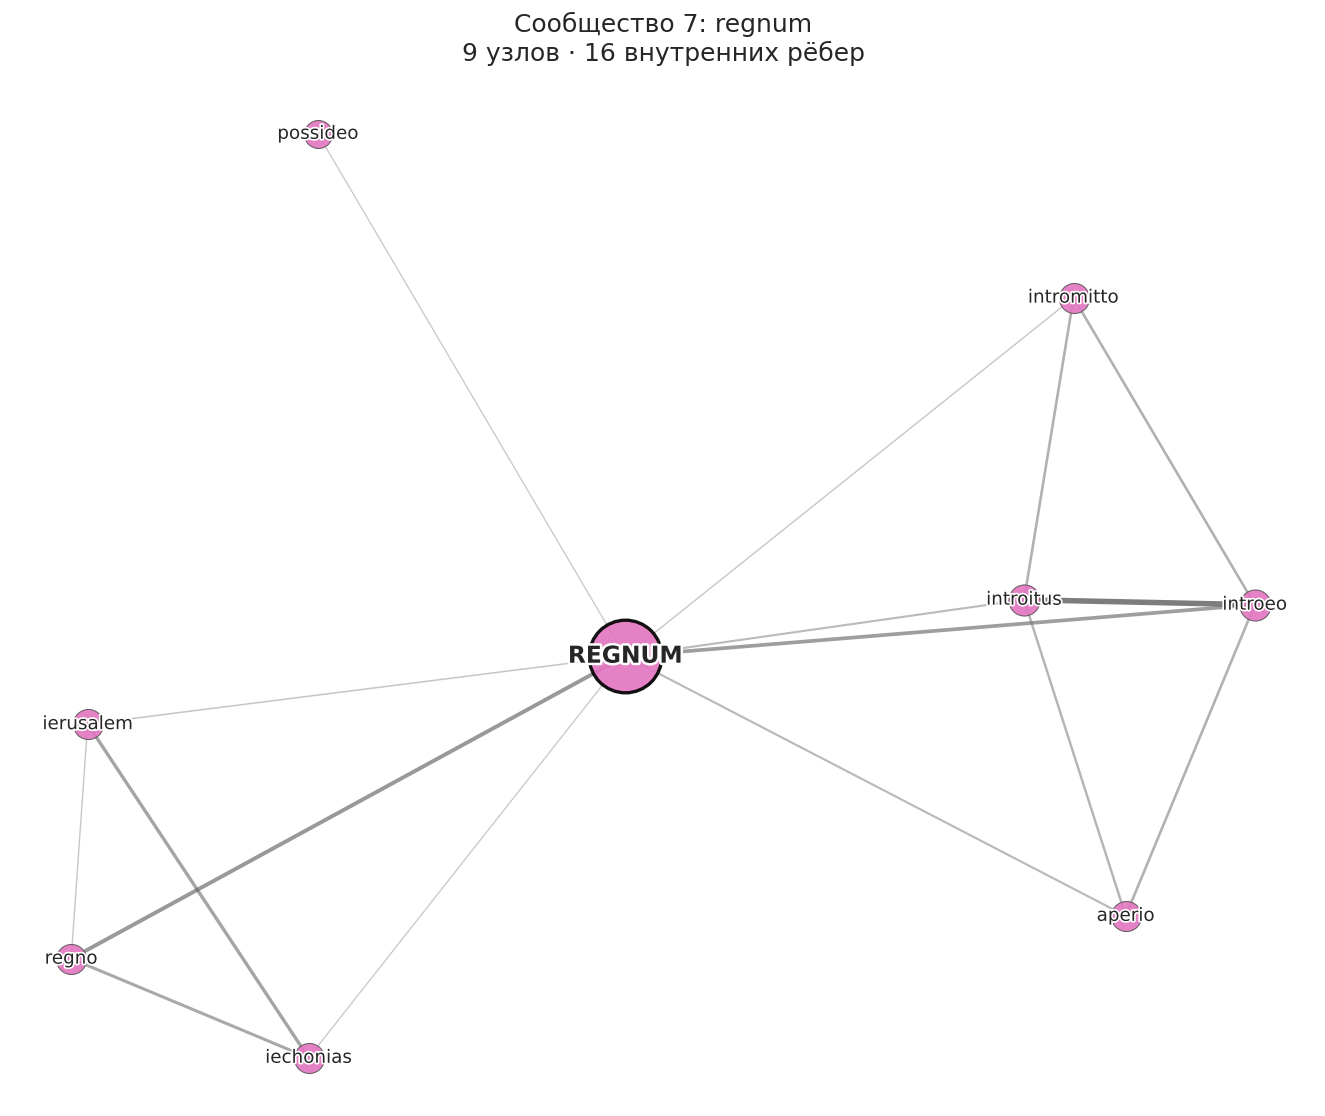

In [10]:
for c in communities:
    fig, anchor = draw_community(G, membership, community_colors, c, THRESHOLD)
    save_figure(fig, f"community_medoid_{c}_{anchor}", folder=os.path.join(FIG_DIR, "communities"))


## 9. Десять локальных сетей по схеме 6–4

Для каждой из **десяти целевых лемм** строится локальная сеть: шесть ближайших соседей леммы и по четыре ближайших соседа каждого из них. В локальных сетях используется отдельный запуск Лейдена с фиксированным `seed=42`. Сети 6–4 нужны для контекстного прочтения и **не изменяют словарь основной сети**: их дополнительные узлы не добавляются к основному графу.

Все десять PNG сохраняются **только** в `figures/local_networks/`. Из них в статье используются три: *potestas* (Рисунок 4), *regimen* (Рисунок 6), *principatus* (Рисунок 7). Нумерация рисунков задаётся текстом статьи, а не именами файлов локальных сетей.


In [11]:
local_networks = {term: local_network_6_4(term) for term in TARGET_TERMS}

rows = []
for term, g in local_networks.items():
    first = [w for w, _ in wv.most_similar(term, topn=LOCAL_FIRST)]
    others = [f"{t} ({g.nodes[t]['level']}-й)" for t in TARGET_TERMS if t in g and t != term]
    rows.append({"Лемма": term, "Шесть соседей первого уровня": ", ".join(first),
                 "Другие целевые леммы (уровень)": ", ".join(others) or "–",
                 "Узлов": g.number_of_nodes(), "Рёбер": g.number_of_edges()})
display(Markdown("**Локальные сети десяти целевых лемм**"))
display(pd.DataFrame(rows).set_index("Лемма"))

**Локальные сети десяти целевых лемм**

,Шесть соседей первого уровня,Другие целевые леммы (уровень),Узлов,Рёбер
Лемма,,,,
dominium,"seruitus, seruus, dominor, coerceo, potestas, ...","potestas (1-й), iurisdictio (2-й)",24,28
potestas,"iurisdictio, eximo, minister, dominium, eccles...","dominium (1-й), iurisdictio (1-й)",30,30
praelatio,"celatio, subiectio, praefero, uelatio, plebeiu...",–,28,29
iurisdictio,"degrado, excommunicatio, clauis, forum, episco...",–,22,28
auctoritas,"subauctoritas, auctoritatiuus, induco, asserti...",–,29,30
imperium,"impero, imperatiuus, obedio, despoticus, exequ...",principatus (2-й),24,28
principatus,"dominatio, principor, princeps, despoticus, pr...",imperium (2-й),22,27
regimen,"praeficio, gubernatiuus, gubernatio, aristocra...",gubernatio (1-й),22,28
gubernatio,"guberno, gubernatiuus, gubernator, gubernatori...",–,14,23


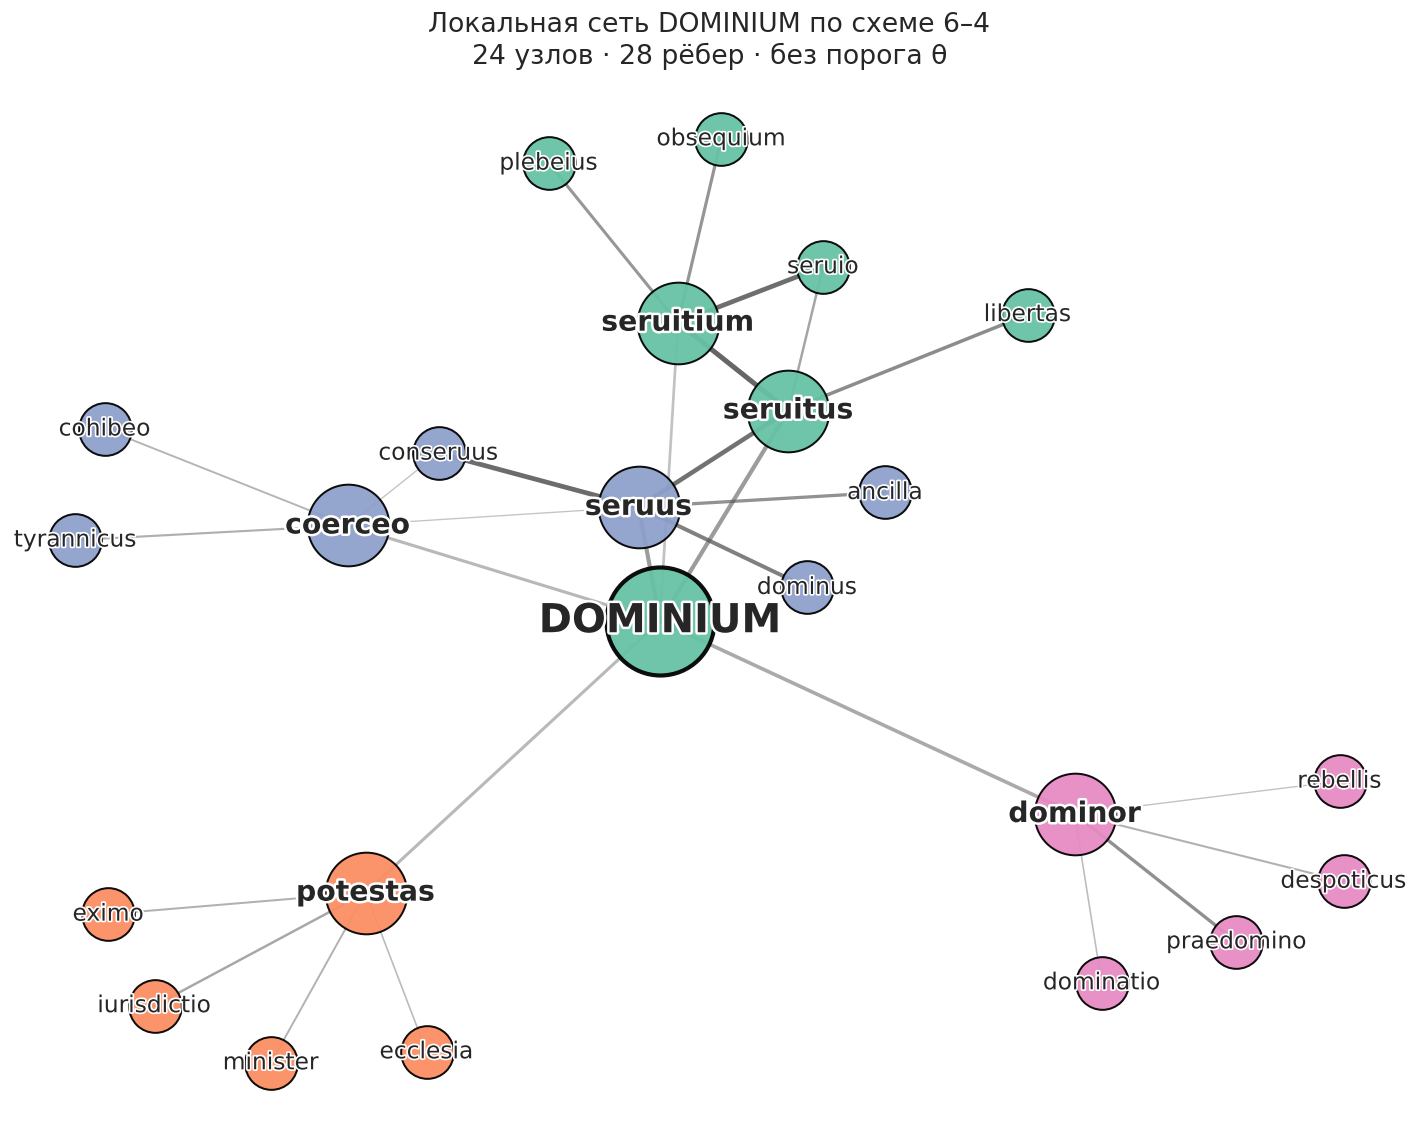

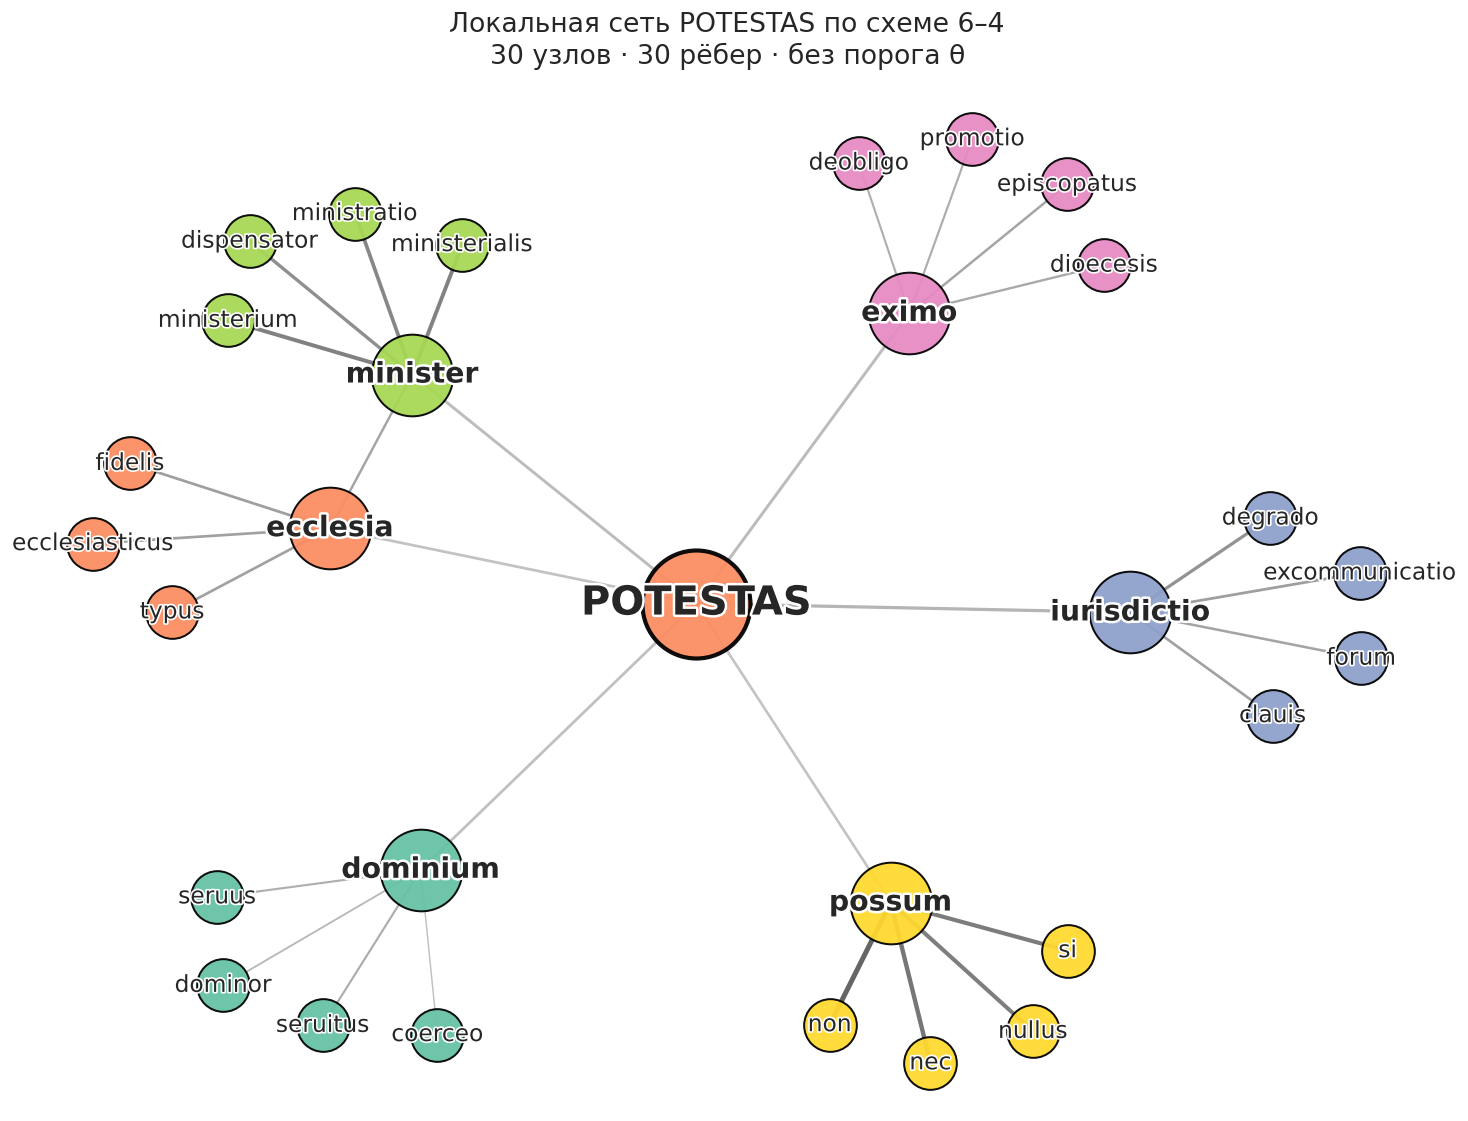

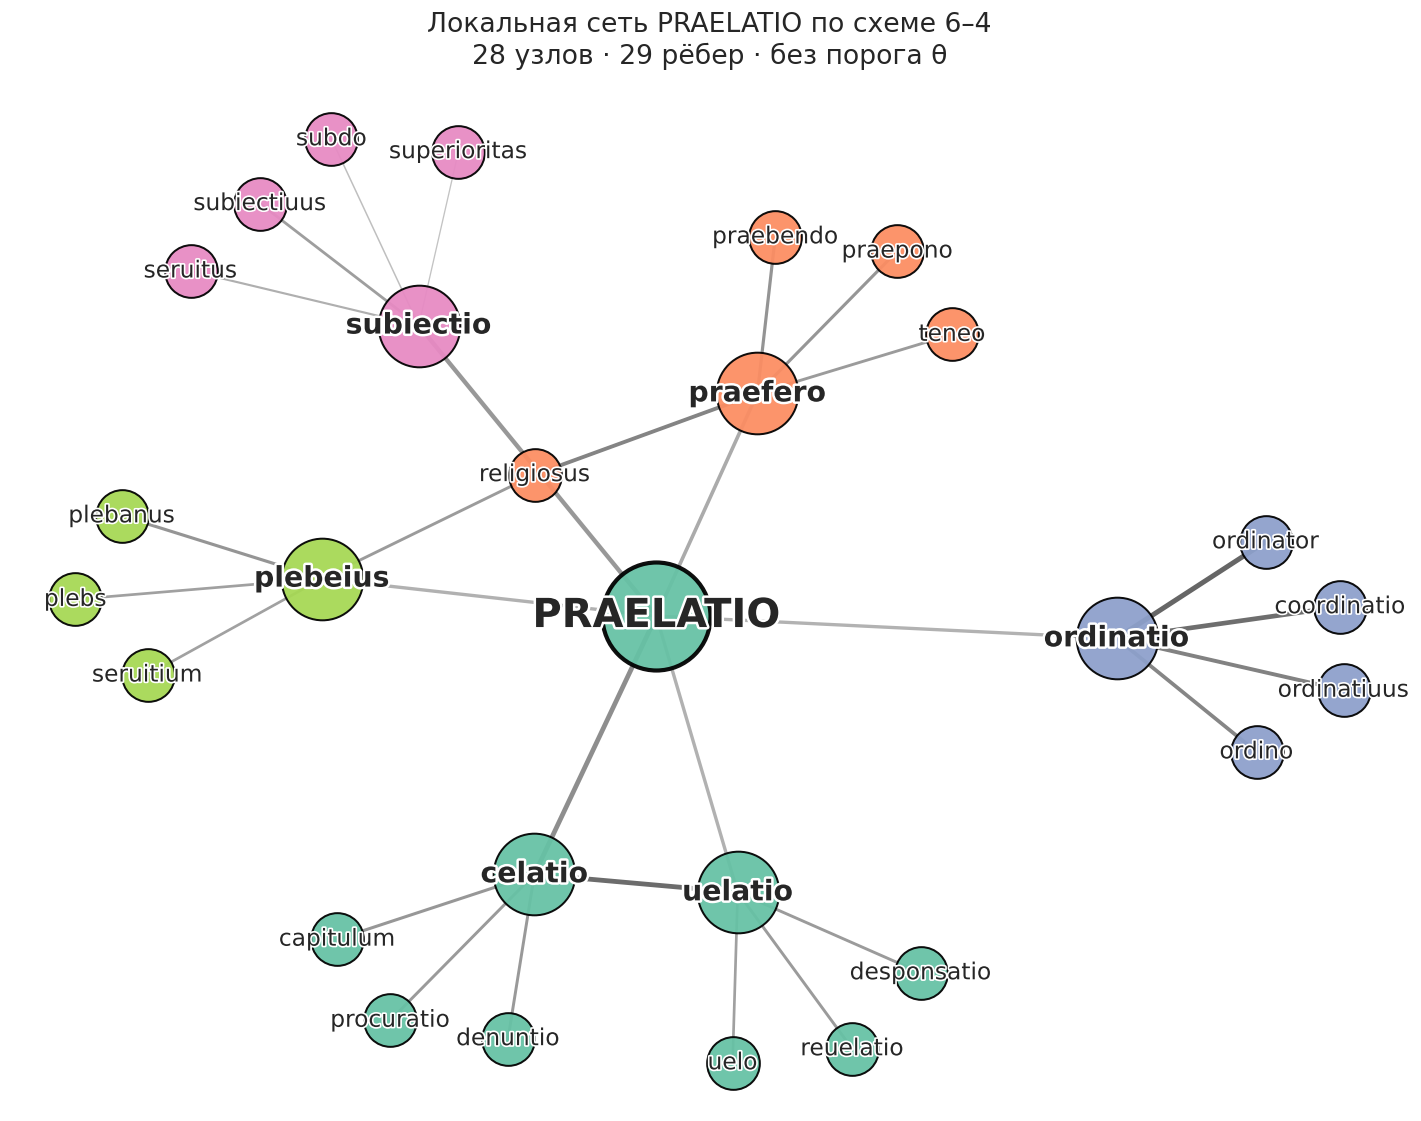

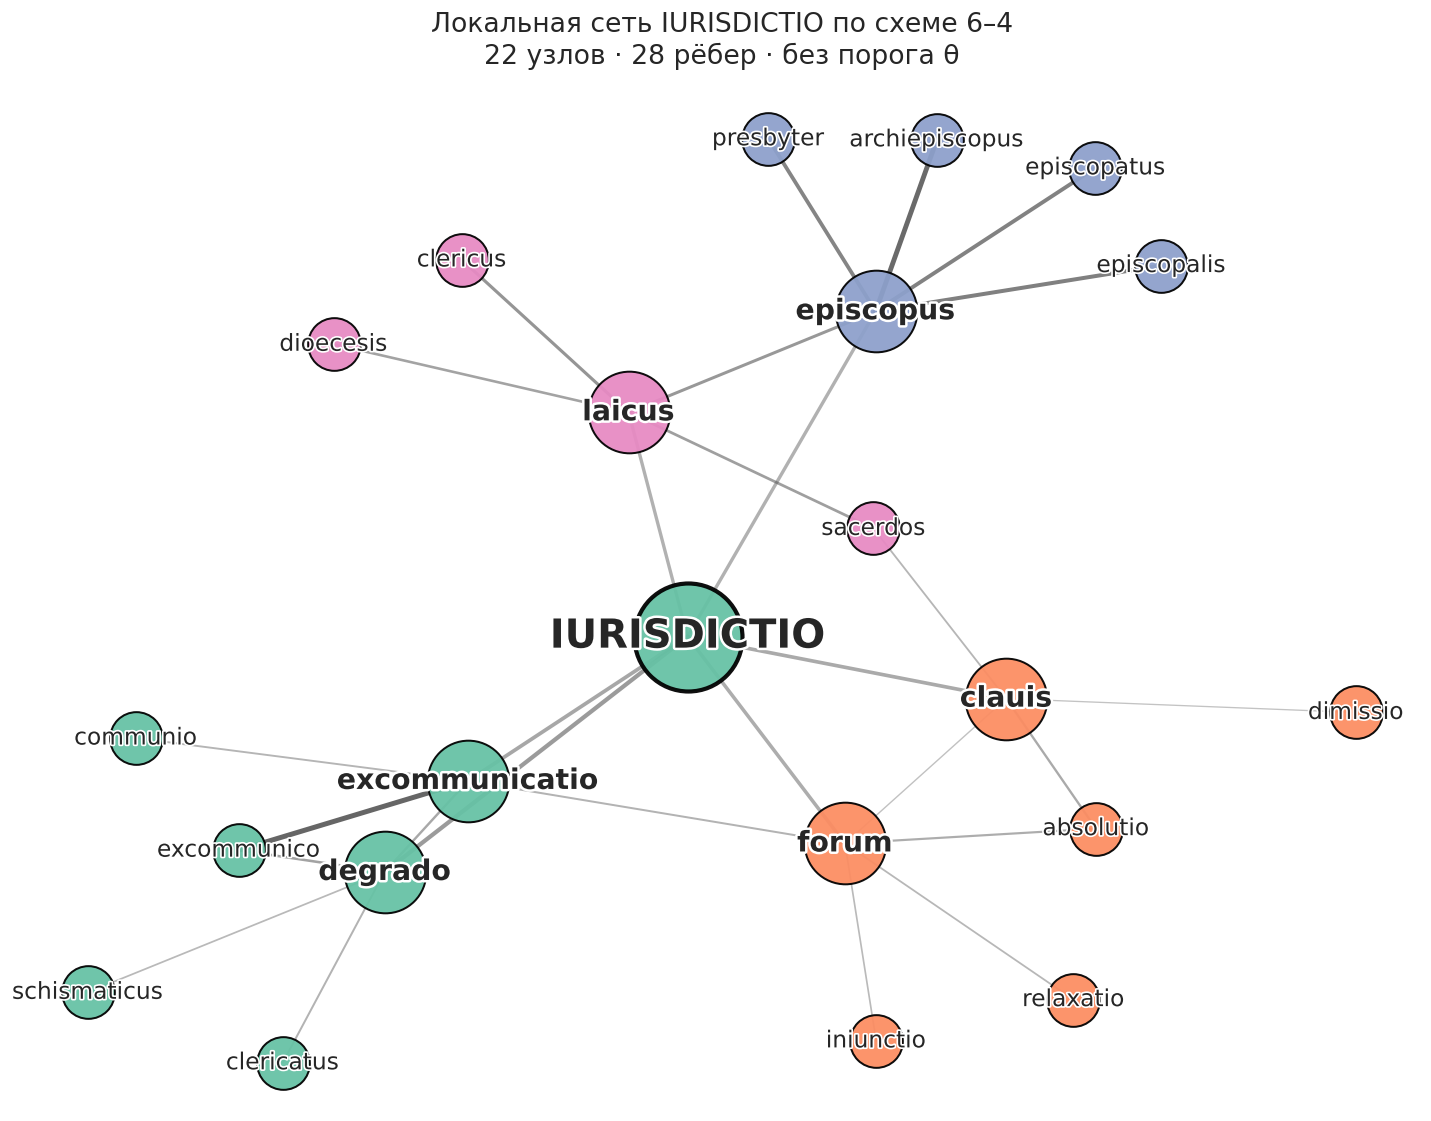

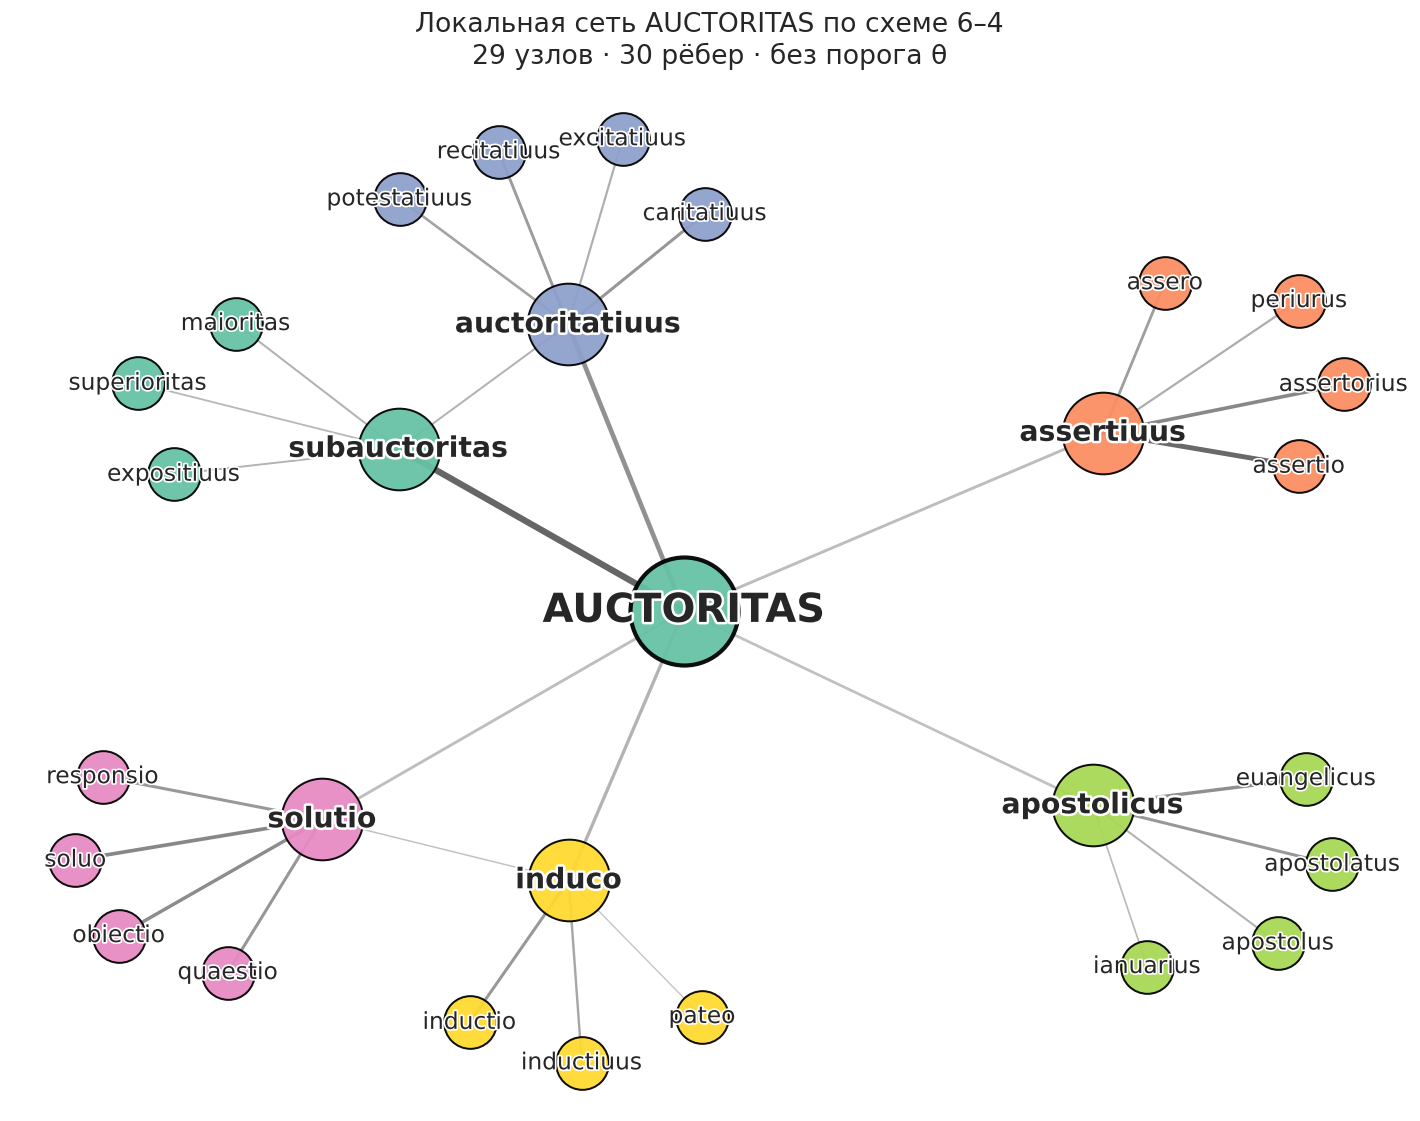

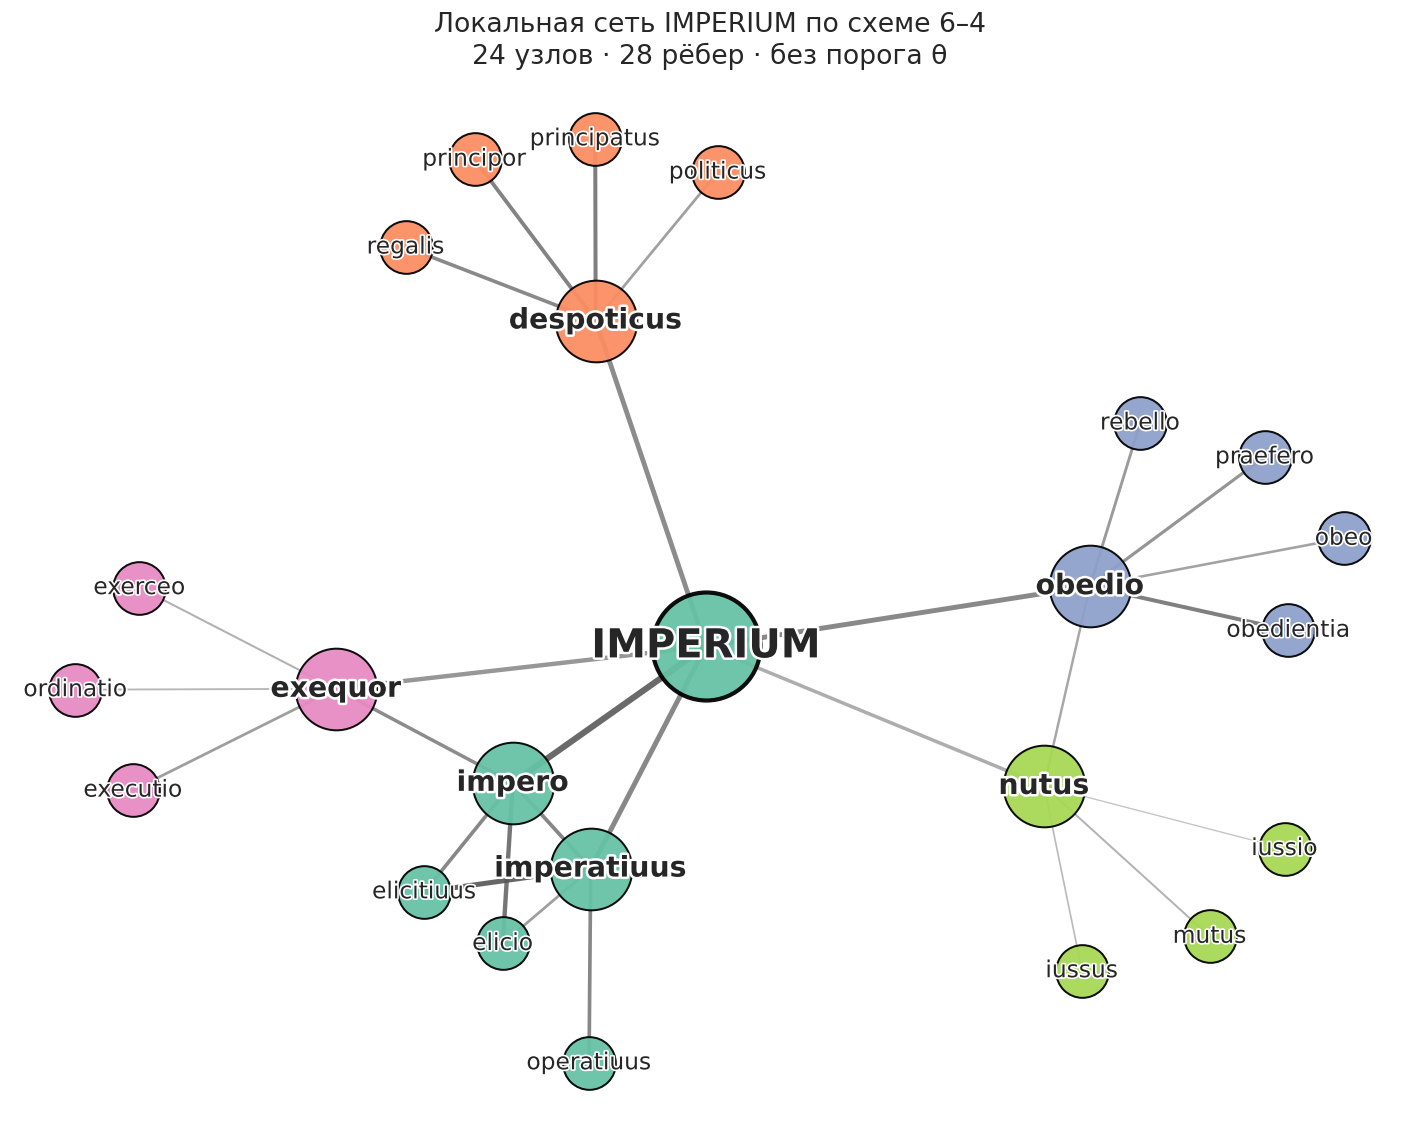

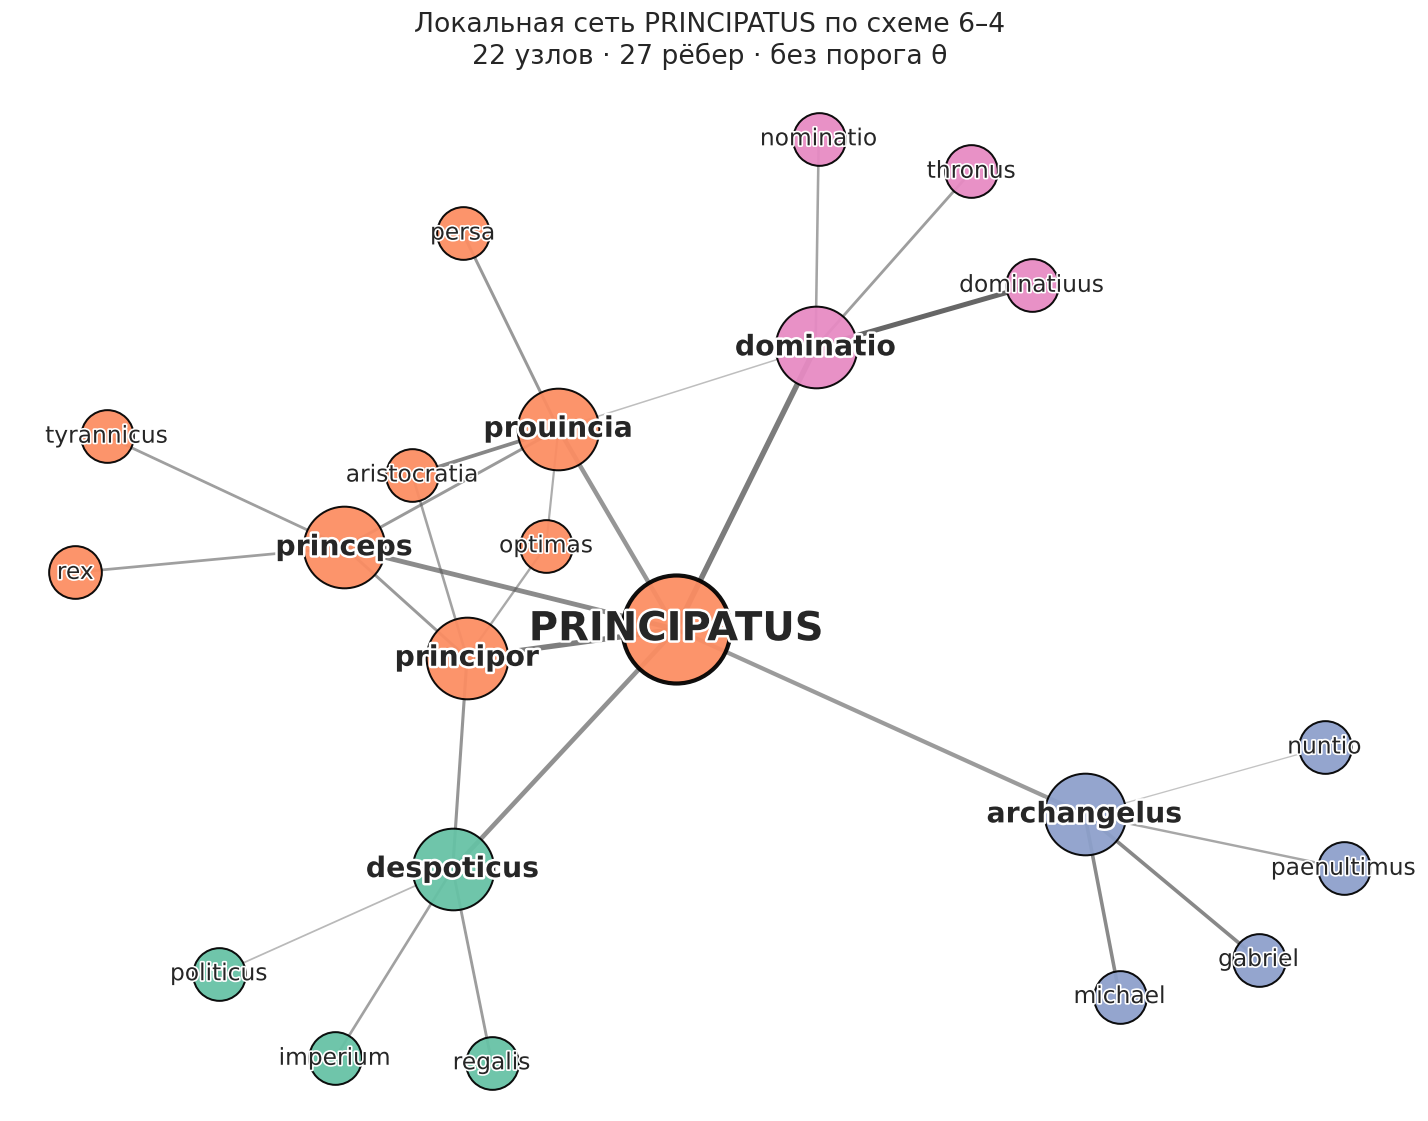

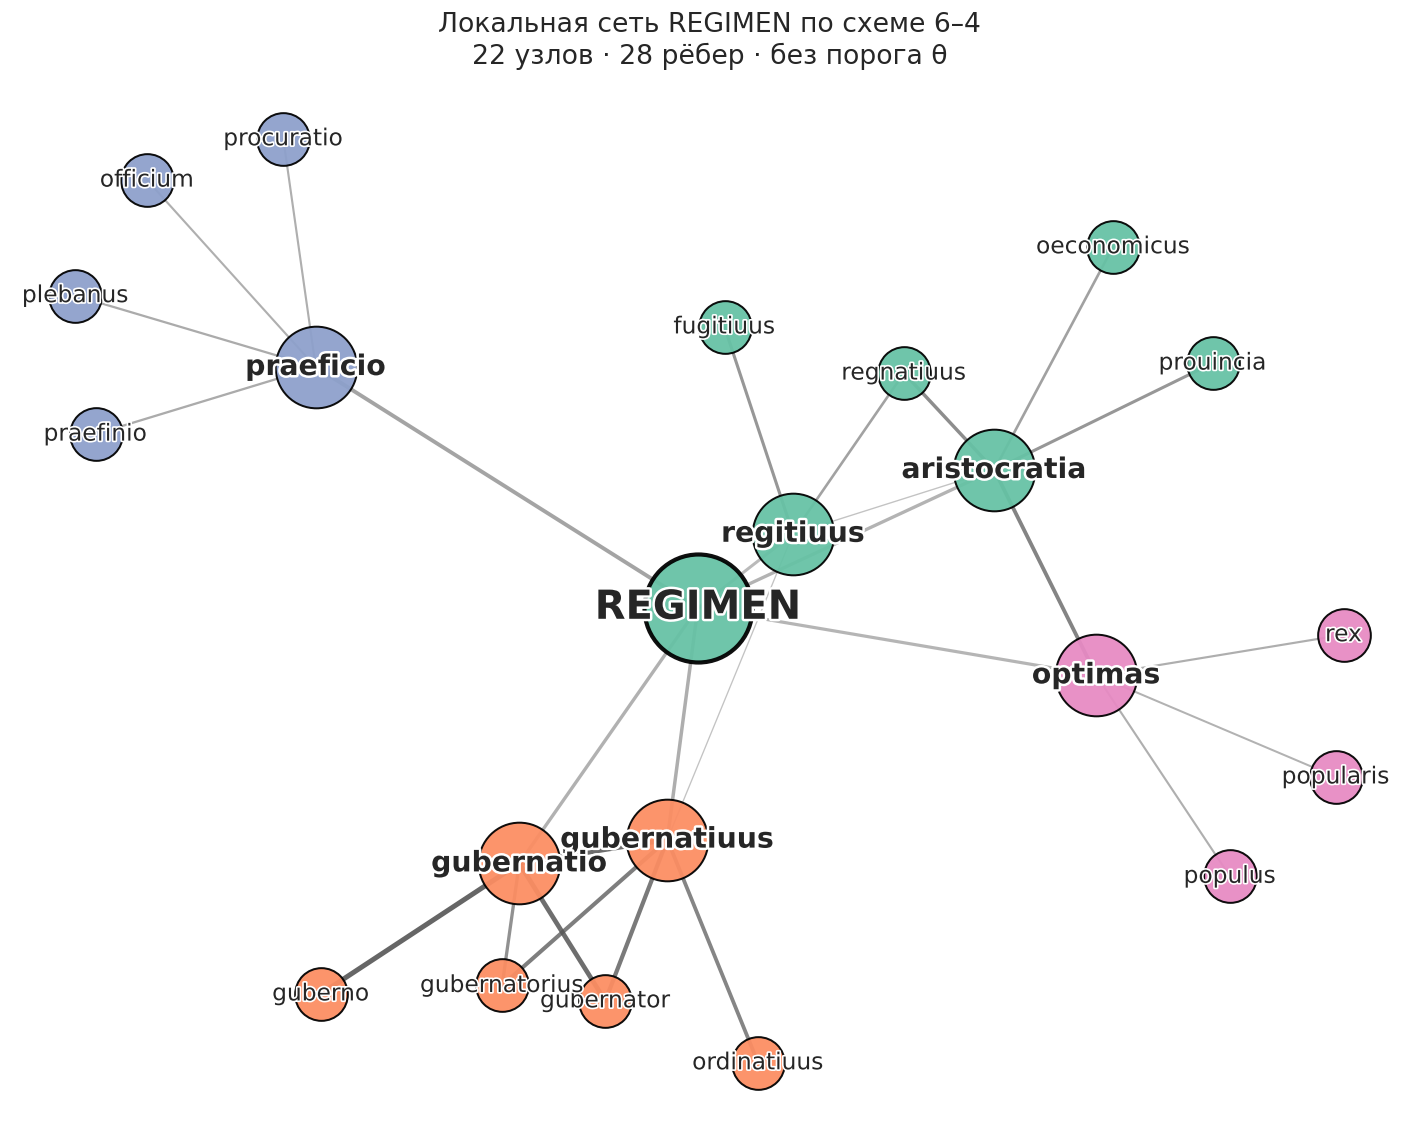

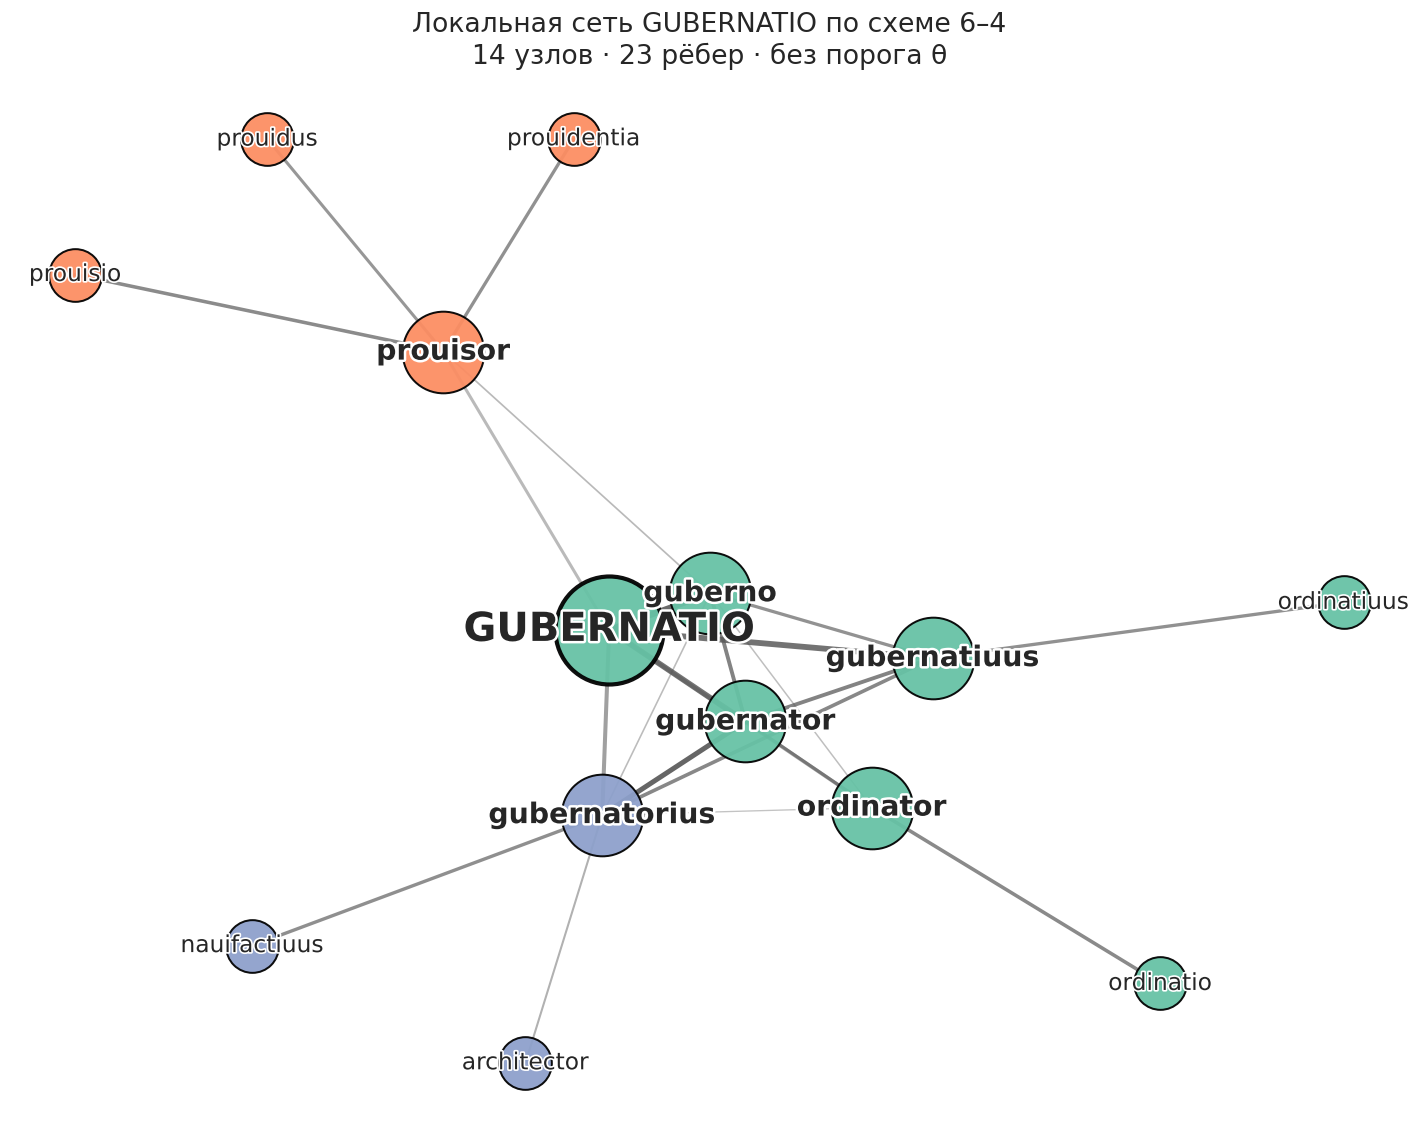

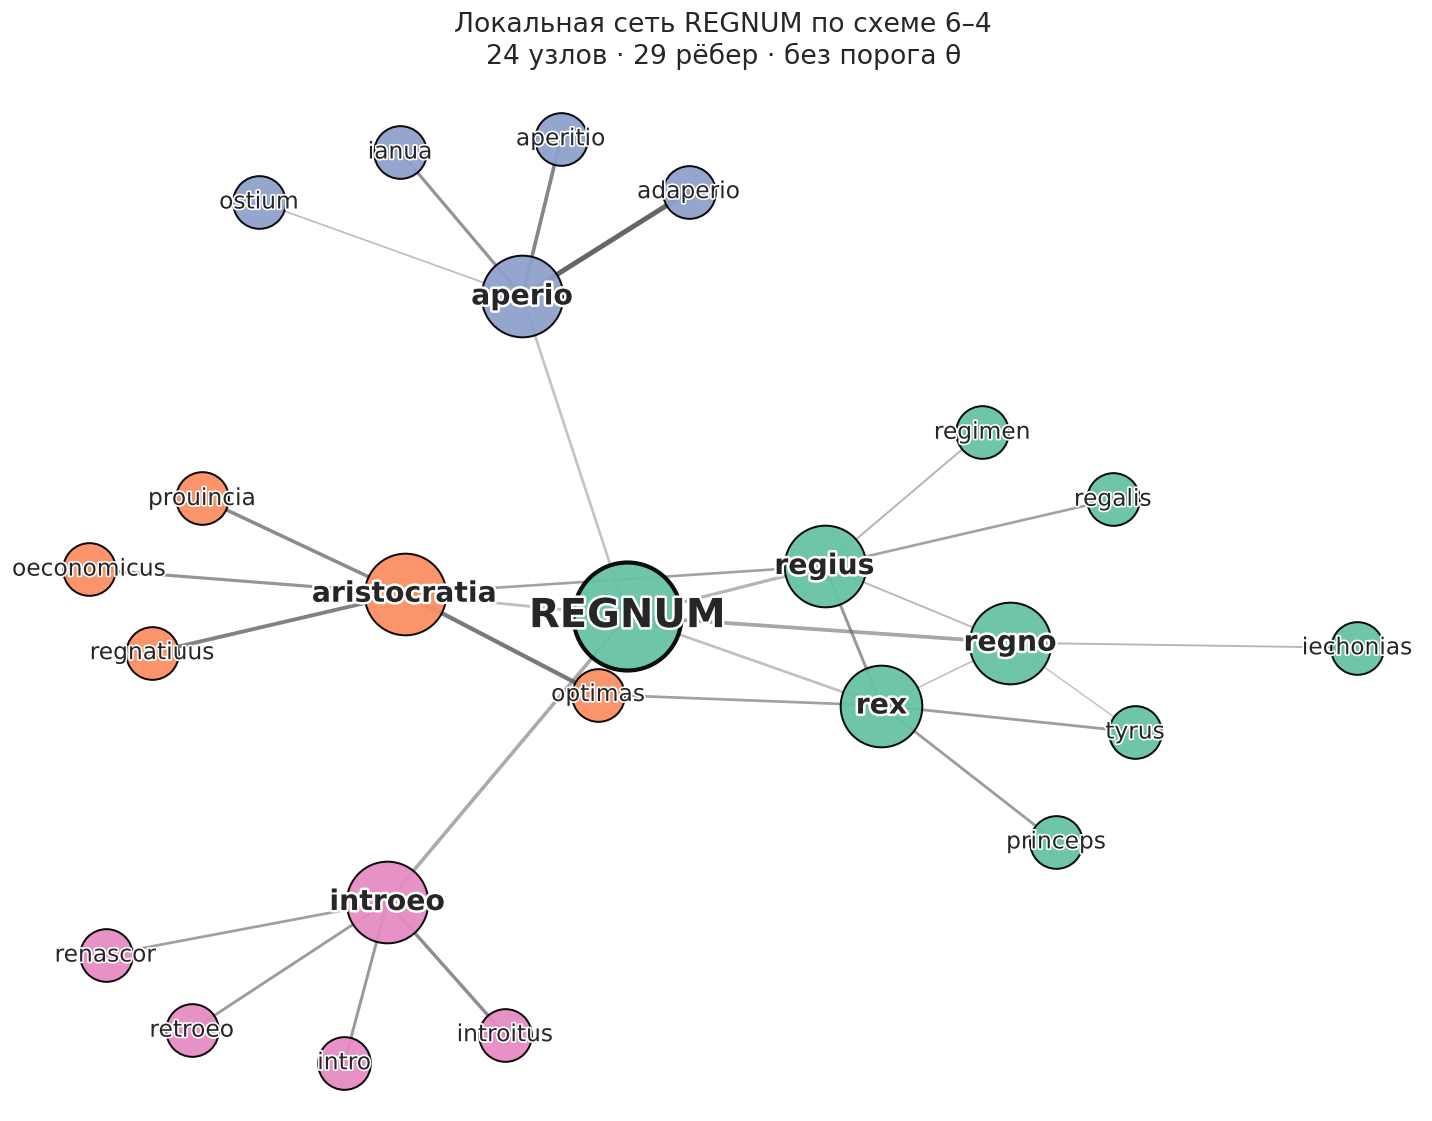

Все десять локальных сетей (PNG): C:\Users\Admin\Documents\GitHub\aquinas-power-lexicon\figures\local_networks


In [12]:
# Все десять локальных сетей записываются только в отдельную папку.
local_dir = os.path.join(FIG_DIR, "local_networks")
for term, g in local_networks.items():
    save_figure(draw_local_network(term, g), f"local_6_4_{term}", folder=local_dir)

# Убираем только устаревшие копии, созданные предыдущими версиями ноутбука.
# Остальные файлы figures/ не затрагиваются.
obsolete_local_copies = (
    "figure_3_potestas.png", "figure_4_regimen.png", "figure_5_principatus.png",
    "figure_4_local_potestas.png", "figure_6_local_regimen.png",
    "figure_7_local_principatus.png",
)
for filename in obsolete_local_copies:
    old_path = os.path.join(FIG_DIR, filename)
    if os.path.isfile(old_path):
        os.remove(old_path)
print("Все десять локальных сетей (PNG):", os.path.abspath(local_dir))


## 10. Матрица косинусного сходства десяти обозначений власти

Тепловая карта показывает непосредственное косинусное сходство каждой пары целевых лемм. Порядок строк и столбцов определяется их сообществами в медоидном разбиении. Косинусное сходство вычисляется по векторам модели и не зависит от принадлежности слов к одному сетевому сообществу.

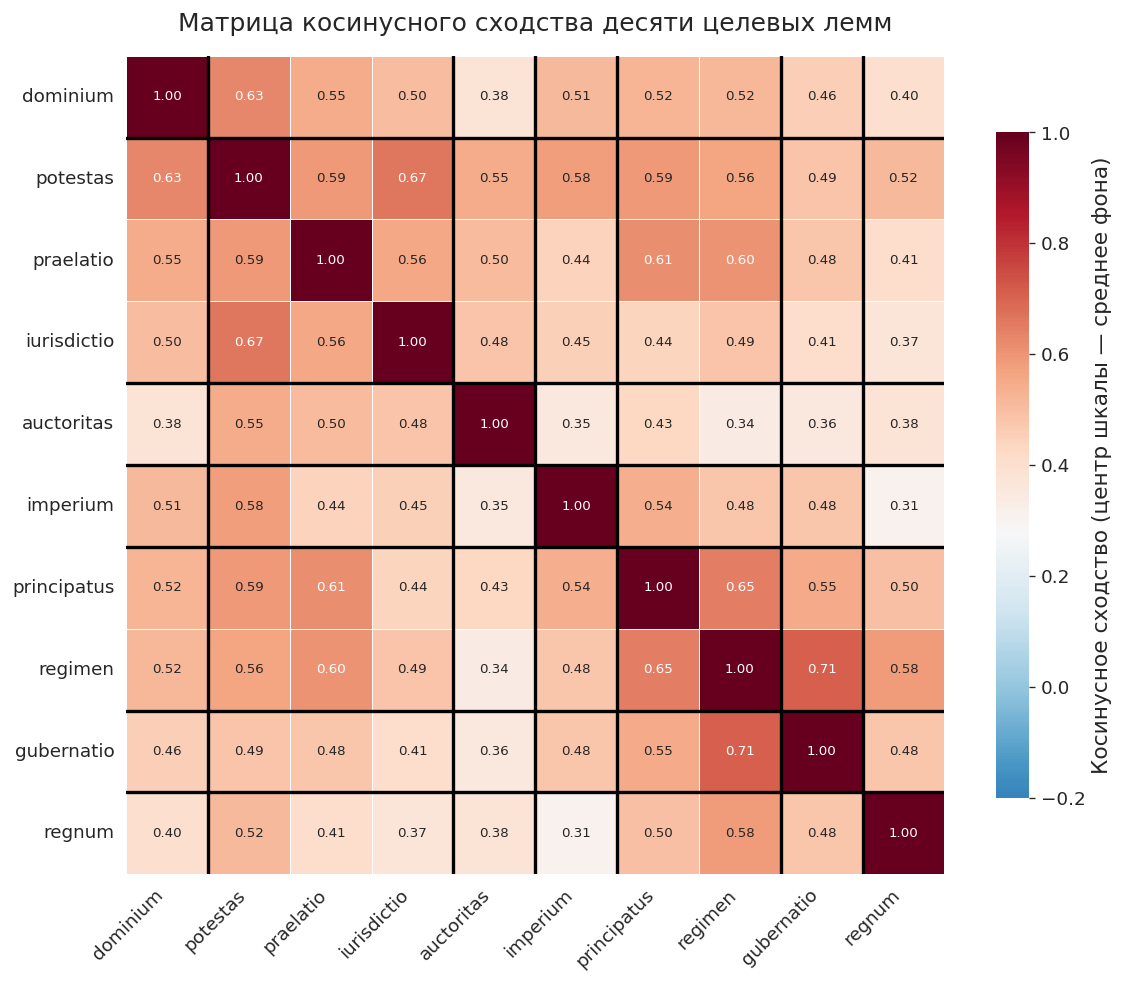

In [13]:
order = sorted(TARGET_TERMS, key=lambda t: (membership[t], TARGET_TERMS.index(t)))
boundaries = [i for i in range(1, len(order)) if membership[order[i]] != membership[order[i - 1]]]
idx = [lemmas.index(t) for t in order]
matrix = pd.DataFrame(similarity[np.ix_(idx, idx)], index=order, columns=order)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matrix, cmap="RdBu_r", center=mean_sim, vmin=-0.2, vmax=1.0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.5, linecolor="white", square=True,
            cbar_kws={"label": "Косинусное сходство (центр шкалы — среднее фона)", "shrink": 0.8}, ax=ax)
for boundary in boundaries:
    ax.axhline(boundary, color="black", linewidth=2)
    ax.axvline(boundary, color="black", linewidth=2)
ax.set_title("Матрица косинусного сходства десяти целевых лемм", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
save_figure(fig, "figure_2_similarity_matrix")

## 11. Попарное сходство и положение целевых лемм в сети

Для всех 45 уникальных пар десяти целевых лемм рассчитываются косинусное сходство, отклонение от общего среднего в стандартных отклонениях (*z*), взаимные ранги соседства и принадлежность к одному сообществу медоида. Косинусное сходство и ранги задаются используемой моделью; совместная принадлежность определяется структурой построенной сети.

In [14]:
def pair_row(a, b):
    c = float(wv.similarity(a, b))
    return {
        "Пара": f"{a} – {b}",
        "Косинус": round(c, 3),
        "z": round((c - mean_sim) / std_sim, 1),
        "Место b среди соседей a": int(wv.rank(a, b)),
        "Место a среди соседей b": int(wv.rank(b, a)),
        "Одно сообщество медоида": "да" if membership[a] == membership[b] else "нет"
    }

pair_table = pd.DataFrame([pair_row(a, b) for a, b in KEY_PAIRS]).set_index("Пара")
display(Markdown(f"**Фон модели:** среднее {mean_sim:.3f}, σ = {std_sim:.3f}; "
                 f"порог основной сети θ = {THRESHOLD:.2f}"))
display(Markdown("**Все 45 пар целевых лемм**"))
display(pair_table)
save_table(pair_table, "pairwise_similarity")

display(Markdown("**Медоидные сообщества десяти целевых лемм**"))
target_table = pd.DataFrame([
    {"Лемма": t, "Частота": freq(t), "Сообщество": membership[t]}
    for t in TARGET_TERMS
]).set_index("Лемма")
display(target_table)
save_table(target_table, "term_communities")

# Кратчайшие пути между выбранными целевыми леммами.
PATH_PAIRS = [("dominium", "regimen"), ("dominium", "potestas"),
              ("praelatio", "regimen"), ("auctoritas", "potestas"),
              ("regnum", "regimen"), ("gubernatio", "regimen")]
display(Markdown("**Кратчайшие пути между обозначениями власти**"))
for a, b in PATH_PAIRS:
    if nx.has_path(G, a, b):
        print(f"{a} → {b}: " + " → ".join(nx.shortest_path(G, a, b)))


**Фон модели:** среднее 0.279, σ = 0.108; порог основной сети θ = 0.59

**Все 45 пар целевых лемм**

,Косинус,z,Место b среди соседей a,Место a среди соседей b,Одно сообщество медоида
Пара,,,,,
dominium – potestas,0.632,3.3,5,4,нет
dominium – praelatio,0.547,2.5,35,107,нет
dominium – iurisdictio,0.500,2.0,95,174,нет
dominium – auctoritas,0.377,0.9,843,2074,нет
dominium – imperium,0.509,2.1,76,78,нет
dominium – principatus,0.524,2.3,53,95,нет
dominium – regimen,0.517,2.2,64,118,нет
dominium – gubernatio,0.456,1.6,198,264,нет
dominium – regnum,0.404,1.2,548,731,нет


Сохранена таблица: ..\tables\pairwise_similarity.csv


**Медоидные сообщества десяти целевых лемм**

,Частота,Сообщество
Лемма,,
dominium,287,1
potestas,2527,2
praelatio,249,2
iurisdictio,97,2
auctoritas,1363,3
imperium,449,4
principatus,160,5
regimen,189,5
gubernatio,248,6


Сохранена таблица: ..\tables\term_communities.csv


**Кратчайшие пути между обозначениями власти**

dominium → regimen: dominium → despoticus → regimen
dominium → potestas: dominium → potestas
praelatio → regimen: praelatio → regimen
auctoritas → potestas: auctoritas → auctoritatiuus → uicarius → potestas
regnum → regimen: regnum → aristocratia → regimen
gubernatio → regimen: gubernatio → regimen


## 12. Проверки устойчивости при 10, 15 и 20 соседях

Для каждого N формируется словарь из десяти целевых лемм и N ближайших соседей каждой из них, затем независимо определяется порог по связности. Для N = 15 используются 50 разбиений, рассчитанных при основном анализе; для N = 10 и N = 20 проводится по 50 запусков Лейдена. Основной показатель устойчивости — число запусков, в которых каждая из 45 пар целевых лемм попала в одно сообщество.

In [15]:
networks = {
    TOP_N: {"lemmas": lemmas, "similarity": similarity,
            "threshold": THRESHOLD, "graph": G}
}
runs_by_n = {TOP_N: base_runs}
together = {TOP_N: co_membership(base_runs)}

for n in TOP_N_VALUES:
    if n == TOP_N:
        continue  # повторно используем 50 запусков основного анализа
    words = network_lemmas(n)
    sim = similarity_matrix(words)
    threshold = connectivity_threshold(words, sim)
    graph = build_network(words, sim, threshold)
    networks[n] = {"lemmas": words, "similarity": sim,
                   "threshold": threshold, "graph": graph}
    runs_by_n[n] = [leiden(graph, seed=s) for s in range(N_LEIDEN_RUNS)]
    together[n] = co_membership(runs_by_n[n])

network_summary = pd.DataFrame([
    {"N": n, "Порог θ": networks[n]["threshold"],
     "Узлов": networks[n]["graph"].number_of_nodes(),
     "Рёбер": networks[n]["graph"].number_of_edges(),
     "Запусков Лейдена": len(runs_by_n[n])}
    for n in TOP_N_VALUES
]).set_index("N")
display(network_summary)
save_table(network_summary, "robustness_networks")

pair_counts = pd.DataFrame({
    f"N = {n}": [int(together[n].loc[a, b]) for a, b in KEY_PAIRS]
    for n in TOP_N_VALUES
}, index=[f"{a} – {b}" for a, b in KEY_PAIRS]).rename_axis("Пара")
display(Markdown(f"**Совместная принадлежность в {N_LEIDEN_RUNS} запусках**"))
display(pair_counts)
save_table(pair_counts, "robustness_pairs")

,Порог θ,Узлов,Рёбер,Запусков Лейдена
N,,,,
10,0.60,90,400,50
15,0.59,122,715,50
20,0.58,157,1183,50


Сохранена таблица: ..\tables\robustness_networks.csv


**Совместная принадлежность в 50 запусках**

,N = 10,N = 15,N = 20
Пара,,,
dominium – potestas,0,0,0
dominium – praelatio,18,2,8
dominium – iurisdictio,0,0,0
dominium – auctoritas,0,0,0
dominium – imperium,0,0,0
dominium – principatus,0,1,0
dominium – regimen,0,0,0
dominium – gubernatio,0,0,1
dominium – regnum,0,0,0


Сохранена таблица: ..\tables\robustness_pairs.csv


### 12.1. Матрица совместной принадлежности (N = 15)

Число на пересечении показывает, сколько раз из 50 запусков две целевые леммы оказались в одном сообществе. Медоидное разбиение определяет порядок строк и столбцов, но не подменяет подсчёт частот. Эта матрица отражает чувствительность выделения сообществ к начальной инициализации алгоритма.

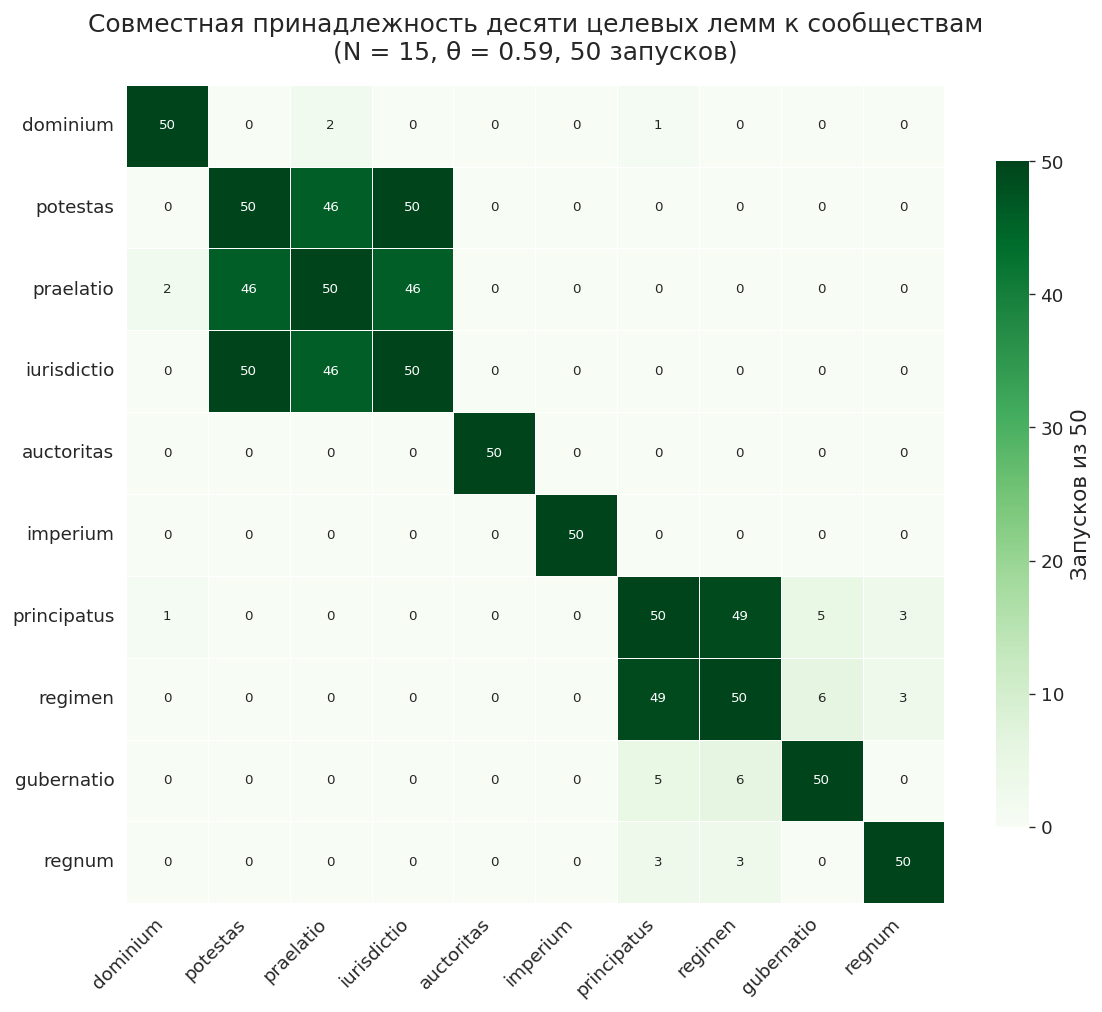

Сохранена таблица: ..\tables\co_membership_N15.csv


In [16]:
base_counts = together[TOP_N]
order_stability = sorted(TARGET_TERMS, key=lambda t: (membership[t], TARGET_TERMS.index(t)))
base_counts = base_counts.loc[order_stability, order_stability]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(base_counts, cmap="Greens", vmin=0, vmax=N_LEIDEN_RUNS,
            annot=True, fmt="d", annot_kws={"size": 8}, linewidths=0.4,
            linecolor="white", square=True,
            cbar_kws={"label": f"Запусков из {N_LEIDEN_RUNS}", "shrink": 0.8}, ax=ax)
ax.set_title("Совместная принадлежность десяти целевых лемм к сообществам\n"
             f"(N = {TOP_N}, θ = {THRESHOLD:.2f}, {N_LEIDEN_RUNS} запусков)", pad=15)
plt.xticks(rotation=45, ha="right")
save_figure(fig, "robustness_co_membership")
save_table(base_counts, "co_membership_N15")

### 12.2. Сопоставление матриц для N = 10 и N = 20

Матрица N = 15 построена в предыдущей ячейке и не изменяется. Ниже два дополнительных варианта показаны рядом, в том же порядке целевых лемм. Все изображения сохраняются **только в PNG**. Числа обозначают совместную принадлежность к сообществу из 50 запусков алгоритма Лейдена.


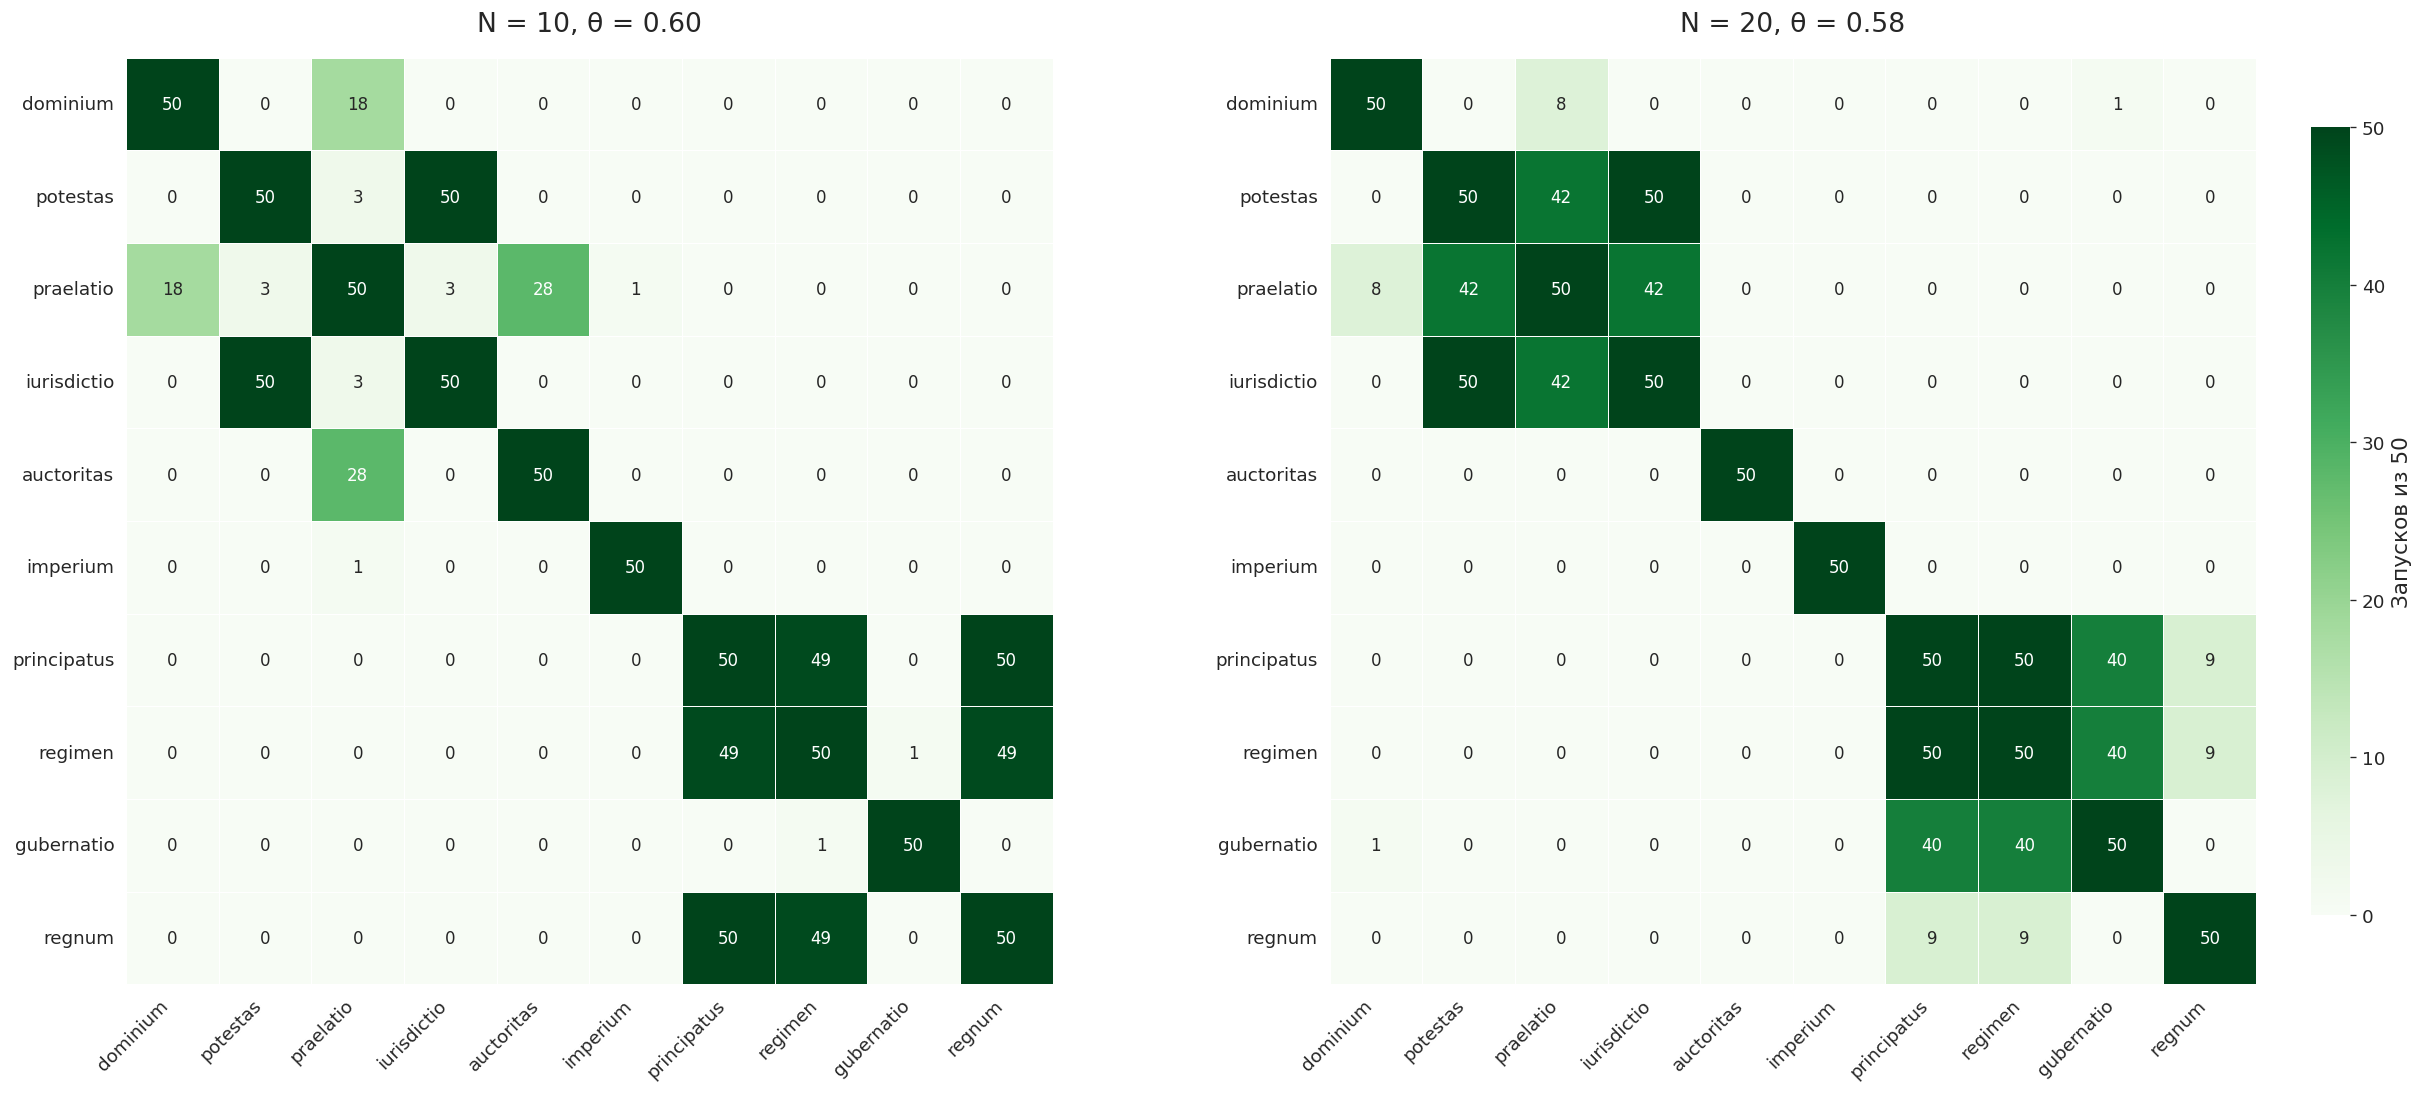

Сохранены PNG для N = 10 и 20 в ..\figures


In [17]:
# Две матрицы рядом: дополнительные проверки N = 10 и N = 20.
# Используются уже рассчитанные together[n] и order_stability.
# Никаких повторных запусков Лейдена, никаких PDF и SVG.
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(20, 9), constrained_layout=True)
for ax, n in zip(axes, (10, 20)):
    counts = together[n].loc[order_stability, order_stability]
    sns.heatmap(counts, cmap="Greens", vmin=0, vmax=N_LEIDEN_RUNS,
                annot=True, fmt="d", annot_kws={"size": 10}, square=True,
                linewidths=0.4, linecolor="white", ax=ax,
                cbar=(n == 20), cbar_kws={"label": f"Запусков из {N_LEIDEN_RUNS}", "shrink": .85})
    ax.set_title(f"N = {n}, θ = {networks[n]['threshold']:.2f}", fontsize=16, pad=16)
    ax.tick_params(labelsize=11)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

save_figure(fig, "robustness_matrices_N10_N20")

# Отдельные полноразмерные PNG пригодятся для размещения матриц в приложении.
# Не выводим их повторно в ноутбуке.
for n in (10, 20):
    counts = together[n].loc[order_stability, order_stability]
    fig_single, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(counts, cmap="Greens", vmin=0, vmax=N_LEIDEN_RUNS,
                annot=True, fmt="d", annot_kws={"size": 9}, square=True,
                linewidths=.4, linecolor="white", ax=ax,
                cbar_kws={"label": f"Запусков из {N_LEIDEN_RUNS}", "shrink": .8})
    ax.set_title(f"Совместная принадлежность десяти лемм (N = {n}, "
                 f"θ = {networks[n]['threshold']:.2f})", pad=15)
    ax.tick_params(labelsize=11)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig_single.savefig(f"{FIG_DIR}/robustness_co_membership_N{n}.png",
                       dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    plt.close(fig_single)
print("Сохранены PNG для N = 10 и 20 в", FIG_DIR)


## 13. Проверка чувствительности к повышению порога

Проверяется, как меняется связность основной сети при повышении порога на 0,01: число компонент, состав отделившихся частей и наличие среди них целевых лемм. Этот анализ не требует запуска алгоритма Лейдена.

In [18]:
base_net = networks[TOP_N]
next_threshold = round(base_net["threshold"] + 0.01, 2)
g_next = build_network(base_net["lemmas"], base_net["similarity"], next_threshold)
parts = sorted(nx.connected_components(g_next), key=len, reverse=True)
detached = set().union(*parts[1:]) if len(parts) > 1 else set()

print(f"θ = {base_net['threshold']:.2f}: компонент {nx.number_connected_components(base_net['graph'])}")
print(f"θ = {next_threshold:.2f}: компонент {len(parts)}, размеры {[len(p) for p in parts]}")
print("Отделившиеся леммы:", ", ".join(sorted(detached)) or "–")
print("Целевые леммы среди них:", ", ".join(t for t in TARGET_TERMS if t in detached) or "–")

bridges = [(u, v, round(d["weight"], 3)) for u, v, d in base_net["graph"].edges(data=True)
           if (u in detached) != (v in detached)]
display(Markdown(f"**Связи, которые при θ = {base_net['threshold']:.2f} соединяли отделившуюся часть с остальной сетью**"))
display(pd.DataFrame(bridges, columns=["Лемма 1", "Лемма 2", "Косинусное сходство"])
        .sort_values("Косинусное сходство", ascending=False).reset_index(drop=True))

θ = 0.59: компонент 1
θ = 0.60: компонент 2, размеры [121, 1]
Отделившиеся леммы: possideo
Целевые леммы среди них: –


**Связи, которые при θ = 0.59 соединяли отделившуюся часть с остальной сетью**

,Лемма 1,Лемма 2,Косинусное сходство
0,possideo,regnum,0.594


In [19]:
# Сводные показатели основного сетевого анализа
summary = pd.Series({
    "Целевых лемм": len(TARGET_TERMS),
    "Соседей на целевую лемму (N)": TOP_N,
    "Узлов основной сети": G.number_of_nodes(),
    "Рёбер основной сети": G.number_of_edges(),
    "Порог θ": THRESHOLD,
    "Сообществ медоида": len(communities),
    "Модулярность Q медоида": round(float(Q), 4),
    "seed медоида": medoid_seed,
    "Среднее расхождение медоида": round(float(medoid_distances[medoid_seed]), 5),
    "Запусков Лейдена": N_LEIDEN_RUNS,
}, name="Сетевой анализ обозначений власти")
display(summary.to_frame())
save_table(summary.to_frame(), "analysis_summary")


,Сетевой анализ обозначений власти
Целевых лемм,10.00000
Соседей на целевую лемму (N),15.00000
Узлов основной сети,122.00000
Рёбер основной сети,715.00000
Порог θ,0.59000
Сообществ медоида,7.00000
Модулярность Q медоида,0.49450
seed медоида,0.00000
Среднее расхождение медоида,0.01334
Запусков Лейдена,50.00000


Сохранена таблица: ..\tables\analysis_summary.csv


## 14. Сводка исследования и ограничения

Сводная таблица выше содержит размер и плотность основной сети, выбранный порог, число сообществ, модулярность медоида и параметры повторных запусков. Для интерпретации используются также полные списки сообществ, таблицы ближайших соседей, матрица косинусного сходства и результаты проверок при N = 10, 15 и 20.

**Что проверяют расчёты.** Сходство векторов характеризует дистрибутивную близость лемм в данной модели. Сообщества показывают структуру связей в заданной сети, но не тождественны значениям слов или строго разграниченным понятиям автора. Изменение N и начального значения Лейдена проверяет устойчивость сетевого результата, но не устойчивость самой модели fastText при повторном обучении.

**Выходные файлы.** Таблицы в кодировке UTF-8 записываются в `tables/`. В `figures/` сохраняются общая сеть (`figure_1_network.png`), матрица сходства (`figure_2_similarity_matrix.png`) и технические рисунки распределения сходства и проверок. Графы всех семи сообществ сохраняются только в `figures/communities/`. В статье используются два из них: `community_medoid_2_potestas.png` (Рисунок 3) и `community_medoid_5_principatus.png` (Рисунок 5). **Все десять локальных сетей сохраняются только в `figures/local_networks/`**. В статье используются `local_6_4_potestas.png` (Рисунок 4), `local_6_4_regimen.png` (Рисунок 6) и `local_6_4_principatus.png` (Рисунок 7). Для проверки устойчивости статья использует таблицу 45 пар (в основной части показаны 13 ненулевых), а полные матрицы N = 10, 15 и 20 предназначены для приложения.


## 15. Дополнительные эксперименты: качество словаря, k-NN, дендрограмма и низкие частоты

**Этот раздел не изменяет основной анализ (разделы 1–14).** Все проверки используют опубликованную модель *Opera Maiora* и уже созданный словарь основной сети.

1. Диагностика частот, совпадающих векторов и буквенного сходства (без удаления слов).
2. Альтернативный граф union k-NN (`k = 8`) на **том же** словаре.
3. Иерархическая кластеризация десяти целевых лемм в исходном векторном пространстве.
4. Частотная абляция: исключение из **готового словаря основной сети** нецелевых лемм с частотой ниже 10, с неизменным порогом `θ` и 50 новыми запусками Лейдена.

Число узлов рассчитывается по фактическому составу словаря, а не задаётся заранее. Экспериментальные таблицы сохраняются как `tables/experiment_*.csv`, рисунки — в `figures/experiments/`. Ранее созданные UMAP-файлы, если они остались в папке после прежних запусков, автоматически не удаляются.

### 15.1. Частоты, почти одинаковые векторы и символьные n-граммы

**Важно различать три объекта.** (а) Словарь `wv.index_to_key` содержит леммы обучающего корпуса, (б) fastText использовал символьные n-граммы как внутренние компоненты представлений слов, (в) однокоренные и орфографически близкие леммы действительно могут оказаться близкими соседями. В `load_lila_model` исходная модель преобразована в `KeyedVectors`, поэтому внутренние бакеты n-грамм не являются отдельными словарными записями или узлами сети.

Мы проверяем косинус ≥ 0,9999 (на случай численной погрешности) и показываем 30 наиболее близких пар **по всему словарю модели**. Так как `all_similarities` уже вычислены в разделе 4, повторно матрица попарных сходств не строится. Пара с косинусом около 1 требует проверки, но сама по себе **не доказывает**, что перед нами n-грамма. Более того, при отсутствии таких пар фильтр не срабатывает — это тоже результат.

Отдельно показываем частоты **всех 200 (или фактически полученных) узлов** основной сети и 150 пар «целевая лемма — сосед». **Никакая лемма автоматически не исключается.**

In [20]:
import re

EXP_FIG_DIR = os.path.join(FIG_DIR, "experiments")
os.makedirs(EXP_FIG_DIR, exist_ok=True)
FREQ_WARNING = 10              # диагностический ориентир, НЕ фильтр
NEAR_COSINE = 0.9999           # практически совпадающие векторы (допуск численной ошибки)
SHOW_TOP_PAIRS = 30            # ближайшие пары всего словаря для ручной проверки

# Из метаданных бинарной fastText-модели получаем диапазон длин символьных n-грамм.
_ngram_lengths = list(map(int, re.findall(r"\d+", str(MODEL_PARAMS["Длина n-грамм символов"]))))
if len(_ngram_lengths) != 2:
    raise ValueError("Не удалось определить min_n и max_n из параметров модели.")
MIN_CHAR_N, MAX_CHAR_N = _ngram_lengths


def char_ngrams(word, min_n=MIN_CHAR_N, max_n=MAX_CHAR_N):
    # Сравнение написаний. Это НЕ доступ к обученным векторам бакетов fastText.
    spelling = "<" + word + ">"
    return {spelling[i:i+n] for n in range(min_n, max_n + 1)
            for i in range(len(spelling) - n + 1)}


def char_overlap(word1, word2):
    s1, s2 = char_ngrams(word1), char_ngrams(word2)
    return len(s1 & s2) / len(s1 | s2) if (s1 | s2) else 0.0


freq_audit = pd.DataFrame([
    {"Лемма": w, "Частота": int(freq(w)), "Целевая лемма": w in TARGET_TERMS,
     f"Частота < {FREQ_WARNING}": int(freq(w)) < FREQ_WARNING}
    for w in lemmas
]).sort_values(["Частота", "Лемма"]).reset_index(drop=True)
print(f"Основной словарь: {len(freq_audit)} лемм; частота < {FREQ_WARNING}: "
      f"{int(freq_audit[f'Частота < {FREQ_WARNING}'].sum())}; "
      f"частота < 20: {int((freq_audit['Частота'] < 20).sum())}.")
display(Markdown("**Наименее частотные узлы основной сети (первые 30)**"))
display(freq_audit.head(30))
save_table(freq_audit.set_index("Лемма"), "experiment_frequency_nodes")

# Частота каждого из Top-15 соседей + совпадение символьных n-грамм с целевой леммой.
neighbor_audit = pd.DataFrame([
    {"Целевая лемма": target, "Ранг": rank, "Сосед": word,
     "Косинус": float(sim), "Частота соседа": int(freq(word)),
     "Сходство символьных n-грамм (Жаккар)": round(char_overlap(target, word), 3),
     "Частота < 10": int(freq(word)) < FREQ_WARNING}
    for target in TARGET_TERMS
    for rank, (word, sim) in enumerate(neighbours[target], start=1)
])
display(Markdown("**Самые редкие соседи целевых лемм (первые 25)**"))
display(neighbor_audit.sort_values(["Частота соседа", "Косинус"],
                                    ascending=[True, False]).head(25))
save_table(neighbor_audit, "experiment_frequency_neighbors")

# В ячейке 4 all_similarities собран построчно по верхнему треугольнику
# полной матрицы косинусов. Восстанавливаем словарные индексы (i, j)
# без повторного умножения матриц.
n_vocab = len(wv)
expected_pairs = n_vocab * (n_vocab - 1) // 2
assert len(all_similarities) == expected_pairs, "Неожиданное число пар в all_similarities"
row_ends = np.cumsum(np.arange(n_vocab - 1, 0, -1, dtype=np.int64))

def flat_upper_to_word_pairs(flat_indices):
    idx = np.asarray(flat_indices, dtype=np.int64)
    i = np.searchsorted(row_ends, idx, side="right")
    before = np.where(i > 0, row_ends[np.maximum(0, i - 1)], 0)
    j = i + 1 + idx - before
    return i, j

near_idx = np.flatnonzero(all_similarities >= NEAR_COSINE)
top_n = min(SHOW_TOP_PAIRS, len(all_similarities))
top_idx = np.argpartition(all_similarities, -top_n)[-top_n:]
selected = np.unique(np.concatenate((near_idx, top_idx)))
selected = selected[np.argsort(all_similarities[selected])[::-1]]
i_vals, j_vals = flat_upper_to_word_pairs(selected)

full_pair_audit = pd.DataFrame([
    {"Лемма 1": wv.index_to_key[int(i)], "Лемма 2": wv.index_to_key[int(j)],
     "Косинус": float(all_similarities[int(flat)]),
     "Частота 1": int(freq(wv.index_to_key[int(i)])),
     "Частота 2": int(freq(wv.index_to_key[int(j)])),
     "Сходство символьных n-грамм (Жаккар)": round(char_overlap(
         wv.index_to_key[int(i)], wv.index_to_key[int(j)]), 3),
     "Косинус >= 0.9999": bool(all_similarities[int(flat)] >= NEAR_COSINE)}
    for flat, i, j in zip(selected, i_vals, j_vals)
])
near_full = full_pair_audit.loc[full_pair_audit["Косинус >= 0.9999"]].copy()
print(f"По всему словарю: пары с косинусом ≥ 0,99: {np.count_nonzero(all_similarities >= 0.99)}; "
      f"≥ 0,999: {np.count_nonzero(all_similarities >= 0.999)}; "
      f"≥ {NEAR_COSINE}: {len(near_idx)}.")
if near_full.empty:
    print("Пар с практически одинаковыми векторами нет. Это не исключает влияния субсловных признаков.")
else:
    display(Markdown("**Все пары с косинусом ≥ 0,9999**"))
    display(near_full)
display(Markdown(f"**{top_n} наиболее близких пар в словаре модели**"))
display(full_pair_audit.head(top_n))
save_table(near_full, "experiment_near_identical_pairs")
save_table(full_pair_audit, "experiment_top_cosine_pairs")

# Дублированный список попарных сходств освобождаем НЕ будем:
# он используется только до этого раздела и может пригодиться для повторной диагностики.

Основной словарь: 122 лемм; частота < 10: 20; частота < 20: 40.


**Наименее частотные узлы основной сети (первые 30)**

,Лемма,Частота,Целевая лемма,Частота < 10
0,assertiuus,5,False,True
1,auctoritatiuus,5,False,True
2,celatio,5,False,True
3,diaconatus,5,False,True
4,iurisconsultus,5,False,True
5,optimas,5,False,True
6,persuasibilis,5,False,True
7,plebeius,5,False,True
8,declaratio,6,False,True
9,imperitus,6,False,True


Сохранена таблица: ..\tables\experiment_frequency_nodes.csv


**Самые редкие соседи целевых лемм (первые 25)**

,Целевая лемма,Ранг,Сосед,Косинус,Частота соседа,Сходство символьных n-грамм (Жаккар),Частота < 10
61,auctoritas,2,auctoritatiuus,0.771644,5,0.448,True
30,praelatio,1,celatio,0.734457,5,0.368,True
98,principatus,9,optimas,0.700884,5,0.000,True
109,regimen,5,optimas,0.696005,5,0.000,True
63,auctoritas,4,assertiuus,0.670805,5,0.000,True
58,iurisdictio,14,diaconatus,0.661867,5,0.000,True
34,praelatio,5,plebeius,0.656586,5,0.000,True
86,imperium,12,persuasibilis,0.594017,5,0.014,True
10,dominium,11,iurisconsultus,0.592537,5,0.000,True
60,auctoritas,1,subauctoritas,0.869555,6,0.600,True


Сохранена таблица: ..\tables\experiment_frequency_neighbors.csv
По всему словарю: пары с косинусом ≥ 0,99: 0; ≥ 0,999: 0; ≥ 0.9999: 0.
Пар с практически одинаковыми векторами нет. Это не исключает влияния субсловных признаков.


**30 наиболее близких пар в словаре модели**

,Лемма 1,Лемма 2,Косинус,Частота 1,Частота 2,Сходство символьных n-грамм (Жаккар),Косинус >= 0.9999
0,constantinopolitanus,constantinopolis,0.977259,16,6,0.617,False
1,architectonicus,architecton,0.976576,22,5,0.586,False
2,quadragesimalis,quadragesima,0.968276,14,13,0.655,False
3,architector,architecton,0.968085,13,5,0.652,False
4,assumptibilis,inassumptibilis,0.967196,77,6,0.724,False
5,sagitta,sagitto,0.966998,45,26,0.467,False
6,coniectura,coniecturo,0.965159,28,6,0.619,False
7,adiectiuus,adiectiuum,0.963954,90,8,0.619,False
8,transubstantiatio,transubstantio,0.963634,73,21,0.672,False
9,coniectura,coniecturalis,0.963624,28,15,0.600,False


Сохранена таблица: ..\tables\experiment_near_identical_pairs.csv
Сохранена таблица: ..\tables\experiment_top_cosine_pairs.csv


### 15.2. Альтернативная сеть: union k-NN (k = 8)

Используется **тот же набор лемм**, что и в основной сети. Для каждой леммы выбираются её восемь ближайших соседей **внутри выбранного словаря основной сети**. Неориентированное ребро сохраняется, если выбор сделан хотя бы с одной стороны (union). Его весом остаётся исходное косинусное сходство. Самопетли исключены.

В отличие от основного порога 0,59, здесь нет абсолютного отсечения. Результат сравнивается с основной сетью по рёбрам, числу компонент и попарной совместной принадлежности **45 пар целевых лемм** в 50 запусках Лейдена. Ни ARI, ни оптимизация других функций качества не применяются. Номера сообществ разных сетей напрямую сравнивать нельзя.

**Общая характеристика двух сетей**

,Узлов,Рёбер,Компонент,Сообществ в медоиде,Модулярность медоида
Граф,,,,,
Основной пороговый,122,715,1,7,0.494545
union k-NN (k=8),122,659,1,6,0.567407


Общих рёбер: 514; доля от рёбер основного графа: 71.9%; доля от рёбер k-NN: 78.0%.
Сохранена таблица: ..\tables\experiment_knn_network_comparison.csv


**Пары с наибольшим изменением совместной принадлежности (первые 20)**

,Основная сеть: вместе из 50,k-NN: вместе из 50,Разница (k-NN минус основная),Основной медоид: вместе,k-NN медоид: вместе
Пара,,,,,
principatus – regnum,3,50,47,False,True
dominium – praelatio,2,48,46,False,True
praelatio – iurisdictio,46,1,-45,True,False
potestas – praelatio,46,2,-44,True,False
regimen – regnum,3,45,42,False,True
principatus – gubernatio,5,0,-5,False,False
principatus – regimen,49,45,-4,True,True
regimen – gubernatio,6,5,-1,False,False
dominium – principatus,1,0,-1,False,False


Сохранена таблица: ..\tables\experiment_knn_target_pairs.csv


**Положение десяти обозначений власти в двух сетях**

,Основное сообщество (номер внутри сети),k-NN сообщество (номер внутри сети),Частота
Лемма,,,
dominium,1,1,287
potestas,2,2,2527
praelatio,2,1,249
iurisdictio,2,2,97
auctoritas,3,3,1363
imperium,4,4,449
principatus,5,5,160
regimen,5,5,189
gubernatio,6,6,248


Сохранена таблица: ..\tables\experiment_knn_target_communities.csv
Сохранена таблица: ..\tables\experiment_knn_edges.csv


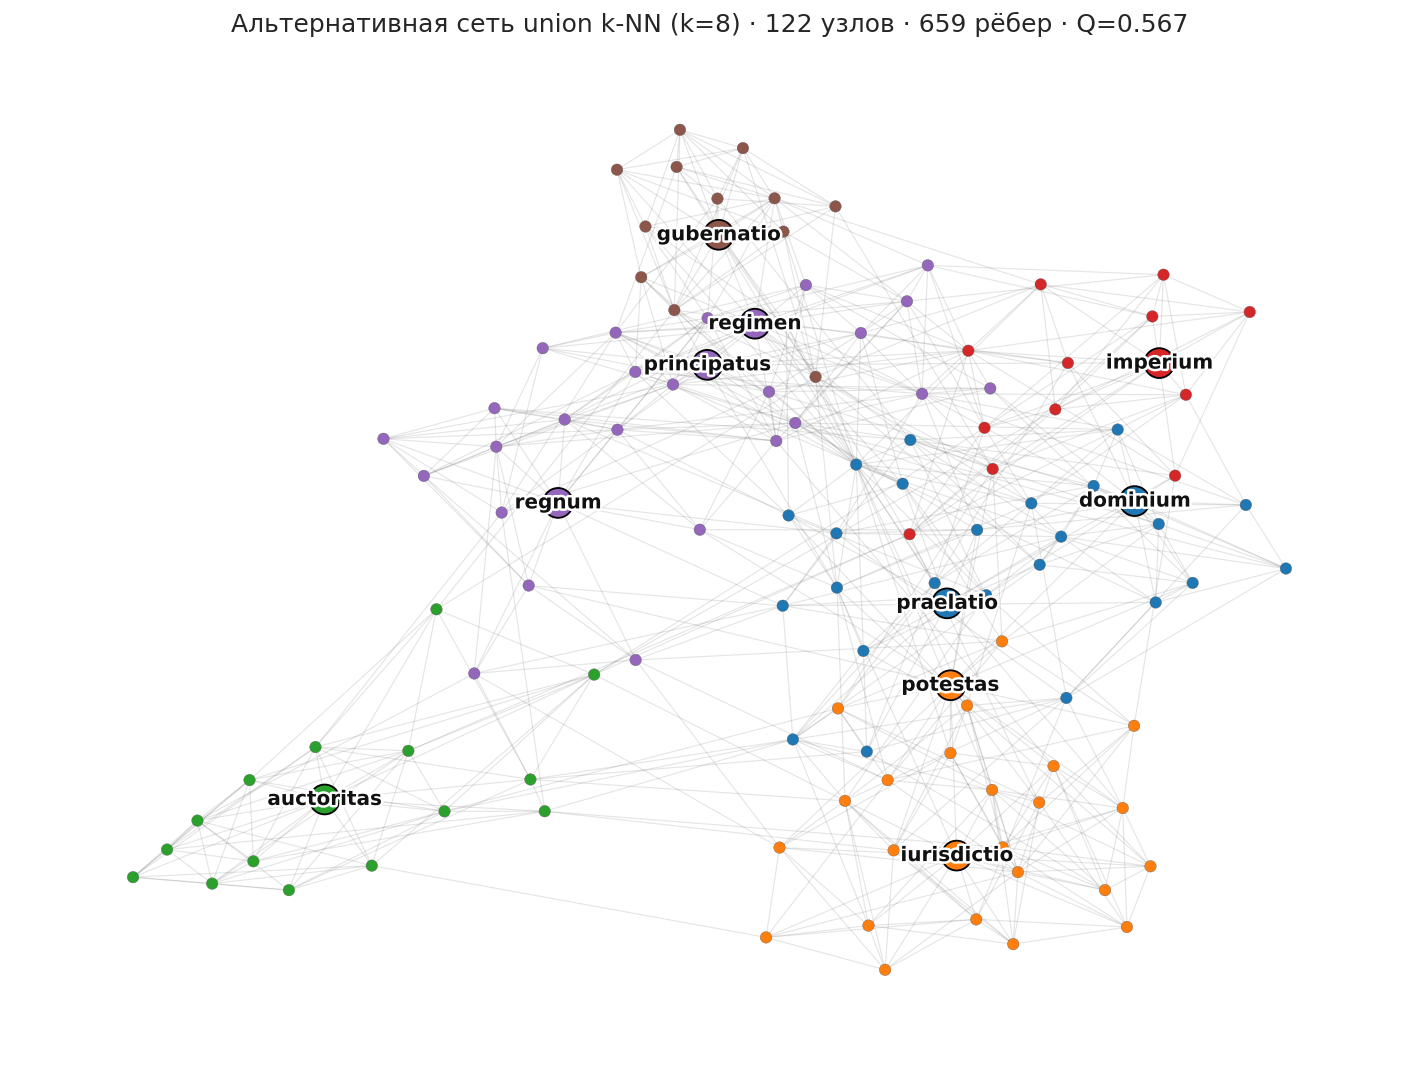

In [21]:
EXPERIMENT_K = 8                   # один вариант для разведочного сравнения


def build_union_knn(words, cosine_matrix, k=EXPERIMENT_K):
    """Неориентированный union k-NN на фиксированном словаре, с весами cosine."""
    n = len(words)
    if not 1 <= k < n:
        raise ValueError("Требуется 1 <= k < число узлов")
    s = np.asarray(cosine_matrix, dtype=float).copy()
    np.fill_diagonal(s, -np.inf)
    ids = np.arange(n)
    selected = np.zeros((n, n), dtype=bool)
    for i in range(n):
        # Устойчивое разрешение точных совпадений через индекс слова.
        nearest = np.lexsort((ids, -s[i]))[:k]
        selected[i, nearest] = True
    keep = selected | selected.T
    g = nx.Graph()
    g.add_nodes_from(words)
    for i, j in zip(*np.where(np.triu(keep, k=1))):
        g.add_edge(words[i], words[j], weight=float(cosine_matrix[i, j]),
                   reciprocal=bool(selected[i, j] and selected[j, i]))
    return g


G_knn = build_union_knn(lemmas, similarity)
knn_runs = [leiden(G_knn, seed=s) for s in range(N_LEIDEN_RUNS)]
knn_medoid_seed, knn_medoid_distances = partition_medoid(G_knn, knn_runs)
knn_membership, knn_Q = knn_runs[knn_medoid_seed]
knn_counts = co_membership(knn_runs)

base_edges = {frozenset(e) for e in G.edges()}
knn_edges = {frozenset(e) for e in G_knn.edges()}
base_knn_intersection = len(base_edges & knn_edges)

knn_network_comparison = pd.DataFrame([
    {"Граф": "Основной пороговый", "Узлов": len(G), "Рёбер": G.number_of_edges(),
     "Компонент": nx.number_connected_components(G), "Сообществ в медоиде": len(set(membership.values())),
     "Модулярность медоида": float(Q)},
    {"Граф": f"union k-NN (k={EXPERIMENT_K})", "Узлов": len(G_knn),
     "Рёбер": G_knn.number_of_edges(), "Компонент": nx.number_connected_components(G_knn),
     "Сообществ в медоиде": len(set(knn_membership.values())),
     "Модулярность медоида": float(knn_Q)}
]).set_index("Граф")
display(Markdown("**Общая характеристика двух сетей**"))
display(knn_network_comparison)
print(f"Общих рёбер: {base_knn_intersection}; "
      f"доля от рёбер основного графа: {base_knn_intersection / max(len(base_edges),1):.1%}; "
      f"доля от рёбер k-NN: {base_knn_intersection / max(len(knn_edges),1):.1%}.")
save_table(knn_network_comparison, "experiment_knn_network_comparison")

knn_target_pairs = pd.DataFrame([
    {"Пара": f"{a} – {b}", "Основная сеть: вместе из 50": int(together[TOP_N].loc[a, b]),
     "k-NN: вместе из 50": int(knn_counts.loc[a, b]),
     "Разница (k-NN минус основная)": int(knn_counts.loc[a, b] - together[TOP_N].loc[a, b]),
     "Основной медоид: вместе": membership[a] == membership[b],
     "k-NN медоид: вместе": knn_membership[a] == knn_membership[b]}
    for a, b in KEY_PAIRS
]).set_index("Пара")
display(Markdown("**Пары с наибольшим изменением совместной принадлежности (первые 20)**"))
display(knn_target_pairs.reindex(
    knn_target_pairs["Разница (k-NN минус основная)"].abs().sort_values(
        ascending=False).index
).head(20))
save_table(knn_target_pairs, "experiment_knn_target_pairs")

knn_communities = pd.DataFrame([
    {"Лемма": term, "Основное сообщество (номер внутри сети)": membership[term],
     "k-NN сообщество (номер внутри сети)": knn_membership[term],
     "Частота": int(freq(term))}
    for term in TARGET_TERMS
]).set_index("Лемма")
display(Markdown("**Положение десяти обозначений власти в двух сетях**"))
display(knn_communities)
save_table(knn_communities, "experiment_knn_target_communities")

knn_edge_table = pd.DataFrame([
    {"Лемма 1": u, "Лемма 2": v, "Косинус": float(d["weight"]),
     "Выбор взаимный": bool(d["reciprocal"])}
    for u, v, d in G_knn.edges(data=True)
])
save_table(knn_edge_table, "experiment_knn_edges")

# Небольшая техническая визуализация альтернативного графа.
fig, ax = plt.subplots(figsize=(15, 11))
knn_pos = nx.spring_layout(G_knn, weight="weight", seed=SEED, iterations=300)
knn_groups = sorted(set(knn_membership.values()))
knn_palette = sns.color_palette("tab10" if len(knn_groups) <= 10 else "tab20", len(knn_groups))
knn_colors = {c: knn_palette[i] for i, c in enumerate(knn_groups)}
nx.draw_networkx_edges(G_knn, knn_pos, ax=ax, alpha=0.17, width=0.7, edge_color="#666666")
nx.draw_networkx_nodes(G_knn, knn_pos, nodelist=[w for w in G_knn if w not in TARGET_TERMS],
                       node_size=48, node_color=[knn_colors[knn_membership[w]]
                                                  for w in G_knn if w not in TARGET_TERMS],
                       linewidths=0.2, edgecolors="#555555", ax=ax)
nx.draw_networkx_nodes(G_knn, knn_pos, nodelist=TARGET_TERMS, node_size=320,
                       node_color=[knn_colors[knn_membership[w]] for w in TARGET_TERMS],
                       linewidths=1.1, edgecolors="black", ax=ax)
for term in TARGET_TERMS:
    lbl = ax.text(*knn_pos[term], term, fontsize=12, weight="bold", zorder=5,
                  ha="center", va="center", color="#111111")
    white_outline(lbl, 3)
ax.set_title(f"Альтернативная сеть union k-NN (k={EXPERIMENT_K}) · "
             f"{G_knn.number_of_nodes()} узлов · {G_knn.number_of_edges()} рёбер · Q={knn_Q:.3f}")
ax.axis("off")
save_figure(fig, "experiment_knn_network", folder=EXP_FIG_DIR)

### 15.3. Дендрограмма десяти целевых терминов

Это **не граф Лейдена**: кластеризуются **только десять целевых слов** непосредственно по их векторам, без остальных узлов сетевого словаря. Параметры зафиксированы: метрика `cosine`, связь `average` (среднее расстояние между членами групп), `optimal_ordering=True` (меняет лишь порядок листьев для наглядности). В алгоритме нет случайной инициализации; число кластеров и уровень разрезания дендрограммы не задаются.

Для примера, при желании позже можно проверить `complete linkage`, но **в этом разведочном расчёте только `average`**. Метод `ward` здесь не используется, поскольку он предполагает евклидову геометрию.

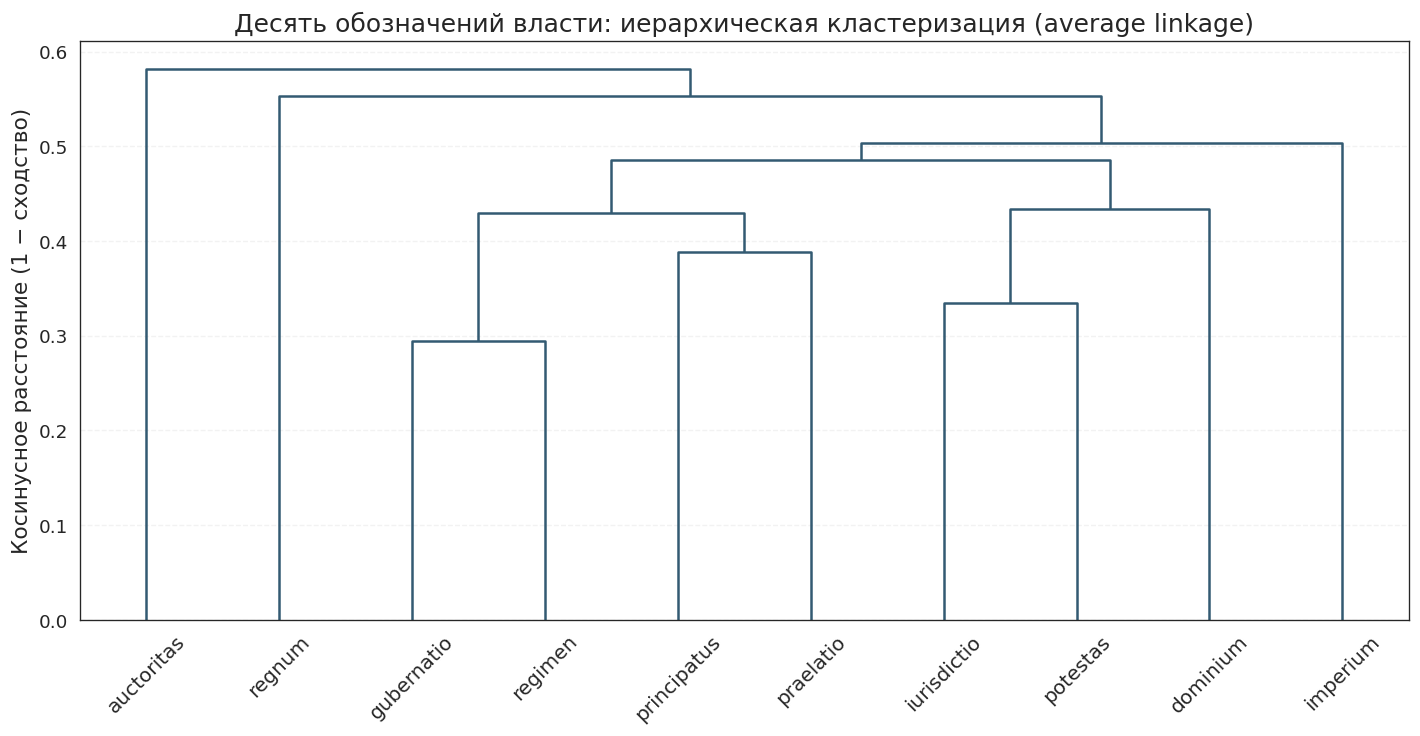

**Последовательность объединений целевых лемм**

,Группа 1,Группа 2,Косинусное расстояние при объединении,Число лемм в объединении
Шаг,,,,
1,gubernatio,regimen,0.294510,2
2,iurisdictio,potestas,0.334937,2
3,principatus,praelatio,0.388189,2
4,"gubernatio, regimen","principatus, praelatio",0.429627,4
5,"iurisdictio, potestas",dominium,0.433684,3
6,"gubernatio, regimen, principatus, praelatio","iurisdictio, potestas, dominium",0.485355,7
7,"gubernatio, regimen, principatus, praelatio, i...",imperium,0.503425,8
8,regnum,"gubernatio, regimen, principatus, praelatio, i...",0.553480,9
9,auctoritas,"regnum, gubernatio, regimen, principatus, prae...",0.581783,10


Сохранена таблица: ..\tables\experiment_hierarchical_merges.csv
Дендрограмма сохранена. Следующий эксперимент: исключение редких лемм.


In [22]:
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram

X_terms = np.array([wv.get_vector(w) for w in TARGET_TERMS], dtype=np.float64)
cos_dist_condensed = pdist(X_terms, metric="cosine")
Z_terms = linkage(cos_dist_condensed, method="average", optimal_ordering=True)

fig, ax = plt.subplots(figsize=(12, 6.3))
dendrogram(Z_terms, labels=TARGET_TERMS, leaf_rotation=45, leaf_font_size=12,
           color_threshold=0, above_threshold_color="#335a72", ax=ax)
ax.set_title("Десять обозначений власти: иерархическая кластеризация (average linkage)")
ax.set_ylabel("Косинусное расстояние (1 − сходство)")
ax.grid(axis="y", linestyle="--", alpha=0.25)
fig.tight_layout()
save_figure(fig, "experiment_target_dendrogram", folder=EXP_FIG_DIR)

# Таблица девяти последовательных объединений кластеров для интерпретации.
clusters = {i: [term] for i, term in enumerate(TARGET_TERMS)}
merge_rows = []
for step, (a, b, distance, size) in enumerate(Z_terms, start=1):
    a, b = int(a), int(b)
    merge_rows.append({
        "Шаг": step,
        "Группа 1": ", ".join(clusters[a]),
        "Группа 2": ", ".join(clusters[b]),
        "Косинусное расстояние при объединении": float(distance),
        "Число лемм в объединении": int(size),
    })
    clusters[len(TARGET_TERMS) + step - 1] = clusters[a] + clusters[b]
merge_table = pd.DataFrame(merge_rows).set_index("Шаг")
display(Markdown("**Последовательность объединений целевых лемм**"))
display(merge_table)
save_table(merge_table, "experiment_hierarchical_merges")

print("Дендрограмма сохранена. Следующий эксперимент: исключение редких лемм.")

### 15.4. Проверка с исключением низкочастотных лемм (частота < 10)

**Задача:** проверить, меняются ли основные отношения между десятью обозначениями власти, если удалить редкие слова из уже построенной сети. Это *абляция узлов*, а не повторное формирование списков Top-15.

- Отбираем из исходного словаря `lemmas` все целевые термины и нецелевые леммы с частотой **не ниже 10**. Целевые термины принудительно сохраняются даже при меньшей частоте.
- **Не пополняем** списки соседей словами из последующих рангов.
- **Не пересчитываем порог**: используем тот же `THRESHOLD`, что у основной сети. Иначе эффект фильтра смешался бы с эффектом изменения порога.
- Рёбра между оставшимися леммами сохраняют прежние веса. Проводим **50 запусков Лейдена**, выбираем медоид по исходному правилу, рассчитываем совместную принадлежность всех 45 пар целевых терминов.
- Сопоставляем размер и компоненты графов, устойчивость целевых пар и ARI медоидных разбиений **только на общих узлах**. Учитываем, что значения модулярности относятся к различным графам и не могут напрямую служить оценкой «лучше/хуже».

Порог частоты 10 используется как диагностический эксперимент, **не как доказанная граница надёжности векторов**. При удалении лемм граф может стать несвязным — это фиксируется и не исправляется искусственно. При повторном запуске на реальных результатах в таблице будет видно, сколько слов действительно удалено.

Фильтр частоты < 10: удалено 20 из 122 лемм; осталось 102. Целевые термины сохранены.


**Исключённые нецелевые леммы**

,Частота,Исходное сообщество,Степень в основной сети
Лемма,,,
assertiuus,5,3,9
auctoritatiuus,5,3,7
celatio,5,2,18
diaconatus,5,2,11
iurisconsultus,5,1,20
optimas,5,5,21
persuasibilis,5,4,3
plebeius,5,1,15
declaratio,6,3,6


Сохранена таблица: ..\tables\experiment_lowfreq_removed.csv


**Параметры исходного и сокращённого графов**

,Узлов,Рёбер,Компонент,Сообществ,Модулярность Q,Порог θ
Вариант,,,,,,
Основная сеть (без фильтра),122,715,1,7,0.494545,0.59
Сеть после фильтра (частота ≥ 10),102,506,1,8,0.483785,0.59


... (3 outputs left out)

Сохранена таблица: ..\tables\experiment_lowfreq_target_communities.csv


**Самые заметные изменения совместной принадлежности (15 пар)**

,Исходный граф: вместе из 50,После фильтра: вместе из 50,Разница (фильтр − исходный),Исходный медоид: вместе,Медоид после фильтра: вместе
Пара,,,,,
potestas – praelatio,46,3,-43,True,False
praelatio – iurisdictio,46,3,-43,True,False
principatus – gubernatio,5,0,-5,False,False
regimen – gubernatio,6,1,-5,False,False
dominium – praelatio,2,0,-2,False,False
praelatio – gubernatio,0,2,2,False,False
dominium – principatus,1,0,-1,False,False
praelatio – regimen,0,1,1,False,False
regimen – regnum,3,2,-1,False,False


Сохранена таблица: ..\tables\experiment_lowfreq_target_pairs.csv
Сохранена таблица: ..\tables\experiment_lowfreq_parameters.csv


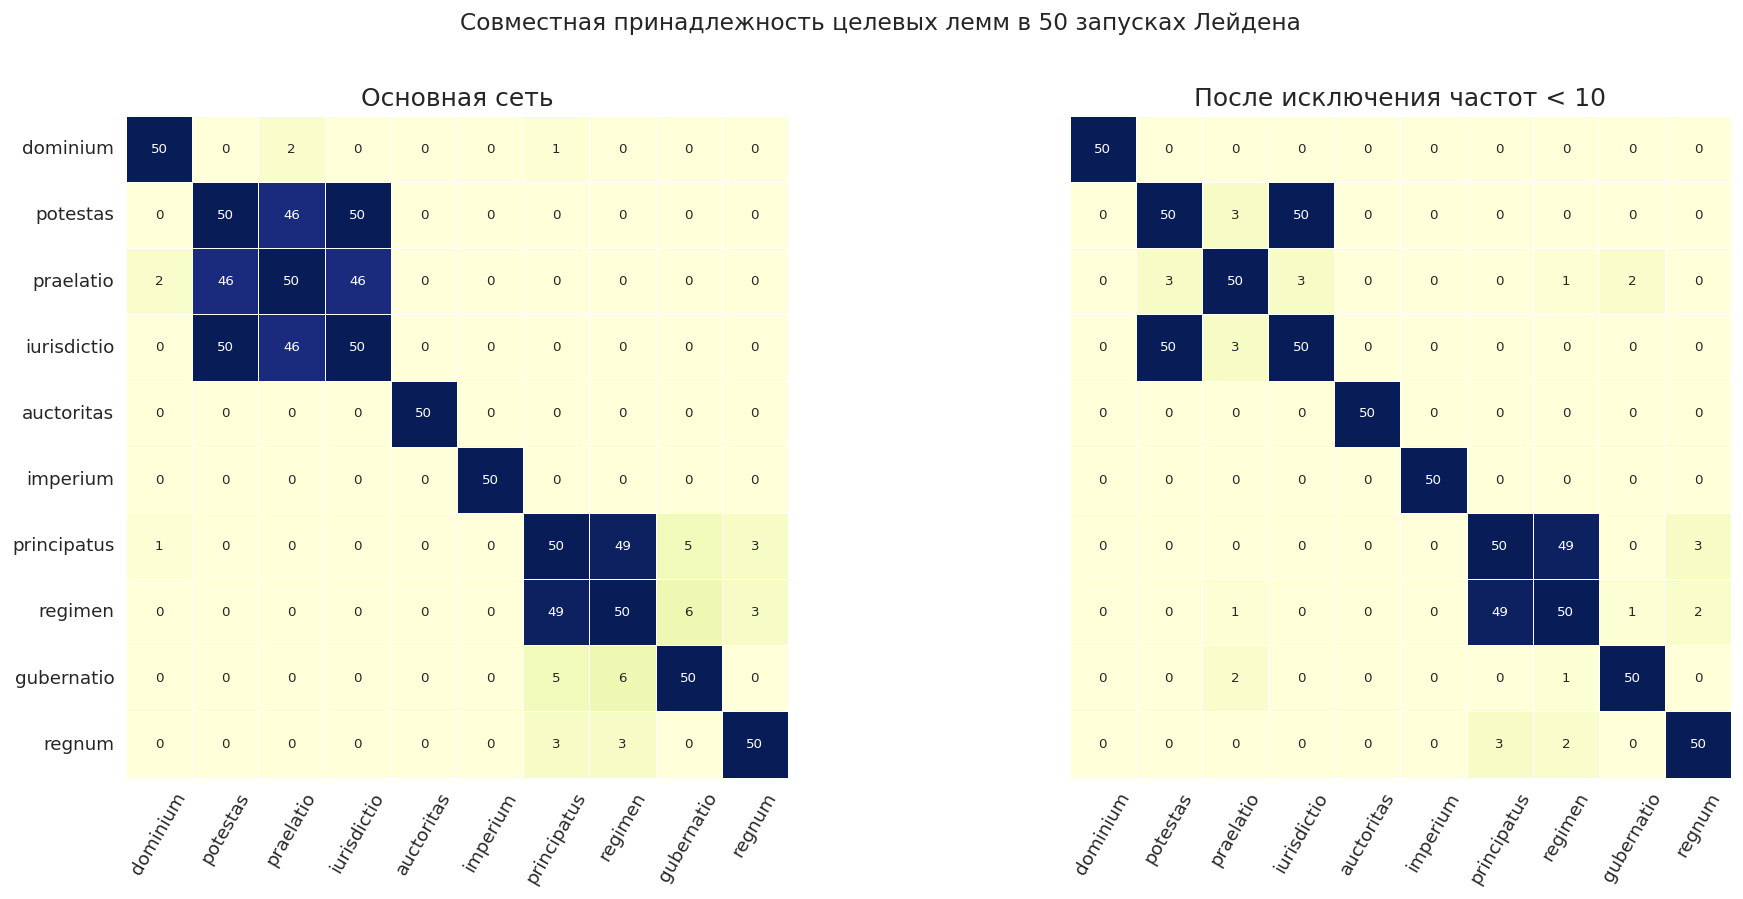

Частотная проверка завершена: результат записан в tables/experiment_lowfreq_*.csv


In [23]:
from sklearn.metrics import adjusted_rand_score

LOW_FREQ_MIN_COUNT = 10

# Частоты получены из бинарной fastText-модели (не из индексов словаря).
# Работаем с уже отобранным словарём основной сети: не подмешиваем новых соседей.
removed_lowfreq = [w for w in lemmas
                   if w not in TARGET_TERMS and int(freq(w)) < LOW_FREQ_MIN_COUNT]
kept_lowfreq = [w for w in lemmas if w not in set(removed_lowfreq)]
assert len(removed_lowfreq) + len(kept_lowfreq) == len(lemmas)
assert all(t in kept_lowfreq for t in TARGET_TERMS), "Целевые термины должны быть сохранены"

removed_lowfreq_table = pd.DataFrame([
    {"Лемма": w, "Частота": int(freq(w)),
     "Исходное сообщество": membership[w],
     "Степень в основной сети": int(G.degree(w))}
    for w in removed_lowfreq
], columns=["Лемма", "Частота", "Исходное сообщество", "Степень в основной сети"])
if not removed_lowfreq_table.empty:
    removed_lowfreq_table = removed_lowfreq_table.sort_values(["Частота", "Лемма"]).set_index("Лемма")
else:
    removed_lowfreq_table = removed_lowfreq_table.set_index("Лемма")
print(f"Фильтр частоты < {LOW_FREQ_MIN_COUNT}: удалено {len(removed_lowfreq)} "
      f"из {len(lemmas)} лемм; осталось {len(kept_lowfreq)}. Целевые термины сохранены.")
display(Markdown("**Исключённые нецелевые леммы**"))
display(removed_lowfreq_table)
save_table(removed_lowfreq_table, "experiment_lowfreq_removed")

# Вычисляем сходство в том же порядке, что при построении основной сети.
orig_positions = {w: i for i, w in enumerate(lemmas)}
keep_positions = [orig_positions[w] for w in kept_lowfreq]
filtered_cosines = similarity[np.ix_(keep_positions, keep_positions)]
G_lowfreq = build_network(kept_lowfreq, filtered_cosines, THRESHOLD)
assert set(G_lowfreq.nodes()) == set(kept_lowfreq)
assert set(map(frozenset, G_lowfreq.edges())) == {
    frozenset((u, v)) for u, v in G.edges()
    if u in G_lowfreq and v in G_lowfreq
}, "Ошибка: при неизменном пороге набор оставшихся рёбер должен совпадать"

lowfreq_runs = [leiden(G_lowfreq, seed=s) for s in range(N_LEIDEN_RUNS)]
lowfreq_medoid_seed, lowfreq_distances = partition_medoid(G_lowfreq, lowfreq_runs)
lowfreq_membership, lowfreq_Q = lowfreq_runs[lowfreq_medoid_seed]
lowfreq_counts = co_membership(lowfreq_runs)

# Сравниваем метки только в одинаковом порядке и только на общих узлах.
base_on_common = [membership[w] for w in kept_lowfreq]
lowfreq_on_common = [lowfreq_membership[w] for w in kept_lowfreq]
lowfreq_ari = adjusted_rand_score(base_on_common, lowfreq_on_common)

lowfreq_compare = pd.DataFrame([
    {"Вариант": "Основная сеть (без фильтра)", "Узлов": G.number_of_nodes(),
     "Рёбер": G.number_of_edges(), "Компонент": nx.number_connected_components(G),
     "Сообществ": len(set(membership.values())), "Модулярность Q": float(Q),
     "Порог θ": float(THRESHOLD)},
    {"Вариант": f"Сеть после фильтра (частота ≥ {LOW_FREQ_MIN_COUNT})",
     "Узлов": G_lowfreq.number_of_nodes(), "Рёбер": G_lowfreq.number_of_edges(),
     "Компонент": nx.number_connected_components(G_lowfreq),
     "Сообществ": len(set(lowfreq_membership.values())),
     "Модулярность Q": float(lowfreq_Q), "Порог θ": float(THRESHOLD)}
]).set_index("Вариант")
display(Markdown("**Параметры исходного и сокращённого графов**"))
display(lowfreq_compare)
print(f"ARI медоидных разбиений на {len(kept_lowfreq)} общих узлах: {lowfreq_ari:.3f}. "
      "Номера сообществ между графами не сопоставляются напрямую.")
save_table(lowfreq_compare, "experiment_lowfreq_network_comparison")

lowfreq_target_communities = pd.DataFrame([
    {"Лемма": t, "Частота": int(freq(t)),
     "Основная сеть: сообщество": membership[t],
     "После фильтра: сообщество": lowfreq_membership[t],
     "Осталась в графе": t in G_lowfreq}
    for t in TARGET_TERMS
]).set_index("Лемма")
display(Markdown("**Положение десяти целевых слов (номера сообществ условны)**"))
display(lowfreq_target_communities)
save_table(lowfreq_target_communities, "experiment_lowfreq_target_communities")

lowfreq_pair_table = pd.DataFrame([
    {"Пара": f"{a} – {b}",
     "Исходный граф: вместе из 50": int(together[TOP_N].loc[a,b]),
     "После фильтра: вместе из 50": int(lowfreq_counts.loc[a,b]),
     "Разница (фильтр − исходный)": int(lowfreq_counts.loc[a,b] - together[TOP_N].loc[a,b]),
     "Исходный медоид: вместе": membership[a] == membership[b],
     "Медоид после фильтра: вместе": lowfreq_membership[a] == lowfreq_membership[b]}
    for a, b in KEY_PAIRS
]).set_index("Пара")
display(Markdown("**Самые заметные изменения совместной принадлежности (15 пар)**"))
display(lowfreq_pair_table.reindex(
    lowfreq_pair_table["Разница (фильтр − исходный)"].abs().sort_values(
        ascending=False, kind="stable").index
).head(15))
save_table(lowfreq_pair_table, "experiment_lowfreq_target_pairs")

lowfreq_meta = pd.Series({
    "Граница исключения (частота <)": LOW_FREQ_MIN_COUNT,
    "Удалено нецелевых лемм": len(removed_lowfreq),
    "Сохранено целевых лемм": len(TARGET_TERMS),
    "Порог θ (неизменный)": float(THRESHOLD),
    "Запусков Лейдена": N_LEIDEN_RUNS,
    "Seed медоида после фильтра": int(lowfreq_medoid_seed),
    "ARI медоидов на общих узлах": float(lowfreq_ari)
}, name="Значение")
save_table(lowfreq_meta.to_frame(), "experiment_lowfreq_parameters")

# Наглядное сопоставление матриц на одном порядке целей и одной шкале.
heatmap_order = sorted(TARGET_TERMS, key=lambda t: (
    membership[t], TARGET_TERMS.index(t)))
fig, axes = plt.subplots(1, 2, figsize=(17, 7.4), sharex=False, sharey=True)
for ax, data, title in [
    (axes[0], together[TOP_N], "Основная сеть"),
    (axes[1], lowfreq_counts, f"После исключения частот < {LOW_FREQ_MIN_COUNT}")
]:
    sns.heatmap(data.loc[heatmap_order, heatmap_order], ax=ax,
                cmap="YlGnBu", vmin=0, vmax=N_LEIDEN_RUNS,
                annot=True, fmt="d", annot_kws={"fontsize": 8},
                square=True, cbar=False, linewidths=0.3)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=60)
    ax.tick_params(axis="y", rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle(f"Совместная принадлежность целевых лемм в {N_LEIDEN_RUNS} запусках Лейдена",
             fontsize=14, y=1.01)
fig.tight_layout()
save_figure(fig, "experiment_lowfreq_target_comembership", folder=EXP_FIG_DIR)
print("Частотная проверка завершена: результат записан в tables/experiment_lowfreq_*.csv")

### 15.5. Как читать результаты и что предоставить для обсуждения

**Диагностика:** таблицы `experiment_frequency_nodes.csv`, `experiment_frequency_neighbors.csv`, `experiment_near_identical_pairs.csv` и `experiment_top_cosine_pairs.csv` характеризуют словарь модели. Близость символьных n-грамм здесь вычислена по написанию лемм и **не равна** доступу к обученным субсловным параметрам fastText. Косинус ≥ 0,9999 — только диагностический сигнал, а не автоматическое правило исключения.

**k-NN:** сравнивайте столбцы совместной принадлежности в `experiment_knn_target_pairs.csv`. Номера сообществ двух разбиений не следует отождествлять.

**Дендрограмма:** `experiment_target_dendrogram.png` и `experiment_hierarchical_merges.csv` показывают отношения только десяти целевых векторов без пороговой сети и без предварительного требования выделить три кластера.

**Новый частотный эксперимент:**

- `experiment_lowfreq_removed.csv` — какие слова исключены, с частотами и исходными сообществами;
- `experiment_lowfreq_network_comparison.csv` и `experiment_lowfreq_parameters.csv` — размеры графов, число компонент, медоиды и ARI на общих узлах;
- `experiment_lowfreq_target_communities.csv` — сообщества десяти терминов;
- `experiment_lowfreq_target_pairs.csv` — изменения совместной принадлежности 45 пар в 50 запусках;
- `figures/experiments/experiment_lowfreq_target_comembership.png` — две матрицы на единой цветовой шкале.

На основании результатов можно будет выяснить, какие расхождения связаны с редкими словами, а какие сохраняются без них. **Этот эксперимент не проверяет надёжность переобучения fastText и не решает проблему многозначности лемм.**

Для обсуждения достаточно предоставить обновлённый архив `tables/experiment_*.csv` и рисунки из `figures/experiments/`. Старые UMAP/HDBSCAN-файлы, оставшиеся после предыдущего запуска в тех же каталогах, к новому расчёту не относятся.